# Что в этом ноутбуке

Ноутбук идёт от климатологии молний WWLLN к связи этих молний со свистами на спутниках.

**Свист** — вистлер. В файлах предсказаний `verdict = 1` значит, что на этой секунде свист отмечен. Доля `verdict=1` — доля таких секунд. `prob_whistle` — непрерывная оценка той же модели, без порога 0.5.

**ka1, ka2, ka4** — три аппарата. ka1 и ka2 сравниваются на общих сутках. В сохранённых рисунках ka4 — 10 суток, 21–31 августа 2025; окно печатает ячейка загрузки.

Пути к данным с раздела «Whistler ↔ молнии» задаёт `wwlln_common.resolve_paths()`. В обзоре молний и предсказаний пути собирает первая кодовая ячейка от текущей папки.

**Разделы**

1. Формат AE, загрузка 2025 года, карта плотности и карта покрытия.
2. Где и когда больше разрядов: сезон, месяц, широта, местный час. Следом — медиана энергии тех разрядов, у которых она есть.
3. Где по орбите чаще свисты: суточный ход, карта и Ховмёллер для ka1 и ka2, затем те же рисунки для ka4.
4. Похожи ли по форме доля свистов и плотность молний вдоль широты и вдоль долготы. Ночь и день отдельно.
5. Связь одного свиста с молнией на секундах, затем связь с грозовой активностью на минутах и часах, сезонный контроль и сводка.
6. Доза–эффект: растёт ли вероятность свиста с числом недавних молний рядом, если удержать широту, местное время, сезон и ночь.


In [1]:
import gzip
import os
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io


In [2]:
import wwlln_common as wc

PATHS = wc.resolve_paths()
path = PATHS['a']          # A-файлы: координаты разрядов
path_ae = PATHS['ae']      # AE-файлы: координаты + энергия VLF
path_pred = PATHS['pred']  # предсказания свистов ka1..ka4

print(f'Корень:   {PATHS["root"]}')
print(f'Afiles:   {path} ({len(list(path.glob("*.loc.gz"))) if path.exists() else 0} файлов)')
print(f'AEfiles:  {path_ae} ({len(list(path_ae.glob("*.loc.gz"))) if path_ae.exists() else 0} файлов)')
print(
    f'predictions: {path_pred} '
    f'(ka1={len(list((path_pred / "ka1").glob("predictions_ka1_fl_*.csv"))) if (path_pred / "ka1").exists() else 0}, '
    f'ka2={len(list((path_pred / "ka2").glob("predictions_ka2_fl_*.csv"))) if (path_pred / "ka2").exists() else 0}, '
    f'ka4={len(list((path_pred / "ka4").glob("predictions_ka4_fl_*.csv"))) if (path_pred / "ka4").exists() else 0})'
)

BASE_DIR: /Users/user/Downloads/wwlln/WWLLN
Afiles:   /Users/user/Downloads/wwlln/WWLLN/Afiles (365 файлов)
AEfiles:  /Users/user/Downloads/wwlln/WWLLN/AEfiles (365 файлов)
predictions: /Users/user/Downloads/wwlln/whistler_binary (ka1=255, ka2=273, ka4=10)


## Формат файлов WWLLN

Дальше в обзоре молний читается каталог **AEfiles** (`AEYYYYMMDD.loc.gz`): к координатам разряда добавлена оценка энергии.

**Afiles** (`AYYYYMMDD.loc.gz`) — те же разряды без энергии, 6 колонок:
`дата, время, lat, lon, resid (мкс), nsta`

**AEfiles** — 9 колонок, дополнительно `energy (J), energy_err (J), esta`.

Описание колонок: `Areadme.txt`, `AEreadme.txt`. Загрузка ниже кладёт 2025 год в `df` (повторный запуск берёт parquet-кэш).


In [3]:
def read_wwlln_file_pandas(filepath, columns=None):
    """Быстрое чтение WWLLN (.loc / .loc.gz).

    Ускорения относительно старого варианта:
    - pd.read_csv читает .gz напрямую
    - заранее заданы names/dtype (без strip/to_numeric циклов)
    - datetime с явным format=
    - числовые колонки в float32/int16 (меньше RAM)
    """
    filepath = Path(filepath)
    if not filepath.exists():
        print(f'  Файл не найден: {filepath}')
        return pd.DataFrame()

    try:
        # A = 6 колонок, AE = 9; если не передали — определим по имени
        if columns is None:
            columns = 9 if filepath.name.startswith('AE') else 6

        if columns == 6:
            names = ['date', 'time', 'lat', 'lon', 'resid', 'nsta']
            dtypes = {
                'date': 'string', 'time': 'string',
                'lat': 'float32', 'lon': 'float32',
                'resid': 'float32', 'nsta': 'int16',
            }
            numeric_cols = ['lat', 'lon', 'resid', 'nsta']
        elif columns == 9:
            names = ['date', 'time', 'lat', 'lon', 'resid', 'nsta', 'energy', 'energy_err', 'esta']
            dtypes = {
                'date': 'string', 'time': 'string',
                'lat': 'float32', 'lon': 'float32',
                'resid': 'float32', 'nsta': 'int16',
                'energy': 'float32', 'energy_err': 'float32', 'esta': 'int16',
            }
            numeric_cols = ['lat', 'lon', 'resid', 'nsta', 'energy', 'energy_err', 'esta']
        else:
            print(f'  Неподдерживаемое число колонок: {columns}')
            return pd.DataFrame()

        df = pd.read_csv(
            filepath,
            header=None,
            names=names,
            dtype=dtypes,
            skipinitialspace=True,
            engine='c',
        )
        df['datetime'] = pd.to_datetime(
            df['date'] + ' ' + df['time'],
            format='%Y/%m/%d %H:%M:%S.%f',
        )
        return df[['datetime'] + numeric_cols]
    except Exception as e:
        print(f'  Ошибка при чтении {filepath}: {e}')
        return pd.DataFrame()


def list_wwlln_files(path, file_pattern='A{}.loc.gz'):
    """Возвращает отсортированный список доступных файлов WWLLN."""
    path = Path(path)
    if not path.exists():
        print(f'Путь не существует: {path}')
        return []

    prefix = file_pattern.split('{}')[0]
    suffix = file_pattern.split('{}')[1]
    files = sorted(path.glob(f'{prefix}*{suffix}'))
    print(f'Найдено {len(files)} файлов в {path}')
    if files:
        print(f'  первый: {files[0].name}')
        print(f'  последний: {files[-1].name}')
    return files


def _resolve_wwlln_filepaths(path, file_pattern, start_date=None, end_date=None, dates=None, filenames=None, max_files=None):
    """Собирает список файлов для загрузки по одному из режимов."""
    path = Path(path)
    if not path.exists():
        print(f'Путь не существует: {path}')
        return []

    if filenames:
        filepaths = [path / name for name in filenames]
    elif dates:
        filepaths = [path / file_pattern.format(date) for date in dates]
    elif start_date and end_date:
        start = datetime.strptime(start_date, '%Y%m%d')
        end = datetime.strptime(end_date, '%Y%m%d')
        filepaths = []
        current = start
        while current <= end:
            filepaths.append(path / file_pattern.format(current.strftime('%Y%m%d')))
            current += timedelta(days=1)
    else:
        raise ValueError('Укажите filenames, dates или пару start_date/end_date')

    if max_files is not None:
        filepaths = filepaths[:max_files]

    return filepaths


def read_wwlln_files(
    path,
    file_pattern='A{}.loc.gz',
    start_date=None,
    end_date=None,
    dates=None,
    filenames=None,
    max_files=None,
    n_jobs=None,
    cache_path=None,
):
    """Читает выбранные файлы WWLLN (параллельно + опциональный parquet-кэш).

    Режимы выбора файлов:
    - start_date/end_date, dates, filenames, max_files

    Ускорение:
    - n_jobs: число процессов (по умолчанию min(8, CPU)); 1 = последовательно
    - cache_path: если файл есть — читать parquet; иначе построить и сохранить
    """
    from concurrent.futures import ThreadPoolExecutor

    if cache_path is not None:
        cache_path = Path(cache_path)
        pkl_path = cache_path.with_suffix('.pkl')
        if cache_path.exists():
            print(f'Читаю кэш: {cache_path}')
            result = pd.read_parquet(cache_path)
            print(f'Загружено {len(result):,} разрядов из parquet')
            print(f'Период: {result["datetime"].min()} — {result["datetime"].max()}')
            return result
        if pkl_path.exists():
            print(f'Читаю кэш: {pkl_path}')
            result = pd.read_pickle(pkl_path)
            print(f'Загружено {len(result):,} разрядов из pickle')
            print(f'Период: {result["datetime"].min()} — {result["datetime"].max()}')
            return result

    filepaths = _resolve_wwlln_filepaths(
        path, file_pattern,
        start_date=start_date,
        end_date=end_date,
        dates=dates,
        filenames=filenames,
        max_files=max_files,
    )
    existing = [p for p in filepaths if p.exists()]
    missing = len(filepaths) - len(existing)
    if missing:
        print(f'  Нет на диске: {missing} файлов')
    if not existing:
        print('Не удалось загрузить ни одного файла')
        return pd.DataFrame()

    columns = 9 if Path(existing[0]).name.startswith('AE') else 6
    if n_jobs is None:
        n_jobs = min(8, os.cpu_count() or 1)

    if n_jobs <= 1 or len(existing) == 1:
        all_data = [read_wwlln_file_pandas(p, columns=columns) for p in existing]
    else:
        print(f'Параллельная загрузка: {len(existing)} файлов, n_jobs={n_jobs}')
        # ThreadPool надёжнее в Jupyter; gzip/pandas C-код хорошо параллелится
        with ThreadPoolExecutor(max_workers=n_jobs) as ex:
            all_data = list(ex.map(read_wwlln_file_pandas, existing))

    all_data = [d for d in all_data if d is not None and not d.empty]
    if not all_data:
        print('Не удалось загрузить ни одного файла')
        return pd.DataFrame()

    result = pd.concat(all_data, ignore_index=True)
    print(f'Загружено {len(result):,} разрядов из {len(all_data)} файлов')
    print(f'Период: {result["datetime"].min()} — {result["datetime"].max()}')

    if cache_path is not None:
        cache_path = Path(cache_path)
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        # string dtype pandas иногда мешает parquet — приводим к обычному object/str
        for col in result.select_dtypes(include=['string', 'str']).columns:
            result[col] = result[col].astype(str)
        try:
            print(f'Сохраняю кэш (parquet): {cache_path}')
            result.to_parquet(cache_path, index=False)
        except Exception as e:
            pkl = cache_path.with_suffix('.pkl')
            print(f'parquet не удался ({type(e).__name__}: {e})')
            print(f'Сохраняю кэш (pickle): {pkl}')
            result.to_pickle(pkl)
            # чтобы следующий запуск нашёл кэш
            if cache_path.exists():
                pass

    return result


In [5]:
%%time
import os

file_pattern = 'AE{}.loc.gz'
load_path = path_ae  # AEfiles; для A-файлов: path + 'A{}.loc.gz'

# Кэш: первая загрузка года медленная, повторные — из parquet
CACHE_DIR = PATHS['cache']
cache_file = CACHE_DIR / 'AE_20250101_20251231.parquet'

# Сначала посмотрите, какие файлы доступны
available_files = list_wwlln_files(load_path, file_pattern)

# --- выберите один из режимов загрузки ---

# 1) Диапазон дат (без кэша)
# df = read_wwlln_files(load_path, file_pattern, start_date='20250101', end_date='20250102')

# 2) Только конкретные даты
# df = read_wwlln_files(load_path, file_pattern, dates=['20250101', '20250103'])

# 3) Только конкретные файлы по имени
# df = read_wwlln_files(load_path, file_pattern, filenames=['AE20250101.loc.gz'])

# 4) Первые N файлов из диапазона
# df = read_wwlln_files(load_path, file_pattern, start_date='20250101', end_date='20250131', max_files=3)

# 5) Один файл
# df = read_wwlln_file_pandas(load_path / 'AE20250101.loc.gz')

# Весь год: параллельно + parquet-кэш (повторный запуск читает cache_file)
df = read_wwlln_files(
    load_path,
    file_pattern,
    start_date='20250101',
    end_date='20251231',
    n_jobs=8,
    cache_path=cache_file,
)

if not df.empty:
    print(f"\nВсего разрядов: {len(df):,}")
    print(f"Широта:  {df['lat'].min():.2f}° — {df['lat'].max():.2f}°")
    print(f"Долгота: {df['lon'].min():.2f}° — {df['lon'].max():.2f}°")
    print(f"Среднее nsta: {df['nsta'].mean():.1f}, resid: {df['resid'].mean():.2f} мкс")
    if 'energy' in df.columns:
        e_pos = (df['energy'] > 0).mean() * 100
        print(f"Энергия: mean={df['energy'].mean():.1f} J, >0 у {e_pos:.1f}% разрядов")
    display(df.head(10))

# Если df уже загружен, а кэш не сохранился — выполните отдельно:
# cache_file.parent.mkdir(parents=True, exist_ok=True)
# try:
#     df.to_parquet(cache_file, index=False)
# except Exception:
#     df.to_pickle(cache_file.with_suffix('.pkl'))

Найдено 365 файлов в /Users/user/Downloads/wwlln/WWLLN/AEfiles
  первый: AE20250101.loc.gz
  последний: AE20251231.loc.gz
Читаю кэш: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet
Загружено 254,128,337 разрядов из parquet
Период: 2025-01-01 00:00:00.131670 — 2025-12-31 23:59:59.997613

Всего разрядов: 254,128,337
Широта:  -64.90° — 87.73°
Долгота: -180.00° — 180.00°
Среднее nsta: 7.1, resid: 11.74 мкс
Энергия: mean=3566.1 J, >0 у 97.0% разрядов


,datetime,lat,lon,resid,nsta,energy,energy_err,esta
0,2025-01-01 00:00:00.131670,37.322800,-72.054604,12.100000,6,176.339996,60.700001,6
1,2025-01-01 00:00:00.362740,-4.708600,-62.422401,8.000000,15,1150.109985,290.459991,10
2,2025-01-01 00:00:00.323765,-4.727700,-62.371601,17.200001,11,853.440002,297.670013,7
3,2025-01-01 00:00:00.264209,-4.736400,-62.400501,6.700000,11,11456.410156,2488.889893,3
4,2025-01-01 00:00:00.751579,15.745200,-86.461098,10.800000,11,312.000000,45.299999,8
5,2025-01-01 00:00:00.837965,36.966801,-72.403297,10.400000,10,464.929993,170.360001,10
6,2025-01-01 00:00:01.532083,-18.944500,-66.502899,20.200001,9,2381.590088,1236.250000,4
7,2025-01-01 00:00:01.581041,-2.495600,-49.988201,12.700000,11,3607.050049,1503.569946,10
8,2025-01-01 00:00:01.581057,-2.423200,-49.967602,6.500000,8,9052.059570,3641.939941,4
9,2025-01-01 00:00:01.532095,-18.917700,-66.471298,7.600000,9,2034.979980,444.059998,5


CPU times: user 10.6 s, sys: 18.3 s, total: 28.9 s
Wall time: 48.6 s


## Карта

Две карты одного `df`.

Первая — плотность: сколько разрядов попало в ячейку сетки. Вторая — покрытие: ячейка закрашена, если в ней был хотя бы один разряд. Сетка у обеих одна и та же.


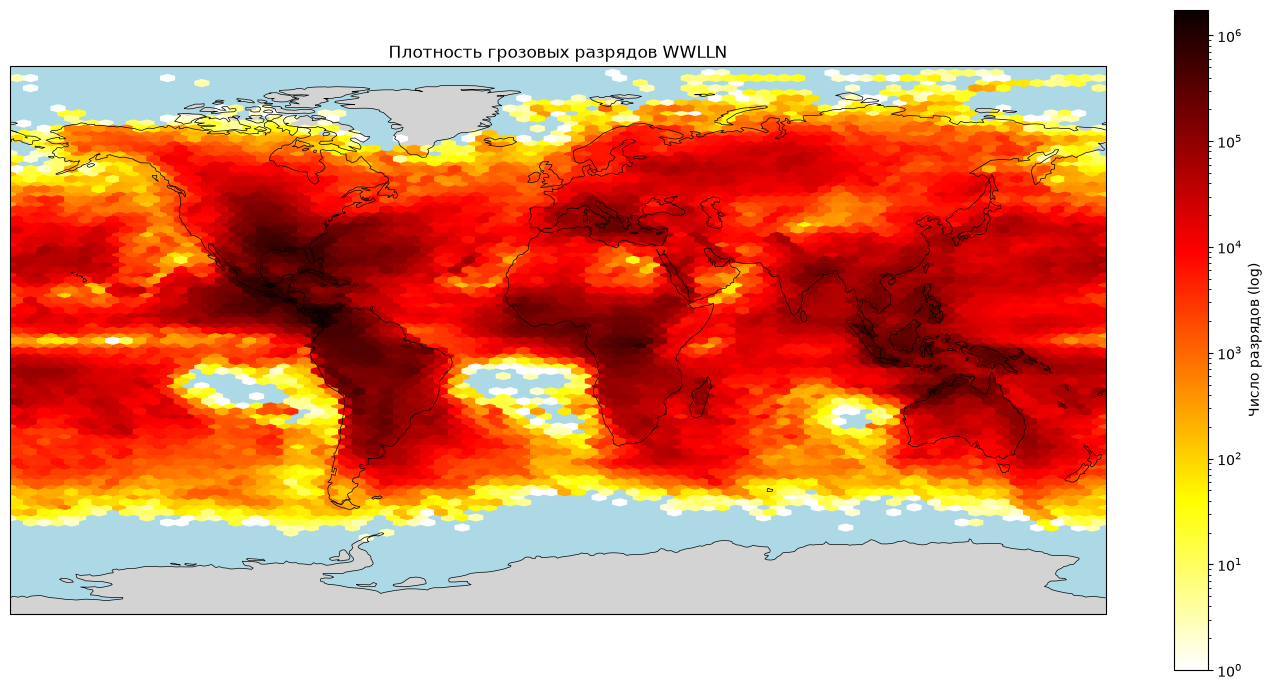

CPU times: user 13.9 s, sys: 40.1 s, total: 54 s
Wall time: 1min 57s


In [36]:
%%time
import matplotlib.pyplot as plt

if df.empty:
    raise ValueError('Сначала загрузите данные в ячейке выше (df)')

fig, ax = plt.subplots(figsize=(14, 7))

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    fig.clf()
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.set_global()
    transform = ccrs.PlateCarree()
except ImportError:
    print('cartopy не установлен — строим простую карту без береговой линии')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xlabel('Долгота')
    ax.set_ylabel('Широта')
    transform = None

hb = ax.hexbin(
    df['lon'], df['lat'],
    gridsize=80,
    bins='log',
    cmap='hot_r',
    mincnt=1,
    transform=transform,
)
plt.colorbar(hb, ax=ax, label='Число разрядов (log)')
ax.set_title('Плотность грозовых разрядов WWLLN')
plt.tight_layout()
plt.show()


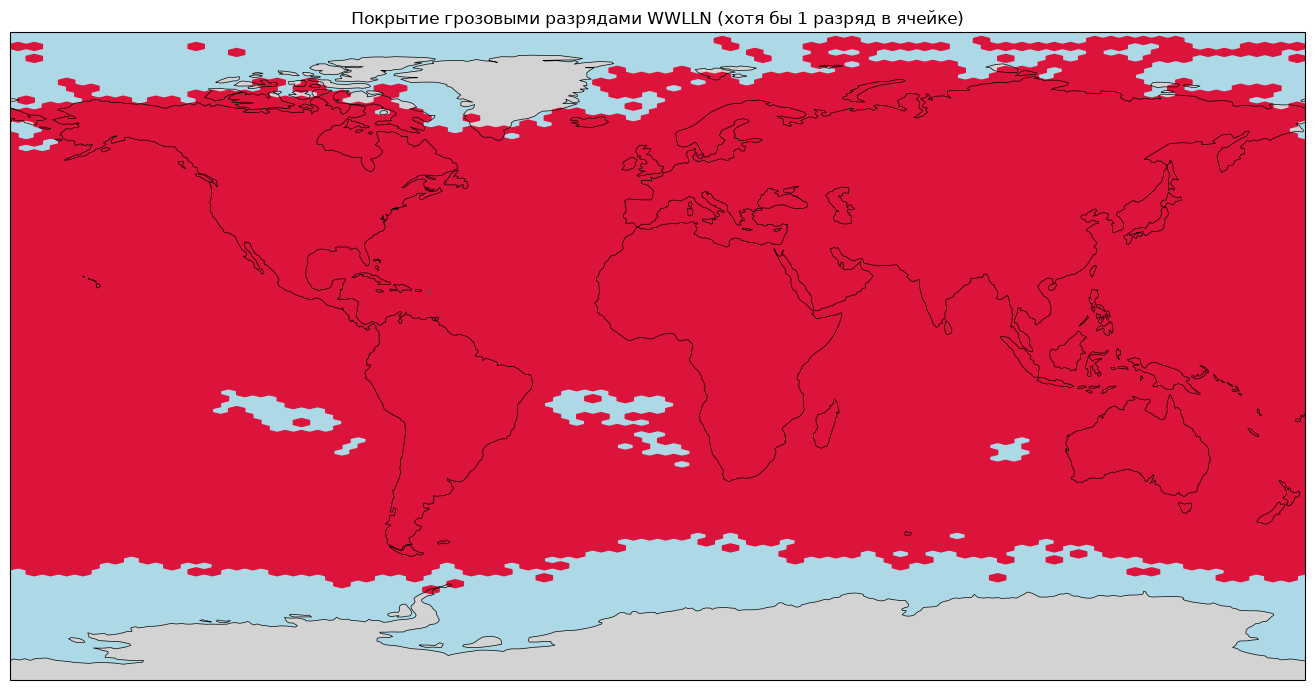

CPU times: user 14.8 s, sys: 39.1 s, total: 53.9 s
Wall time: 1min 56s


In [6]:
%%time
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

if df.empty:
    raise ValueError('Сначала загрузите данные в ячейке выше (df)')

fig, ax = plt.subplots(figsize=(14, 7))

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    fig.clf()
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.set_global()
    transform = ccrs.PlateCarree()
except ImportError:
    print('cartopy не установлен — строим простую карту без береговой линии')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xlabel('Долгота')
    ax.set_ylabel('Широта')
    transform = None

# Та же сетка (gridsize=80), что и на карте плотности выше, но без градации
# по числу разрядов в ячейке — cmap из одного цвета делает результат бинарным:
# ячейка закрашена, если разрядов >= mincnt (т.е. была хотя бы одна фиксация),
# и совсем не закрашена иначе. Число разрядов внутри ячейки значения не имеет.
ax.hexbin(
    df['lon'], df['lat'],
    gridsize=80,
    cmap=ListedColormap(['crimson']),
    mincnt=1,
    transform=transform,
)
ax.set_title('Покрытие грозовыми разрядами WWLLN (хотя бы 1 разряд в ячейке)')
plt.tight_layout()
plt.show()

## Анализ разрядов

Где и когда происходят разряды из `df` (AE за 2025 год). Сезон считается по месяцу и по полушарию: в июле на севере лето, на юге зима.

Суммы считаются чанками, без копии всей таблицы.

Дальше по ячейкам:

- суточный ход по сезонам, север и юг на общей шкале;
- число разрядов по месяцам и по широтным поясам;
- Ховмёллер широта × местный час и долгота × местный час (местный час = UTC + долгота/15);
- сколько разрядов имеют оценку энергии и как `energy > 0` распределена.


Разрядов: 254,128,337. Агрегация чанками по 10,000,000...
  ... 10,000,000/254,128,337
  ... 210,000,000/254,128,337
Сезоны (разрядов): {'зима': 27967943, 'весна': 58800490, 'лето': 93786965, 'осень': 73572939}
Пик медианы суточного хода: час 17 (медиана=42561)


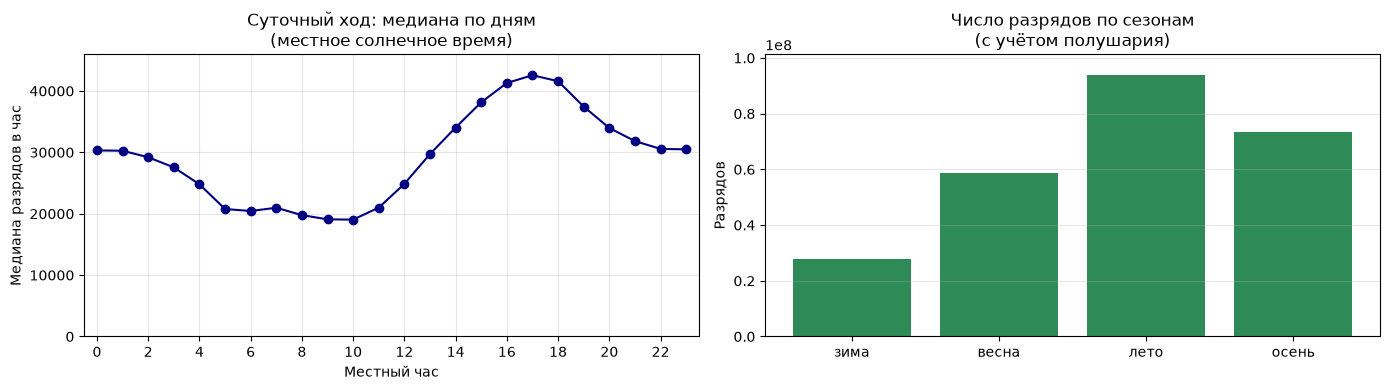

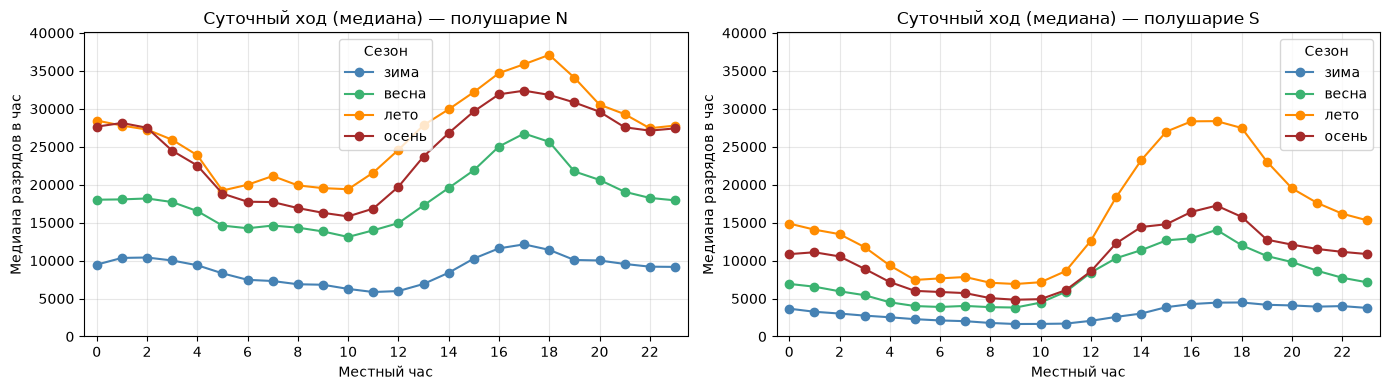

Готово.


In [ ]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')

_season_n = np.array([
    '', 'зима', 'зима', 'весна', 'весна', 'весна',
    'лето', 'лето', 'лето', 'осень', 'осень', 'осень', 'зима',
], dtype=object)
_season_s = np.array([
    '', 'лето', 'лето', 'осень', 'осень', 'осень',
    'зима', 'зима', 'зима', 'весна', 'весна', 'весна', 'лето',
], dtype=object)

season_order = ['зима', 'весна', 'лето', 'осень']
colors = {'зима': 'steelblue', 'весна': 'mediumseagreen', 'лето': 'darkorange', 'осень': 'brown'}

CHUNK = 10_000_000
n = len(df)
print(f'Разрядов: {n:,}. Агрегация чанками по {CHUNK:,}...')

parts_all = []
parts_hem = []

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    dt = df['datetime'].iloc[start:stop]
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)

    hour_utc = (
        dt.dt.hour.to_numpy(dtype=np.float64)
        + dt.dt.minute.to_numpy(dtype=np.float64) / 60.0
        + dt.dt.second.to_numpy(dtype=np.float64) / 3600.0
    )
    local_hour = np.floor(np.mod(hour_utc + lon / 15.0, 24.0)).astype(np.int8)

    utc_ns = dt.to_numpy(dtype='datetime64[ns]').astype(np.int64)
    offset_ns = (lon / 15.0 * 3_600_000_000_000.0).astype(np.int64)
    local_date = pd.to_datetime(utc_ns + offset_ns, unit='ns').floor('D')

    hem = np.where(lat >= 0, 'N', 'S')
    month = dt.dt.month.to_numpy()
    season = np.where(hem == 'N', _season_n[month], _season_s[month])

    tmp = pd.DataFrame({
        'local_date': local_date,
        'local_hour': local_hour,
        'hemisphere': pd.Categorical(hem, categories=['N', 'S']),
        'season': pd.Categorical(season, categories=season_order),
    })
    parts_all.append(tmp.groupby(['local_date', 'local_hour'], sort=False, observed=True).size())
    parts_hem.append(
        tmp.groupby(['hemisphere', 'season', 'local_date', 'local_hour'], sort=False, observed=True).size()
    )

    del dt, lat, lon, hour_utc, local_hour, utc_ns, offset_ns, local_date, hem, month, season, tmp
    if (start // CHUNK) % 20 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()

by_day_hour = pd.concat(parts_all).groupby(level=[0, 1]).sum()
by_day_hour.index = by_day_hour.index.set_names(['local_date', 'local_hour'])

by_hem_season_day_hour = pd.concat(parts_hem).groupby(level=[0, 1, 2, 3]).sum()
by_hem_season_day_hour.index = by_hem_season_day_hour.index.set_names(
    ['hemisphere', 'season', 'local_date', 'local_hour']
)
del parts_all, parts_hem
gc.collect()

hourly_median = (
    by_day_hour.groupby(level='local_hour').median()
    .reindex(range(24))
    .astype(float)
)
by_season_day_hour = by_hem_season_day_hour.groupby(level=['season', 'local_date', 'local_hour']).sum()
season_counts = by_hem_season_day_hour.groupby(level='season').sum().reindex(season_order).fillna(0)

print('Сезоны (разрядов):', {s: int(season_counts.loc[s]) for s in season_order})
print(f'Пик медианы суточного хода: час {hourly_median.idxmax()} (медиана={hourly_median.max():.0f})')


def _series_24(series):
    s = series.reindex(range(24)).astype(float)
    return s.replace([np.inf, -np.inf], np.nan).fillna(0.0)


def _plot_hourly(ax, series, label=None, color=None):
    s = _series_24(series)
    ax.plot(np.arange(24), s.to_numpy(), marker='o', label=label, color=color)


def _lines_ymax(*axes):
    ymax = 0.0
    for ax in axes:
        for line in ax.get_lines():
            y = np.asarray(line.get_ydata(), dtype=float)
            y = y[np.isfinite(y)]
            if y.size:
                ymax = max(ymax, float(y.max()))
    if not np.isfinite(ymax) or ymax <= 0:
        ymax = 1.0
    return ymax


def _finish_hourly_ax(ax, title, legend=False, ymax=None):
    if ymax is None:
        ymax = _lines_ymax(ax)
    ax.set_xlim(-0.5, 23.5)
    ax.set_xticks(list(range(0, 24, 2)))
    ax.set_ylim(0.0, float(ymax) * 1.08)
    ax.set_title(title)
    ax.set_xlabel('Местный час')
    ax.set_ylabel('Медиана разрядов в час')
    ax.grid(alpha=0.3)
    if legend and ax.get_lines():
        ax.legend(title='Сезон')


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
_plot_hourly(axes[0], hourly_median, color='navy')
_finish_hourly_ax(axes[0], 'Суточный ход: медиана по дням\n(местное солнечное время)')

bar_vals = np.nan_to_num(np.array([float(season_counts.loc[s]) for s in season_order], dtype=float), nan=0.0)
axes[1].bar(list(season_order), bar_vals, color='seagreen')
axes[1].set_title('Число разрядов по сезонам\n(с учётом полушария)')
axes[1].set_ylabel('Разрядов')
axes[1].set_ylim(0.0, max(float(bar_vals.max()) * 1.08, 1.0))
axes[1].grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()
plt.close(fig)

# Суточный ход по сезонам отдельно для N и S — общая шкала Y
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, hem in zip(axes, ['N', 'S']):
    for season in season_order:
        try:
            sub = by_hem_season_day_hour.xs((hem, season), level=['hemisphere', 'season'])
        except KeyError:
            continue
        med = sub.groupby(level='local_hour').median()
        _plot_hourly(ax, med, label=season, color=colors[season])

ymax = _lines_ymax(*axes)
for ax, hem in zip(axes, ['N', 'S']):
    _finish_hourly_ax(ax, f'Суточный ход (медиана) — полушарие {hem}', legend=True, ymax=ymax)
fig.tight_layout()
plt.show()
plt.close(fig)

df_season_hourly = by_hem_season_day_hour


Ячейка 10: агрегация 254,128,337 разрядов чанками по 5,000,000...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337


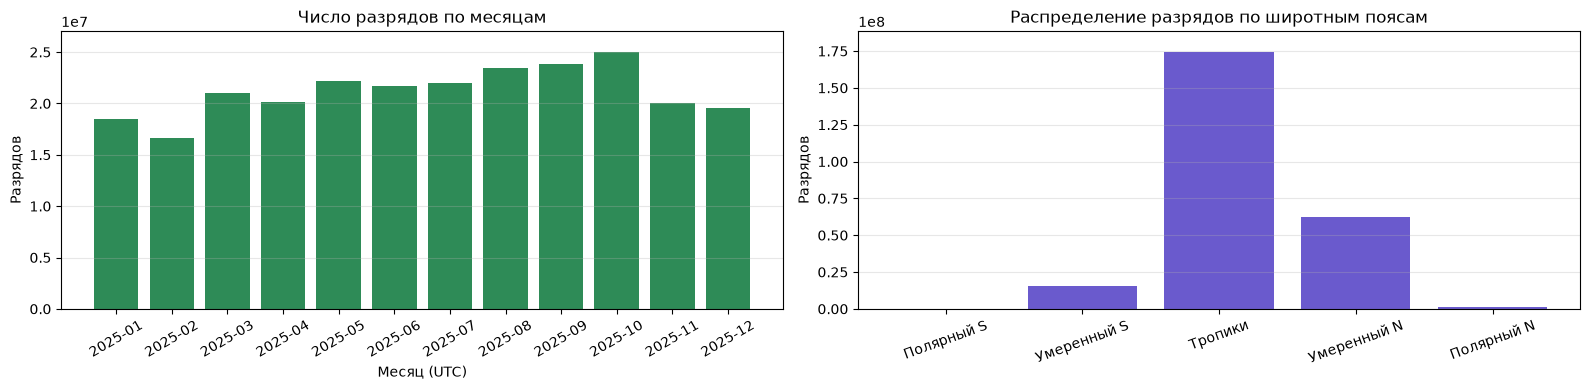

Готово.


In [ ]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')

# Без df_plot / copy: считаем агрегаты чанками
CHUNK = 5_000_000
n = len(df)
print(f'Ячейка 10: агрегация {n:,} разрядов чанками по {CHUNK:,}...')

month_counts = {}
lat_bands = [
    ('Полярный S', -90, -60),
    ('Умеренный S', -60, -23.5),
    ('Тропики', -23.5, 23.5),
    ('Умеренный N', 23.5, 60),
    ('Полярный N', 60, 90),
]
band_counts = np.zeros(len(lat_bands), dtype=np.int64)

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    dt = df['datetime'].iloc[start:stop]
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)

    months = dt.dt.to_period('M').astype(str)
    vc = months.value_counts()
    for m, c in vc.items():
        month_counts[m] = month_counts.get(m, 0) + int(c)

    for i, (_, lat_min, lat_max) in enumerate(lat_bands):
        if i < len(lat_bands) - 1:
            band_counts[i] += int(((lat >= lat_min) & (lat < lat_max)).sum())
        else:
            band_counts[i] += int(((lat >= lat_min) & (lat <= lat_max)).sum())

    del dt, lat, months, vc
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()

monthly = pd.Series(month_counts).sort_index()
band_labels = [b[0] for b in lat_bands]

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

axes[0].bar(monthly.index.astype(str), monthly.values, color='seagreen')
axes[0].set_title('Число разрядов по месяцам')
axes[0].set_xlabel('Месяц (UTC)')
axes[0].set_ylabel('Разрядов')
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylim(0.0, max(float(monthly.max()) * 1.08, 1.0))
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(band_labels, band_counts, color='slateblue')
axes[1].set_title('Распределение разрядов по широтным поясам')
axes[1].set_ylabel('Разрядов')
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_ylim(0.0, max(float(band_counts.max()) * 1.08, 1.0))
axes[1].grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()
plt.close(fig)


Hovmöller: агрегация 254,128,337 разрядов чанками по 5,000,000...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337


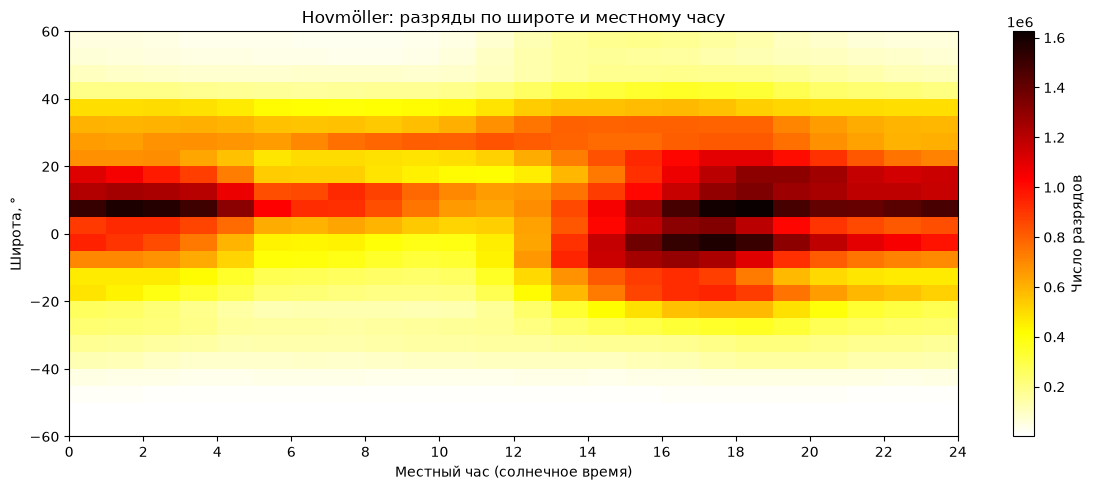

Готово. Всего в гистограмме: 252,594,159 разрядов


In [ ]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')

# Hovmöller: широта vs местный час (LST = UTC + lon/15), без df_plot
lat_bins = np.arange(-60, 61, 5)
hour_bins = np.arange(0, 25)
counts = np.zeros((len(lat_bins) - 1, len(hour_bins) - 1), dtype=np.float64)

CHUNK = 5_000_000
n = len(df)
print(f'Hovmöller: агрегация {n:,} разрядов чанками по {CHUNK:,}...')

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    dt = df['datetime'].iloc[start:stop]
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)

    hour_utc = (
        dt.dt.hour.to_numpy(dtype=np.float64)
        + dt.dt.minute.to_numpy(dtype=np.float64) / 60.0
        + dt.dt.second.to_numpy(dtype=np.float64) / 3600.0
    )
    local_hour = np.mod(hour_utc + lon / 15.0, 24.0)

    # только полоса широт гистограммы
    mask = (lat >= lat_bins[0]) & (lat < lat_bins[-1])
    if mask.any():
        part, _, _ = np.histogram2d(
            lat[mask], local_hour[mask],
            bins=[lat_bins, hour_bins],
        )
        counts += part

    del dt, lat, lon, hour_utc, local_hour, mask
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(
    counts,
    aspect='auto',
    origin='lower',
    cmap='hot_r',
    extent=[0, 24, lat_bins[0], lat_bins[-1]],
)
ax.set_title('Hovmöller: разряды по широте и местному часу')
ax.set_xlabel('Местный час (солнечное время)')
ax.set_ylabel('Широта, °')
ax.set_xticks(range(0, 25, 2))
plt.colorbar(im, ax=ax, label='Число разрядов')
fig.tight_layout()
plt.show()
plt.close(fig)


Hovmöller (lon): агрегация 254,128,337 разрядов чанками по 5,000,000...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337


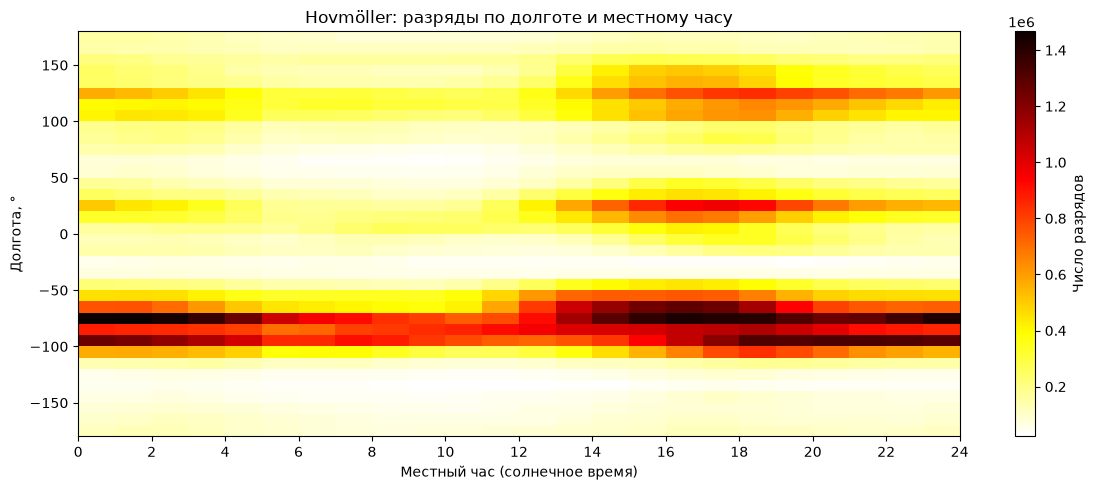

Готово. Всего в гистограмме: 254,128,322 разрядов


In [20]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')

# Hovmöller: долгота vs местный час (LST = UTC + lon/15)
lon_bins = np.arange(-180, 181, 10)
hour_bins = np.arange(0, 25)
counts = np.zeros((len(lon_bins) - 1, len(hour_bins) - 1), dtype=np.float64)

CHUNK = 5_000_000
n = len(df)
print(f'Hovmöller (lon): агрегация {n:,} разрядов чанками по {CHUNK:,}...')

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    dt = df['datetime'].iloc[start:stop]
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)

    hour_utc = (
        dt.dt.hour.to_numpy(dtype=np.float64)
        + dt.dt.minute.to_numpy(dtype=np.float64) / 60.0
        + dt.dt.second.to_numpy(dtype=np.float64) / 3600.0
    )
    local_hour = np.mod(hour_utc + lon / 15.0, 24.0)

    mask = (lon >= lon_bins[0]) & (lon < lon_bins[-1])
    if mask.any():
        part, _, _ = np.histogram2d(
            lon[mask], local_hour[mask],
            bins=[lon_bins, hour_bins],
        )
        counts += part

    del dt, lon, hour_utc, local_hour, mask
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(
    counts,
    aspect='auto',
    origin='lower',
    cmap='hot_r',
    extent=[0, 24, lon_bins[0], lon_bins[-1]],
)
ax.set_title('Hovmöller: разряды по долготе и местному часу')
ax.set_xlabel('Местный час (солнечное время)')
ax.set_ylabel('Долгота, °')
ax.set_xticks(range(0, 25, 2))
plt.colorbar(im, ax=ax, label='Число разрядов')
fig.tight_layout()
plt.show()
plt.close(fig)
print(f'Всего в гистограмме: {int(counts.sum()):,} разрядов')


Энергия: агрегация 254,128,337 разрядов...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337
Всего: 254,128,337
energy == 0: 7,612,603 (3.0%)  |  energy > 0: 246,515,734 (97.0%)
mean(all)=3566.1 J  |  mean(>0)=3676.2 J
median(>0)≈1122.0 J  |  p90≈7079.5 J  |  p99≈35481.3 J


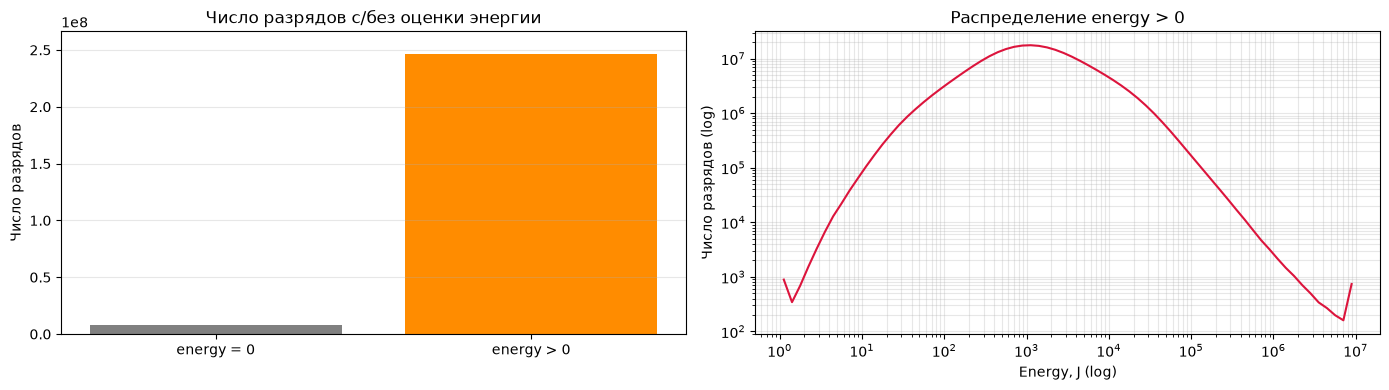

In [94]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')
if 'energy' not in df.columns:
    raise ValueError('В df нет колонки energy — загрузите AE-файлы')

# Распределение энергии (чанками)
CHUNK = 5_000_000
n = len(df)
print(f'Энергия: агрегация {n:,} разрядов...')

e_edges = np.logspace(0, 7, 71)  # 1 .. 1e7 J
hist_pos = np.zeros(len(e_edges) - 1, dtype=np.float64)
n_total = n_zero = n_pos = 0
sum_e = sum_e_pos = 0.0

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    n_total += e.size
    zero = e <= 0
    n_zero += int(zero.sum())
    pos = e[~zero]
    n_pos += pos.size
    sum_e += float(np.nansum(e))
    if pos.size:
        sum_e_pos += float(pos.sum())
        hist_pos += np.histogram(np.clip(pos, e_edges[0], e_edges[-1]), bins=e_edges)[0]
    del e, zero, pos
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()

pct_zero = 100.0 * n_zero / n_total
pct_pos = 100.0 * n_pos / n_total
print(f'Всего: {n_total:,}')
print(f'energy == 0: {n_zero:,} ({pct_zero:.1f}%)  |  energy > 0: {n_pos:,} ({pct_pos:.1f}%)')
print(f'mean(all)={sum_e / n_total:.1f} J  |  mean(>0)={sum_e_pos / max(n_pos, 1):.1f} J')

centers = np.sqrt(e_edges[:-1] * e_edges[1:])
if hist_pos.sum() > 0:
    cdf = np.cumsum(hist_pos)
    cdf /= cdf[-1]

    def _q(p):
        i = int(np.searchsorted(cdf, p))
        i = min(max(i, 0), len(centers) - 1)
        return float(centers[i])

    print(f'median(>0)≈{_q(0.5):.1f} J  |  p90≈{_q(0.9):.1f} J  |  p99≈{_q(0.99):.1f} J')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(['energy = 0', 'energy > 0'], [n_zero, n_pos], color=['gray', 'darkorange'])
axes[0].set_title('Число разрядов с/без оценки энергии')
axes[0].set_ylabel('Число разрядов')
axes[0].set_ylim(0.0, max(n_zero, n_pos) * 1.08)
axes[0].grid(axis='y', alpha=0.3)

axes[1].plot(centers, hist_pos, color='crimson')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Energy, J (log)')
axes[1].set_ylabel('Число разрядов (log)')
axes[1].set_title('Распределение energy > 0')
axes[1].grid(alpha=0.3, which='both')

fig.tight_layout()
plt.show()
plt.close(fig)


## Медиана энергии

Те же разрезы, что у числа разрядов, но для медианы `energy` при `energy > 0`. Медиана приближённая: лог-гистограмма копится чанками, без копии `df`.

Порядок рисунков: карта на сетке долгота×широта, сезоны, месяцы и широтные пояса, Ховмёллер широта×местный час, долгота×местный час, широта×долгота.


Карта медианы energy: 254,128,337 разрядов...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337
Ячеек с energy>0: 11,603  |  глобальная медиана≈1412.5 J


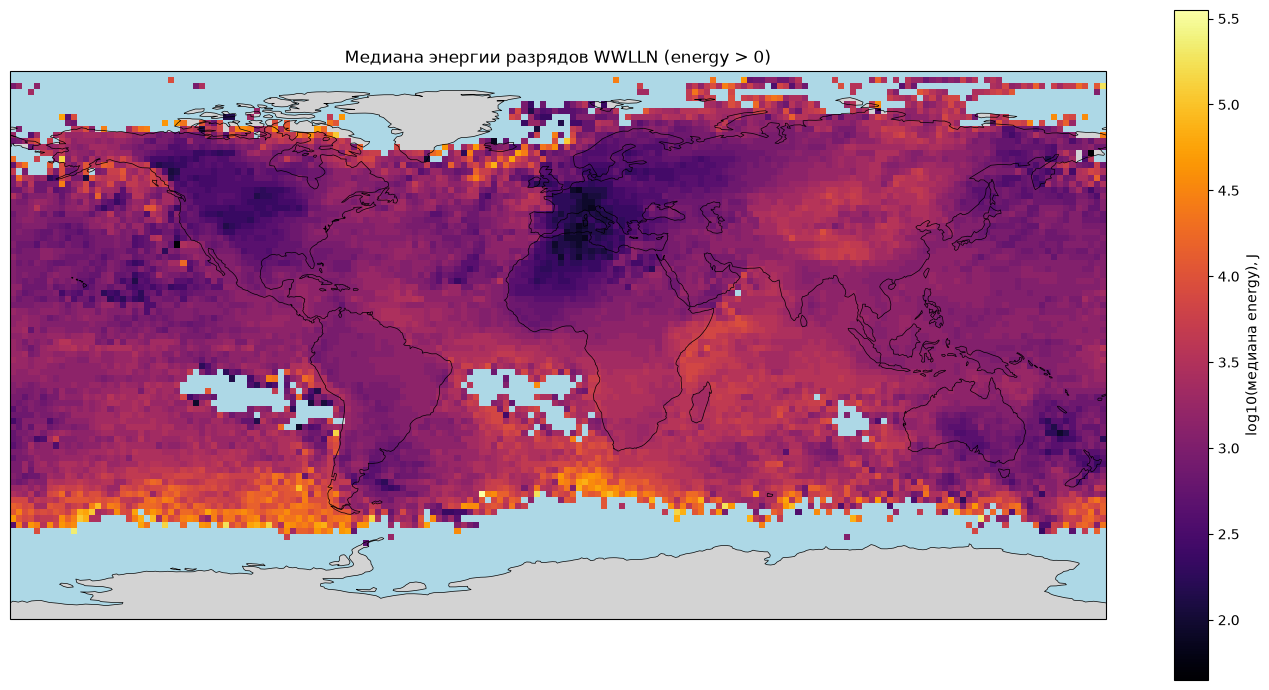

4730

In [29]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')
if 'energy' not in df.columns:
    raise ValueError('В df нет колонки energy — загрузите AE-файлы')

# Карта: медиана энергии на сетке lon×lat (только energy > 0)
E_EDGES = np.logspace(0, 7, 71)
E_CENTERS = np.sqrt(E_EDGES[:-1] * E_EDGES[1:])
lon_bins = np.arange(-180, 181, 2)
lat_bins = np.arange(-90, 91, 2)
# shape: (n_lon, n_lat, n_e)
hist_map = np.zeros((len(lon_bins) - 1, len(lat_bins) - 1, len(E_EDGES) - 1), dtype=np.float64)

CHUNK = 5_000_000
n = len(df)
print(f'Карта медианы energy: {n:,} разрядов...')

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    m = e > 0
    if m.any():
        ee = np.clip(e[m], E_EDGES[0], E_EDGES[-1])
        part, _ = np.histogramdd(
            np.column_stack([lon[m], lat[m], ee]),
            bins=[lon_bins, lat_bins, E_EDGES],
        )
        hist_map += part
    del lon, lat, e, m
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()


def _median_from_hists(hists, centers):
    cdf = np.cumsum(hists, axis=-1)
    totals = cdf[..., -1]
    half = totals[..., None] * 0.5
    idx = np.argmax(cdf >= half, axis=-1)
    med = centers[idx]
    return np.where(totals > 0, med, np.nan)


med_map = _median_from_hists(hist_map, E_CENTERS)
n_cells = int(np.isfinite(med_map).sum())
print(f'Ячеек с energy>0: {n_cells:,}  |  глобальная медиана≈{np.nanmedian(med_map):.1f} J')

fig, ax = plt.subplots(figsize=(14, 7))
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    fig.clf()
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.set_global()
except ImportError:
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xlabel('Долгота')
    ax.set_ylabel('Широта')

LON, LAT = np.meshgrid(lon_bins, lat_bins, indexing='ij')
pcm = ax.pcolormesh(
    LON, LAT, np.log10(med_map),
    cmap='inferno', shading='flat',
)
cb = plt.colorbar(pcm, ax=ax, label='log10(медиана energy), J')
ax.set_title('Медиана энергии разрядов WWLLN (energy > 0)')
fig.tight_layout()
plt.show()
plt.close(fig)
del hist_map
gc.collect()


Медиана energy — суточный ход: 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337
Медиана energy по сезонам, J: {'зима': '891.3', 'весна': '1122.0', 'лето': '1122.0', 'осень': '1122.0'}


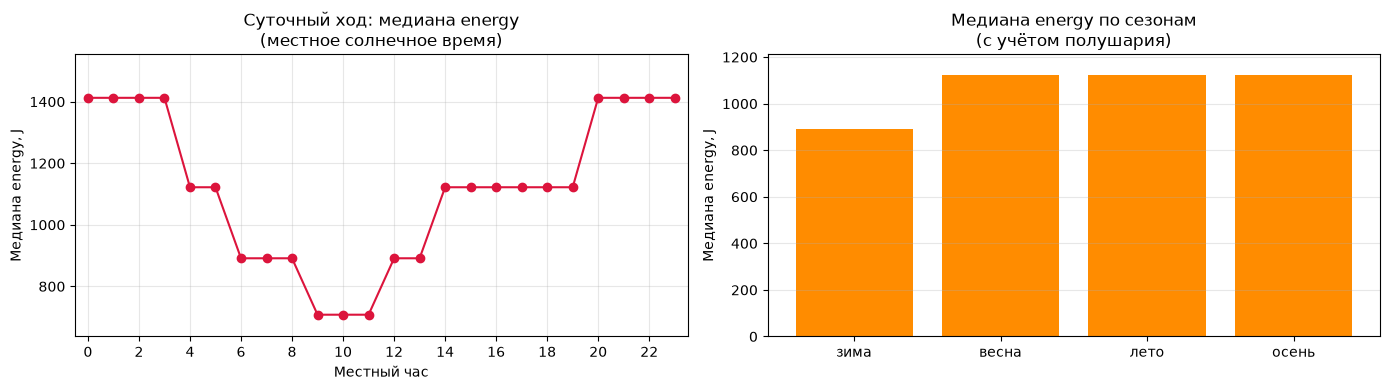

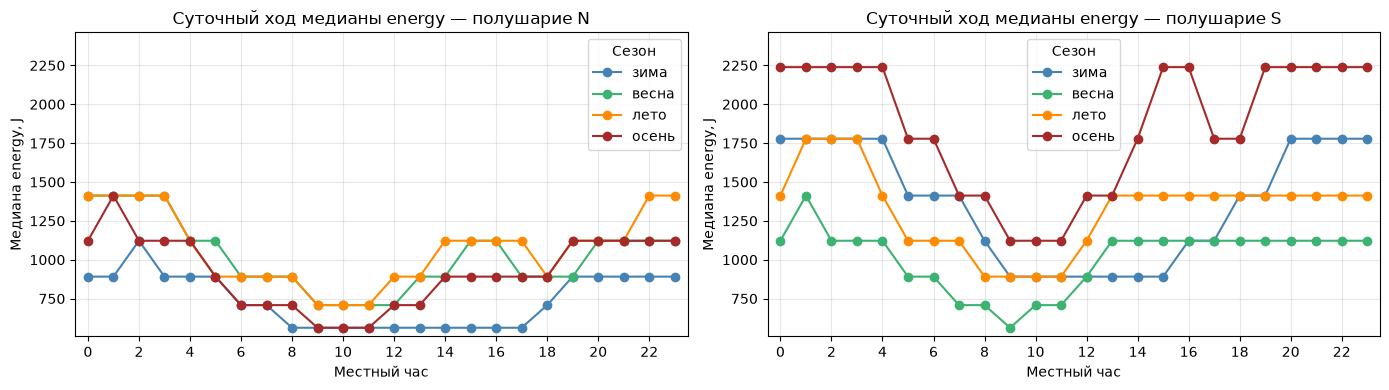

In [30]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')
if 'energy' not in df.columns:
    raise ValueError('В df нет колонки energy — загрузите AE-файлы')

# Суточный ход / сезоны: медиана energy (pooled, energy > 0)
_season_n = np.array([
    '', 'зима', 'зима', 'весна', 'весна', 'весна',
    'лето', 'лето', 'лето', 'осень', 'осень', 'осень', 'зима',
], dtype=object)
_season_s = np.array([
    '', 'лето', 'лето', 'осень', 'осень', 'осень',
    'зима', 'зима', 'зима', 'весна', 'весна', 'весна', 'лето',
], dtype=object)
season_order = ['зима', 'весна', 'лето', 'осень']
colors = {'зима': 'steelblue', 'весна': 'mediumseagreen', 'лето': 'darkorange', 'осень': 'brown'}
season_to_i = {s: i for i, s in enumerate(season_order)}

E_EDGES = np.logspace(0, 7, 71)
E_CENTERS = np.sqrt(E_EDGES[:-1] * E_EDGES[1:])
n_e = len(E_EDGES) - 1

# hour; season; hem×season×hour
hist_hour = np.zeros((24, n_e), dtype=np.float64)
hist_season = np.zeros((4, n_e), dtype=np.float64)
hist_hsh = np.zeros((2, 4, 24, n_e), dtype=np.float64)  # N/S, season, hour

CHUNK = 5_000_000
n = len(df)
print(f'Медиана energy — суточный ход: {n:,}...')

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    dt = df['datetime'].iloc[start:stop]
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    m = e > 0
    if not m.any():
        continue
    lat, lon, e = lat[m], lon[m], e[m]
    dt = dt[m]
    ee = np.clip(e, E_EDGES[0], E_EDGES[-1])
    e_bin = np.searchsorted(E_EDGES, ee, side='right') - 1
    e_bin = np.clip(e_bin, 0, n_e - 1)

    hour_utc = (
        dt.dt.hour.to_numpy(dtype=np.float64)
        + dt.dt.minute.to_numpy(dtype=np.float64) / 60.0
        + dt.dt.second.to_numpy(dtype=np.float64) / 3600.0
    )
    local_hour = np.floor(np.mod(hour_utc + lon / 15.0, 24.0)).astype(np.int16)
    local_hour = np.clip(local_hour, 0, 23)

    hem_i = (lat < 0).astype(np.int8)  # 0=N, 1=S
    month = dt.dt.month.to_numpy()
    season = np.where(hem_i == 0, _season_n[month], _season_s[month])
    season_i = np.empty(season.size, dtype=np.int8)
    for s, si in season_to_i.items():
        season_i[season == s] = si

    np.add.at(hist_hour, (local_hour, e_bin), 1)
    np.add.at(hist_season, (season_i, e_bin), 1)
    np.add.at(hist_hsh, (hem_i, season_i, local_hour, e_bin), 1)

    del dt, lat, lon, e, m, ee, e_bin, hour_utc, local_hour, hem_i, month, season, season_i
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()


def _median_from_hists(hists, centers):
    cdf = np.cumsum(hists, axis=-1)
    totals = cdf[..., -1]
    half = totals[..., None] * 0.5
    idx = np.argmax(cdf >= half, axis=-1)
    med = centers[idx]
    return np.where(totals > 0, med, np.nan)


med_hour = _median_from_hists(hist_hour, E_CENTERS)
med_season = _median_from_hists(hist_season, E_CENTERS)
med_hsh = _median_from_hists(hist_hsh, E_CENTERS)

print('Медиана energy по сезонам, J:', {s: (f'{med_season[i]:.1f}' if np.isfinite(med_season[i]) else 'nan') for i, s in enumerate(season_order)})


def _finish_hourly_ax(ax, title, legend=False, ymax=None, ymin=None):
    ax.set_xlim(-0.5, 23.5)
    ax.set_xticks(list(range(0, 24, 2)))
    if ymax is not None and ymin is not None:
        ax.set_ylim(ymin, ymax)
    ax.set_title(title)
    ax.set_xlabel('Местный час')
    ax.set_ylabel('Медиана energy, J')
    ax.grid(alpha=0.3)
    if legend and ax.get_lines():
        ax.legend(title='Сезон')


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(np.arange(24), med_hour, marker='o', color='crimson')
finite = med_hour[np.isfinite(med_hour)]
y0, y1 = (finite.min() * 0.9, finite.max() * 1.1) if finite.size else (0, 1)
_finish_hourly_ax(axes[0], 'Суточный ход: медиана energy\n(местное солнечное время)', ymin=y0, ymax=y1)

bar_vals = np.nan_to_num(med_season, nan=0.0)
axes[1].bar(list(season_order), bar_vals, color='darkorange')
axes[1].set_title('Медиана energy по сезонам\n(с учётом полушария)')
axes[1].set_ylabel('Медиана energy, J')
axes[1].set_ylim(0.0, max(float(bar_vals.max()) * 1.08, 1.0))
axes[1].grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
all_y = []
for ax, hem, hi in zip(axes, ['N', 'S'], [0, 1]):
    for si, season in enumerate(season_order):
        y = med_hsh[hi, si]
        ax.plot(np.arange(24), y, marker='o', label=season, color=colors[season])
        all_y.append(y[np.isfinite(y)])
finite_all = np.concatenate(all_y) if all_y else np.array([0.0, 1.0])
ymin, ymax = float(finite_all.min()) * 0.9, float(finite_all.max()) * 1.1
for ax, hem in zip(axes, ['N', 'S']):
    _finish_hourly_ax(ax, f'Суточный ход медианы energy — полушарие {hem}', legend=True, ymin=ymin, ymax=ymax)
fig.tight_layout()
plt.show()
plt.close(fig)


Медиана energy — месяцы/широты: 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337


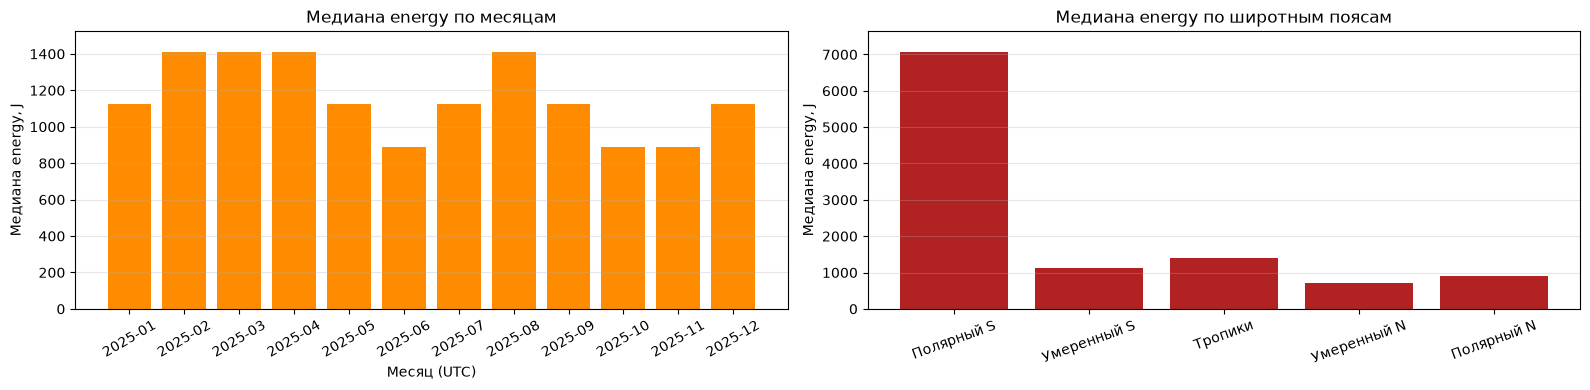

In [31]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')
if 'energy' not in df.columns:
    raise ValueError('В df нет колонки energy — загрузите AE-файлы')

E_EDGES = np.logspace(0, 7, 71)
E_CENTERS = np.sqrt(E_EDGES[:-1] * E_EDGES[1:])
n_e = len(E_EDGES) - 1

lat_bands = [
    ('Полярный S', -90, -60),
    ('Умеренный S', -60, -23.5),
    ('Тропики', -23.5, 23.5),
    ('Умеренный N', 23.5, 60),
    ('Полярный N', 60, 90),
]
hist_month = {}  # month_str -> hist
hist_band = np.zeros((len(lat_bands), n_e), dtype=np.float64)

CHUNK = 5_000_000
n = len(df)
print(f'Медиана energy — месяцы/широты: {n:,}...')

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    dt = df['datetime'].iloc[start:stop]
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    m = e > 0
    if not m.any():
        continue
    lat, e = lat[m], e[m]
    dt = dt[m]
    ee = np.clip(e, E_EDGES[0], E_EDGES[-1])
    e_bin = np.clip(np.searchsorted(E_EDGES, ee, side='right') - 1, 0, n_e - 1)

    months = dt.dt.to_period('M').astype(str).to_numpy()
    for mo in np.unique(months):
        sel = months == mo
        if mo not in hist_month:
            hist_month[mo] = np.zeros(n_e, dtype=np.float64)
        np.add.at(hist_month[mo], e_bin[sel], 1)

    for i, (_, lat_min, lat_max) in enumerate(lat_bands):
        if i < len(lat_bands) - 1:
            sel = (lat >= lat_min) & (lat < lat_max)
        else:
            sel = (lat >= lat_min) & (lat <= lat_max)
        if sel.any():
            np.add.at(hist_band[i], e_bin[sel], 1)

    del dt, lat, e, m, ee, e_bin, months
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()


def _median_from_hists(hists, centers):
    cdf = np.cumsum(hists, axis=-1)
    totals = cdf[..., -1]
    half = totals[..., None] * 0.5
    idx = np.argmax(cdf >= half, axis=-1)
    med = centers[idx]
    return np.where(totals > 0, med, np.nan)


months_sorted = sorted(hist_month.keys())
med_month = pd.Series(
    [_median_from_hists(hist_month[mo], E_CENTERS) for mo in months_sorted],
    index=months_sorted,
)
med_band = _median_from_hists(hist_band, E_CENTERS)
band_labels = [b[0] for b in lat_bands]

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(med_month.index.astype(str), med_month.values, color='darkorange')
axes[0].set_title('Медиана energy по месяцам')
axes[0].set_xlabel('Месяц (UTC)')
axes[0].set_ylabel('Медиана energy, J')
axes[0].tick_params(axis='x', rotation=30)
finite = med_month.to_numpy(dtype=float)
finite = finite[np.isfinite(finite)]
axes[0].set_ylim(0.0, max(float(finite.max()) * 1.08, 1.0) if finite.size else 1.0)
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(band_labels, med_band, color='firebrick')
axes[1].set_title('Медиана energy по широтным поясам')
axes[1].set_ylabel('Медиана energy, J')
axes[1].tick_params(axis='x', rotation=20)
finite_b = med_band[np.isfinite(med_band)]
axes[1].set_ylim(0.0, max(float(finite_b.max()) * 1.08, 1.0) if finite_b.size else 1.0)
axes[1].grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()
plt.close(fig)


Hovmöller медианы energy (lat): 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337


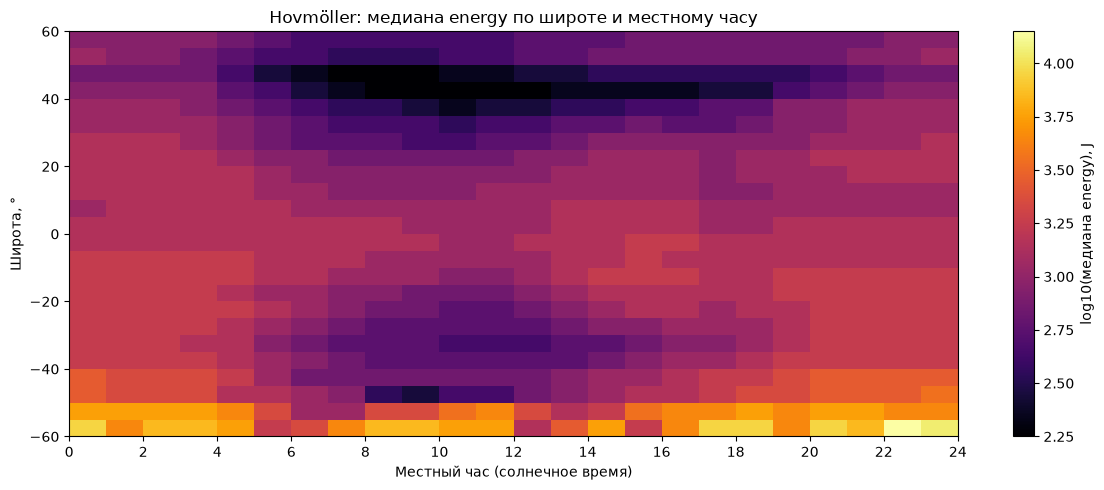

12408

In [32]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')
if 'energy' not in df.columns:
    raise ValueError('В df нет колонки energy — загрузите AE-файлы')

E_EDGES = np.logspace(0, 7, 71)
E_CENTERS = np.sqrt(E_EDGES[:-1] * E_EDGES[1:])
lat_bins = np.arange(-60, 61, 5)
hour_bins = np.arange(0, 25)
hist = np.zeros((len(lat_bins) - 1, len(hour_bins) - 1, len(E_EDGES) - 1), dtype=np.float64)

CHUNK = 5_000_000
n = len(df)
print(f'Hovmöller медианы energy (lat): {n:,}...')

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    dt = df['datetime'].iloc[start:stop]
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    m = (e > 0) & (lat >= lat_bins[0]) & (lat < lat_bins[-1])
    if m.any():
        hour_utc = (
            dt.dt.hour.to_numpy(dtype=np.float64)
            + dt.dt.minute.to_numpy(dtype=np.float64) / 60.0
            + dt.dt.second.to_numpy(dtype=np.float64) / 3600.0
        )
        local_hour = np.mod(hour_utc + lon / 15.0, 24.0)
        ee = np.clip(e[m], E_EDGES[0], E_EDGES[-1])
        part, _ = np.histogramdd(
            np.column_stack([lat[m], local_hour[m], ee]),
            bins=[lat_bins, hour_bins, E_EDGES],
        )
        hist += part
        del hour_utc, local_hour, ee, part
    del dt, lat, lon, e, m
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()


def _median_from_hists(hists, centers):
    cdf = np.cumsum(hists, axis=-1)
    totals = cdf[..., -1]
    half = totals[..., None] * 0.5
    idx = np.argmax(cdf >= half, axis=-1)
    med = centers[idx]
    return np.where(totals > 0, med, np.nan)


med = _median_from_hists(hist, E_CENTERS)
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(
    np.log10(med),
    aspect='auto',
    origin='lower',
    cmap='inferno',
    extent=[0, 24, lat_bins[0], lat_bins[-1]],
)
ax.set_title('Hovmöller: медиана energy по широте и местному часу')
ax.set_xlabel('Местный час (солнечное время)')
ax.set_ylabel('Широта, °')
ax.set_xticks(range(0, 25, 2))
plt.colorbar(im, ax=ax, label='log10(медиана energy), J')
fig.tight_layout()
plt.show()
plt.close(fig)
del hist
gc.collect()


Hovmöller медианы energy (lon): 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337


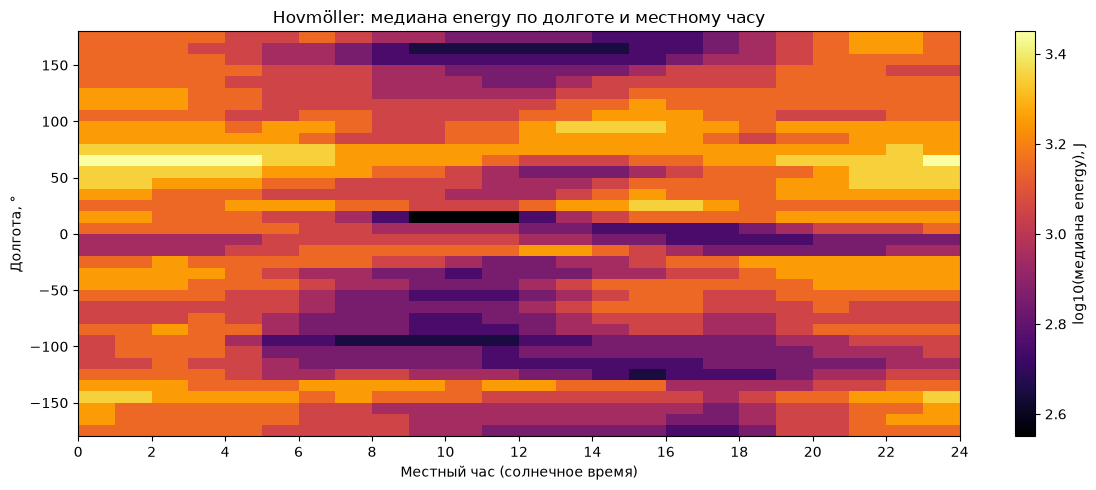

5143

In [33]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')
if 'energy' not in df.columns:
    raise ValueError('В df нет колонки energy — загрузите AE-файлы')

E_EDGES = np.logspace(0, 7, 71)
E_CENTERS = np.sqrt(E_EDGES[:-1] * E_EDGES[1:])
lon_bins = np.arange(-180, 181, 10)
hour_bins = np.arange(0, 25)
hist = np.zeros((len(lon_bins) - 1, len(hour_bins) - 1, len(E_EDGES) - 1), dtype=np.float64)

CHUNK = 5_000_000
n = len(df)
print(f'Hovmöller медианы energy (lon): {n:,}...')

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    dt = df['datetime'].iloc[start:stop]
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    m = (e > 0) & (lon >= lon_bins[0]) & (lon < lon_bins[-1])
    if m.any():
        hour_utc = (
            dt.dt.hour.to_numpy(dtype=np.float64)
            + dt.dt.minute.to_numpy(dtype=np.float64) / 60.0
            + dt.dt.second.to_numpy(dtype=np.float64) / 3600.0
        )
        local_hour = np.mod(hour_utc + lon / 15.0, 24.0)
        ee = np.clip(e[m], E_EDGES[0], E_EDGES[-1])
        part, _ = np.histogramdd(
            np.column_stack([lon[m], local_hour[m], ee]),
            bins=[lon_bins, hour_bins, E_EDGES],
        )
        hist += part
        del hour_utc, local_hour, ee, part
    del dt, lon, e, m
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()


def _median_from_hists(hists, centers):
    cdf = np.cumsum(hists, axis=-1)
    totals = cdf[..., -1]
    half = totals[..., None] * 0.5
    idx = np.argmax(cdf >= half, axis=-1)
    med = centers[idx]
    return np.where(totals > 0, med, np.nan)


med = _median_from_hists(hist, E_CENTERS)
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(
    np.log10(med),
    aspect='auto',
    origin='lower',
    cmap='inferno',
    extent=[0, 24, lon_bins[0], lon_bins[-1]],
)
ax.set_title('Hovmöller: медиана energy по долготе и местному часу')
ax.set_xlabel('Местный час (солнечное время)')
ax.set_ylabel('Долгота, °')
ax.set_xticks(range(0, 25, 2))
plt.colorbar(im, ax=ax, label='log10(медиана energy), J')
fig.tight_layout()
plt.show()
plt.close(fig)
del hist
gc.collect()


Hovmöller lat×lon (медиана energy): 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337


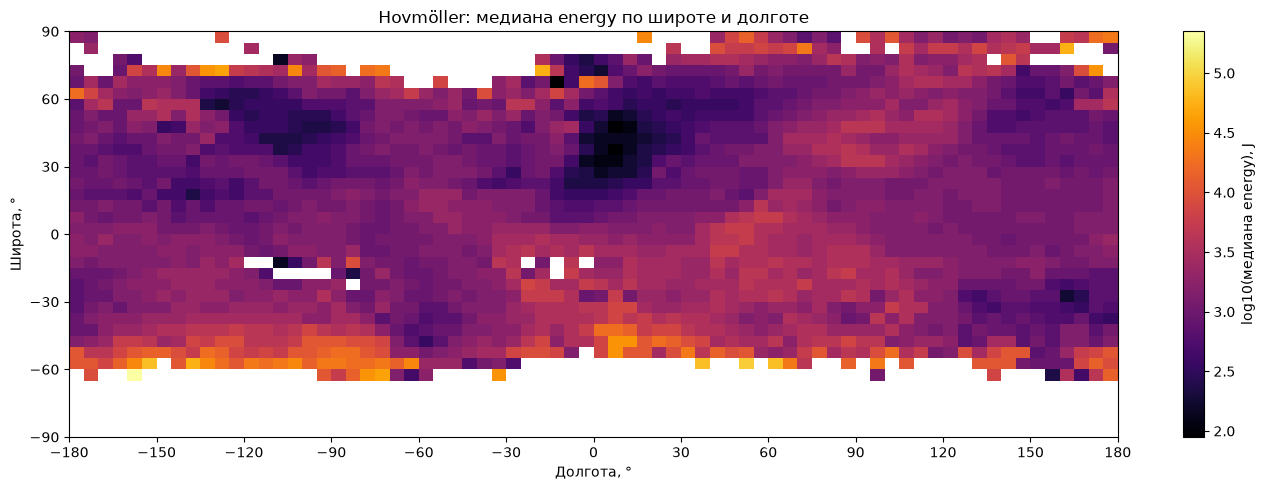

5125

In [34]:
import gc
import matplotlib.pyplot as plt

if 'df' not in dir() or df is None or getattr(df, 'empty', True):
    raise ValueError('Нет df в памяти — загрузите данные в ячейке 5')
if 'energy' not in df.columns:
    raise ValueError('В df нет колонки energy — загрузите AE-файлы')

# Hovmöller: широта × долгота (медиана energy > 0)
E_EDGES = np.logspace(0, 7, 71)
E_CENTERS = np.sqrt(E_EDGES[:-1] * E_EDGES[1:])
lon_bins = np.arange(-180, 181, 5)
lat_bins = np.arange(-90, 91, 5)
hist = np.zeros((len(lat_bins) - 1, len(lon_bins) - 1, len(E_EDGES) - 1), dtype=np.float64)

CHUNK = 5_000_000
n = len(df)
print(f'Hovmöller lat×lon (медиана energy): {n:,}...')

for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    m = e > 0
    if m.any():
        ee = np.clip(e[m], E_EDGES[0], E_EDGES[-1])
        part, _ = np.histogramdd(
            np.column_stack([lat[m], lon[m], ee]),
            bins=[lat_bins, lon_bins, E_EDGES],
        )
        hist += part
        del ee, part
    del lat, lon, e, m
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')
        gc.collect()


def _median_from_hists(hists, centers):
    cdf = np.cumsum(hists, axis=-1)
    totals = cdf[..., -1]
    half = totals[..., None] * 0.5
    idx = np.argmax(cdf >= half, axis=-1)
    med = centers[idx]
    return np.where(totals > 0, med, np.nan)


med = _median_from_hists(hist, E_CENTERS)
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(
    np.log10(med),
    aspect='auto',
    origin='lower',
    cmap='inferno',
    extent=[lon_bins[0], lon_bins[-1], lat_bins[0], lat_bins[-1]],
)
ax.set_title('Hovmöller: медиана energy по широте и долготе')
ax.set_xlabel('Долгота, °')
ax.set_ylabel('Широта, °')
ax.set_xticks(range(-180, 181, 30))
ax.set_yticks(range(-90, 91, 30))
plt.colorbar(im, ax=ax, label='log10(медиана energy), J')
fig.tight_layout()
plt.show()
plt.close(fig)
del hist
gc.collect()


## Предсказания свистов

Файлы `predictions/whistler_binary`. Время в файле — МСК, при загрузке переводится в UTC (минус 3 часа). Колонки, которые читаем: `timestamp, geo_lat, geo_lon, is_night, solar_zenith_angle, prob_whistle, verdict`. Магнитные широта и долгота в файле есть, в этот разбор не входят.

ka1 и ka2 грузятся в `df_pred` и рисуются раздельно: это разные аппараты, у них разное покрытие. Смотреть имеет смысл долю `verdict=1`, уже поделённую на экспозицию: сырое число свистов повторяет то, где спутник просто дольше находился.

После загрузки идут три рисунка ka1 и ka2, и следом те же три для ka4 (`df_pred_ka4`, свои файлы, `df_pred` не перезаписывается):

- суточный ход по местному солнечному времени: экспозиция, сырое число `verdict=1`, доля `verdict=1`;
- карта широта×долгота: экспозиция и доля;
- Ховмёллер доли свистов: широта×местный час и долгота×местный час.


In [7]:
%%time
from concurrent.futures import ThreadPoolExecutor

PRED_DIR = path_pred if 'path_pred' in dir() else (Path('.').resolve() / 'predictions' / 'whistler_binary')
PRED_MSK_OFFSET_HOURS = 3  # MSK = UTC+3
SC_LIST = ('ka1', 'ka2')  # бывшие sc1/sc2


def _read_pred_csv(filepath, sc: str):
    # mag_lat/mag_lon в файлах есть — пока не читаем.
    # prob_whistle нужен как непрерывный отклик: verdict = (prob >= 0.5), порог произвольный.
    d = pd.read_csv(
        filepath,
        usecols=['timestamp', 'geo_lat', 'geo_lon', 'is_night', 'solar_zenith_angle',
                 'prob_whistle', 'verdict'],
        dtype={
            'geo_lat': 'float32',
            'geo_lon': 'float32',
            'is_night': 'int8',
            'solar_zenith_angle': 'float32',
            'prob_whistle': 'float32',
            'verdict': 'int8',
        },
    )
    # файл в МСК → UTC
    d['timestamp'] = pd.to_datetime(d['timestamp'], utc=False) - pd.Timedelta(hours=PRED_MSK_OFFSET_HOURS)
    d['sc'] = sc
    return d


def load_predictions(sc_list=SC_LIST, n_jobs=8, max_files=None):
    parts = []
    for sc in sc_list:
        files = sorted((PRED_DIR / sc).glob(f'predictions_{sc}_fl_*.csv'))
        if max_files is not None:
            files = files[:max_files]
        print(f'{sc}: {len(files)} файлов из {PRED_DIR / sc}')
        if not files:
            continue
        with ThreadPoolExecutor(max_workers=n_jobs) as ex:
            frames = list(ex.map(lambda f, sc=sc: _read_pred_csv(f, sc), files))
        parts.append(pd.concat(frames, ignore_index=True))
        del frames
    if not parts:
        return pd.DataFrame()
    out = pd.concat(parts, ignore_index=True)
    out['sc'] = out['sc'].astype('category')
    return out





CPU times: user 12 μs, sys: 1e+03 ns, total: 13 μs
Wall time: 13.6 μs


In [ ]:
df_pred = load_predictions(sc_list=SC_LIST, n_jobs=8)
print(f'Загружено: {len(df_pred):,} строк (timestamp уже UTC)')
print(df_pred.groupby('sc', observed=True).size().rename('n').to_string())
print(f'Период UTC: {df_pred["timestamp"].min()} … {df_pred["timestamp"].max()}')
rate_by_sc = df_pred.groupby('sc', observed=True)[['verdict', 'prob_whistle']].mean()
print('Доля verdict=1 и средняя prob_whistle по КА:')
print(rate_by_sc.to_string())
df_pred.head()

#### ka4 — загрузка

Отдельный кадр `df_pred_ka4`. Графики ka1 и ka2 остаются на `df_pred`. В сохранённом выводе — 10 файлов, 21–31 августа 2025.


In [8]:
%%time
# ka4 отдельно — не трогаем df_pred (ka1/ka2) и уже построенные графики
SC_LIST_KA4 = ('ka4',)
df_pred_ka4 = load_predictions(sc_list=SC_LIST_KA4, n_jobs=8)
if df_pred_ka4 is None or getattr(df_pred_ka4, 'empty', True):
    raise ValueError('ka4: нет файлов predictions в ' + str(PRED_DIR / 'ka4'))
print(f'ka4 загружено: {len(df_pred_ka4):,} строк (timestamp уже UTC)')
print(f'Период UTC: {df_pred_ka4["timestamp"].min()} … {df_pred_ka4["timestamp"].max()}')
rate_ka4 = df_pred_ka4.groupby('sc', observed=True)[['verdict', 'prob_whistle']].mean()
print('Доля verdict=1 и средняя prob_whistle (ka4):')
print(rate_ka4.to_string())
df_pred_ka4.head()


ka4: 10 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka4
ka4 загружено: 693,512 строк (timestamp уже UTC)
Период UTC: 2025-08-21 15:39:41 … 2025-08-31 20:59:58
Доля verdict=1 и средняя prob_whistle (ka4):
      verdict  prob_whistle
sc                         
ka4  0.231798      0.251541
CPU times: user 644 ms, sys: 163 ms, total: 807 ms
Wall time: 594 ms


,timestamp,geo_lat,geo_lon,is_night,solar_zenith_angle,prob_whistle,verdict,sc
0,2025-08-21 15:39:41,-27.448999,169.190002,1,136.580002,0.006,0,ka4
1,2025-08-21 15:39:42,-27.500000,169.175995,1,136.580002,0.017,0,ka4
2,2025-08-21 15:39:43,-27.548000,169.162994,1,136.580002,0.001,0,ka4
3,2025-08-21 15:39:44,-27.594000,169.149994,1,136.580002,0.010,0,ka4
4,2025-08-21 15:39:45,-27.639000,169.138000,1,136.570007,0.048,0,ka4


#### Суточный ход ka1 и ka2

Местное солнечное время: `LST = UTC + долгота/15`. Три панели — экспозиция, сырое число `verdict=1` и доля `verdict=1`. Для сравнения аппаратов служит доля: она уже учитывает, сколько секунд спутник провёл в этом часе.


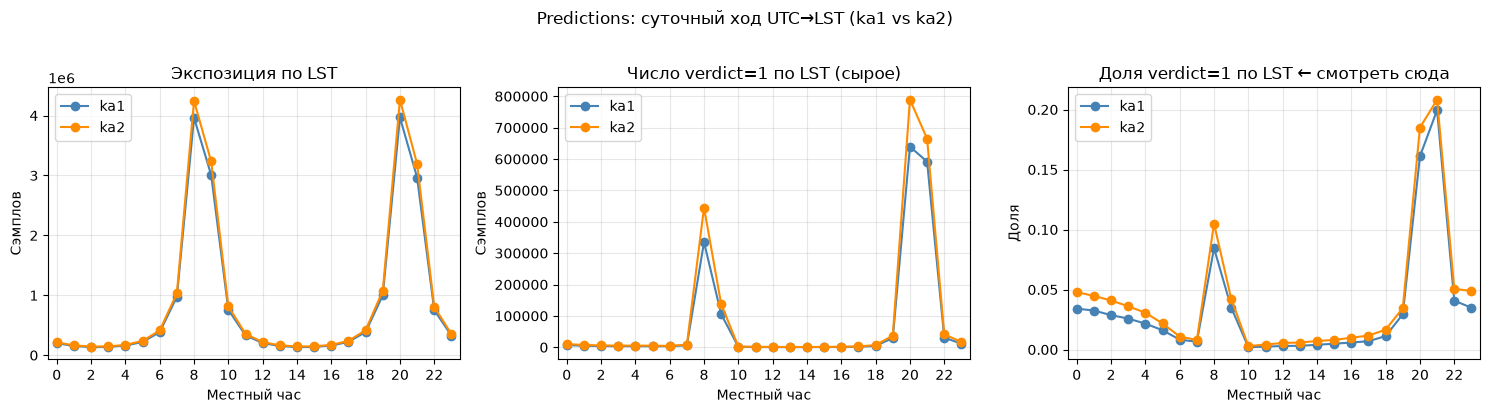

In [95]:
import gc
import matplotlib.pyplot as plt

if 'df_pred' not in dir() or df_pred is None or getattr(df_pred, 'empty', True):
    raise ValueError('Нет df_pred — загрузите predictions выше')

# Местный час (от UTC) + суточный ход — обязательно отдельно ka1/ka2
dt = df_pred['timestamp']
hour_utc = (
    dt.dt.hour.to_numpy(dtype=np.float64)
    + dt.dt.minute.to_numpy(dtype=np.float64) / 60.0
    + dt.dt.second.to_numpy(dtype=np.float64) / 3600.0
)
lon = df_pred['geo_lon'].to_numpy(dtype=np.float64, copy=False)
local_hour = np.floor(np.mod(hour_utc + lon / 15.0, 24.0)).astype(np.int16)
local_hour = np.clip(local_hour, 0, 23)
df_pred['local_hour'] = local_hour

verdict = df_pred['verdict'].to_numpy(dtype=np.int8, copy=False)
sc = df_pred['sc'].astype(str).to_numpy()
hours = np.arange(24)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for sc_name, color in [('ka1', 'steelblue'), ('ka2', 'darkorange')]:
    m = sc == sc_name
    n_exp = np.bincount(local_hour[m], minlength=24).astype(np.float64)
    n_pos = np.bincount(local_hour[m], weights=(verdict[m] == 1).astype(np.float64), minlength=24)
    rate = np.divide(n_pos, n_exp, out=np.zeros(24), where=n_exp > 0)
    axes[0].plot(hours, n_exp, marker='o', color=color, label=sc_name)
    axes[1].plot(hours, n_pos, marker='o', color=color, label=sc_name)
    axes[2].plot(hours, rate, marker='o', color=color, label=sc_name)

axes[0].set_title('Экспозиция по LST')
axes[0].set_ylabel('Сэмплов')
axes[1].set_title('Число verdict=1 по LST (сырое)')
axes[1].set_ylabel('Сэмплов')
axes[2].set_title('Доля verdict=1 по LST ← смотреть сюда')
axes[2].set_ylabel('Доля')
for ax in axes:
    ax.set_xlim(-0.5, 23.5)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel('Местный час')
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle('Predictions: суточный ход UTC→LST (ka1 vs ka2)', y=1.02)
fig.tight_layout()
plt.show()
plt.close(fig)


#### ka4 — суточный ход по местному времени

Тот же набор панелей, что у ka1 и ka2: экспозиция, сырое число `verdict=1`, доля `verdict=1`.


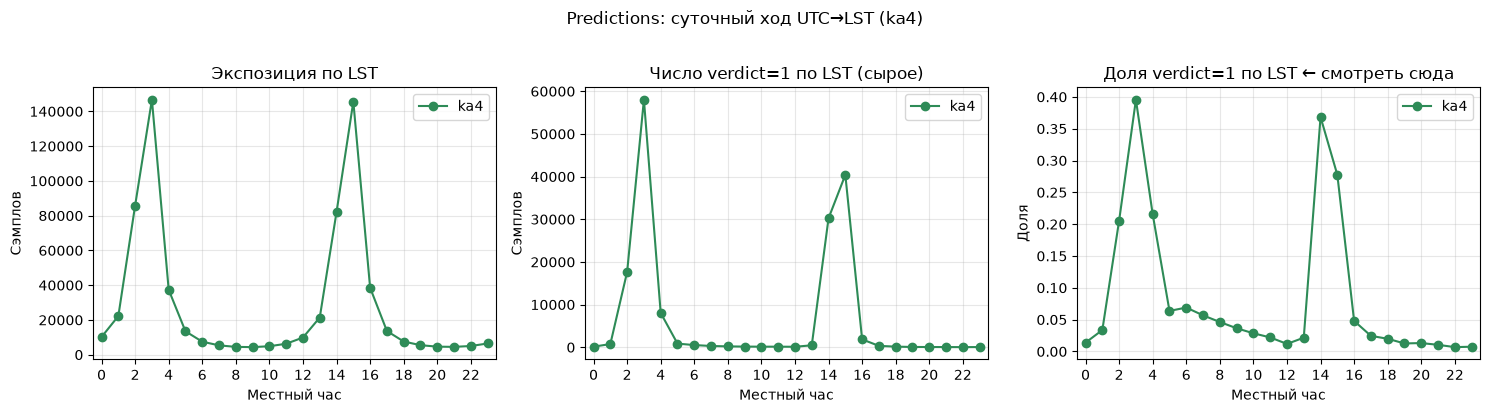

In [9]:
import gc
import matplotlib.pyplot as plt

if 'df_pred_ka4' not in dir() or df_pred_ka4 is None or getattr(df_pred_ka4, 'empty', True):
    raise ValueError('Нет df_pred_ka4 — загрузите ka4 выше')

# Местный час (от UTC) + суточный ход — обязательно отдельно ka1/ka2
dt = df_pred_ka4['timestamp']
hour_utc = (
    dt.dt.hour.to_numpy(dtype=np.float64)
    + dt.dt.minute.to_numpy(dtype=np.float64) / 60.0
    + dt.dt.second.to_numpy(dtype=np.float64) / 3600.0
)
lon = df_pred_ka4['geo_lon'].to_numpy(dtype=np.float64, copy=False)
local_hour = np.floor(np.mod(hour_utc + lon / 15.0, 24.0)).astype(np.int16)
local_hour = np.clip(local_hour, 0, 23)
df_pred_ka4['local_hour'] = local_hour

verdict = df_pred_ka4['verdict'].to_numpy(dtype=np.int8, copy=False)
sc = df_pred_ka4['sc'].astype(str).to_numpy()
hours = np.arange(24)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for sc_name, color in [('ka4', 'seagreen')]:
    m = sc == sc_name
    n_exp = np.bincount(local_hour[m], minlength=24).astype(np.float64)
    n_pos = np.bincount(local_hour[m], weights=(verdict[m] == 1).astype(np.float64), minlength=24)
    rate = np.divide(n_pos, n_exp, out=np.zeros(24), where=n_exp > 0)
    axes[0].plot(hours, n_exp, marker='o', color=color, label=sc_name)
    axes[1].plot(hours, n_pos, marker='o', color=color, label=sc_name)
    axes[2].plot(hours, rate, marker='o', color=color, label=sc_name)

axes[0].set_title('Экспозиция по LST')
axes[0].set_ylabel('Сэмплов')
axes[1].set_title('Число verdict=1 по LST (сырое)')
axes[1].set_ylabel('Сэмплов')
axes[2].set_title('Доля verdict=1 по LST ← смотреть сюда')
axes[2].set_ylabel('Доля')
for ax in axes:
    ax.set_xlim(-0.5, 23.5)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel('Местный час')
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle('Predictions: суточный ход UTC→LST (ka4)', y=1.02)
fig.tight_layout()
plt.show()
plt.close(fig)


#### Карта ka1 и ka2

Экспозиция и доля `verdict=1` на сетке широта×долгота. У каждого аппарата своя панель.


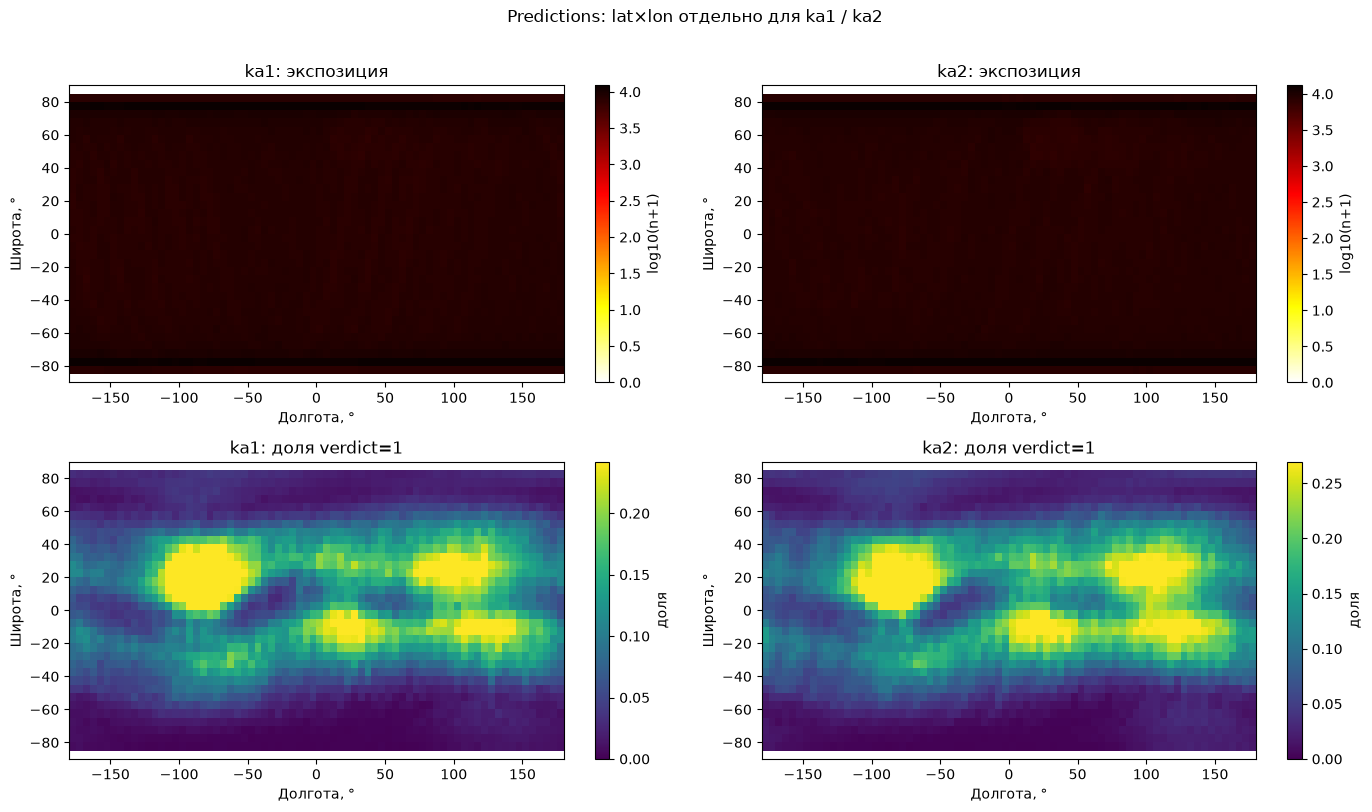

In [69]:
import gc
import matplotlib.pyplot as plt

if 'df_pred' not in dir() or df_pred is None or getattr(df_pred, 'empty', True):
    raise ValueError('Нет df_pred')

lat = df_pred['geo_lat'].to_numpy(dtype=np.float64, copy=False)
lon = df_pred['geo_lon'].to_numpy(dtype=np.float64, copy=False)
verdict = df_pred['verdict'].to_numpy(dtype=np.int8, copy=False)
sc = df_pred['sc'].astype(str).to_numpy()

lon_bins = np.arange(-180, 181, 5)
lat_bins = np.arange(-90, 91, 5)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for col, sc_name in enumerate(['ka1', 'ka2']):
    m = sc == sc_name
    exp2d, _, _ = np.histogram2d(lat[m], lon[m], bins=[lat_bins, lon_bins])
    pos2d, _, _ = np.histogram2d(lat[m & (verdict == 1)], lon[m & (verdict == 1)], bins=[lat_bins, lon_bins])
    rate2d = np.divide(pos2d, exp2d, out=np.full_like(exp2d, np.nan), where=exp2d > 0)

    im0 = axes[0, col].imshow(
        np.log10(exp2d + 1), aspect='auto', origin='lower', cmap='hot_r',
        extent=[lon_bins[0], lon_bins[-1], lat_bins[0], lat_bins[-1]],
    )
    axes[0, col].set_title(f'{sc_name}: экспозиция')
    plt.colorbar(im0, ax=axes[0, col], label='log10(n+1)')

    im1 = axes[1, col].imshow(
        rate2d, aspect='auto', origin='lower', cmap='viridis',
        extent=[lon_bins[0], lon_bins[-1], lat_bins[0], lat_bins[-1]],
        vmin=0, vmax=np.nanpercentile(rate2d, 95),
    )
    axes[1, col].set_title(f'{sc_name}: доля verdict=1')
    plt.colorbar(im1, ax=axes[1, col], label='доля')

for ax in axes.ravel():
    ax.set_xlabel('Долгота, °')
    ax.set_ylabel('Широта, °')
fig.suptitle('Predictions: lat×lon отдельно для ka1 / ka2', y=1.01)
fig.tight_layout()
plt.show()
plt.close(fig)


#### ka4 — карта широта × долгота

Экспозиция и доля `verdict=1` на сетке, только ka4.


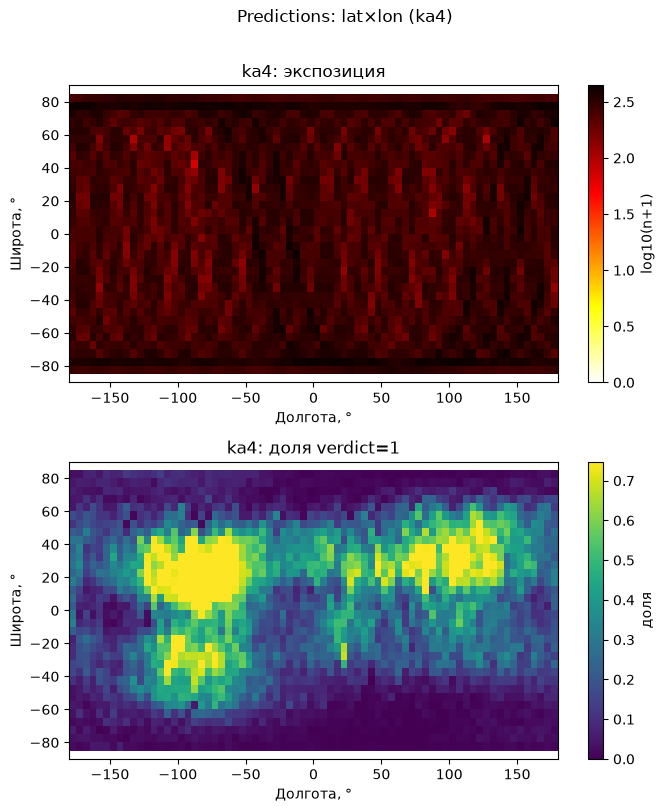

In [10]:
import gc
import matplotlib.pyplot as plt

if 'df_pred_ka4' not in dir() or df_pred_ka4 is None or getattr(df_pred_ka4, 'empty', True):
    raise ValueError('Нет df_pred_ka4')

lat = df_pred_ka4['geo_lat'].to_numpy(dtype=np.float64, copy=False)
lon = df_pred_ka4['geo_lon'].to_numpy(dtype=np.float64, copy=False)
verdict = df_pred_ka4['verdict'].to_numpy(dtype=np.int8, copy=False)
sc = df_pred_ka4['sc'].astype(str).to_numpy()

lon_bins = np.arange(-180, 181, 5)
lat_bins = np.arange(-90, 91, 5)

fig, axes = plt.subplots(2, 1, figsize=(7, 8))
axes = np.asarray(axes).reshape(2, 1)
for col, sc_name in enumerate(['ka4']):
    m = sc == sc_name
    exp2d, _, _ = np.histogram2d(lat[m], lon[m], bins=[lat_bins, lon_bins])
    pos2d, _, _ = np.histogram2d(lat[m & (verdict == 1)], lon[m & (verdict == 1)], bins=[lat_bins, lon_bins])
    rate2d = np.divide(pos2d, exp2d, out=np.full_like(exp2d, np.nan), where=exp2d > 0)

    im0 = axes[0, col].imshow(
        np.log10(exp2d + 1), aspect='auto', origin='lower', cmap='hot_r',
        extent=[lon_bins[0], lon_bins[-1], lat_bins[0], lat_bins[-1]],
    )
    axes[0, col].set_title(f'{sc_name}: экспозиция')
    plt.colorbar(im0, ax=axes[0, col], label='log10(n+1)')

    im1 = axes[1, col].imshow(
        rate2d, aspect='auto', origin='lower', cmap='viridis',
        extent=[lon_bins[0], lon_bins[-1], lat_bins[0], lat_bins[-1]],
        vmin=0, vmax=np.nanpercentile(rate2d, 95),
    )
    axes[1, col].set_title(f'{sc_name}: доля verdict=1')
    plt.colorbar(im1, ax=axes[1, col], label='доля')

for ax in axes.ravel():
    ax.set_xlabel('Долгота, °')
    ax.set_ylabel('Широта, °')
fig.suptitle('Predictions: lat×lon (ka4)', y=1.01)
fig.tight_layout()
plt.show()
plt.close(fig)


#### Ховмёллер ka1 и ka2

Доля свистов, уже поделённая на экспозицию: широта × местный час и долгота × местный час.


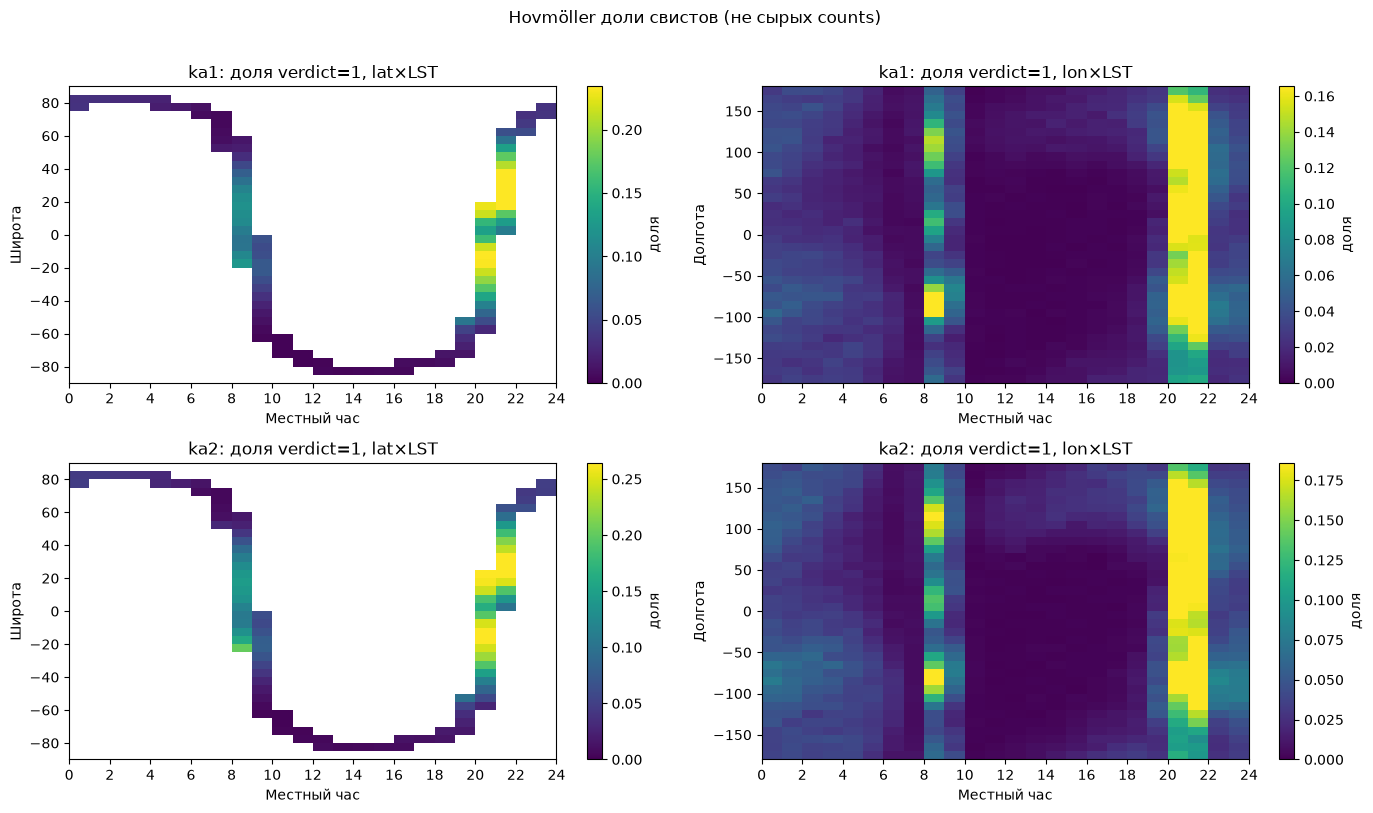

In [70]:
import gc
import matplotlib.pyplot as plt

if 'local_hour' not in df_pred.columns:
    raise ValueError('Сначала ячейку с local_hour')

lat = df_pred['geo_lat'].to_numpy(dtype=np.float64, copy=False)
lon = df_pred['geo_lon'].to_numpy(dtype=np.float64, copy=False)
lh = df_pred['local_hour'].to_numpy(dtype=np.float64, copy=False)
verdict = df_pred['verdict'].to_numpy(dtype=np.int8, copy=False)
sc = df_pred['sc'].astype(str).to_numpy()

lat_bins = np.arange(-90, 91, 5)
lon_bins = np.arange(-180, 181, 10)
hour_bins = np.arange(0, 25)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, sc_name in enumerate(['ka1', 'ka2']):
    m = sc == sc_name
    exp_lat, _, _ = np.histogram2d(lat[m], lh[m], bins=[lat_bins, hour_bins])
    pos_lat, _, _ = np.histogram2d(lat[m & (verdict == 1)], lh[m & (verdict == 1)], bins=[lat_bins, hour_bins])
    rate_lat = np.divide(pos_lat, exp_lat, out=np.full_like(exp_lat, np.nan), where=exp_lat > 0)

    exp_lon, _, _ = np.histogram2d(lon[m], lh[m], bins=[lon_bins, hour_bins])
    pos_lon, _, _ = np.histogram2d(lon[m & (verdict == 1)], lh[m & (verdict == 1)], bins=[lon_bins, hour_bins])
    rate_lon = np.divide(pos_lon, exp_lon, out=np.full_like(exp_lon, np.nan), where=exp_lon > 0)

    im = axes[row, 0].imshow(rate_lat, aspect='auto', origin='lower', cmap='viridis',
                             extent=[0, 24, lat_bins[0], lat_bins[-1]],
                             vmin=0, vmax=np.nanpercentile(rate_lat, 95))
    axes[row, 0].set_title(f'{sc_name}: доля verdict=1, lat×LST')
    axes[row, 0].set_ylabel('Широта')
    plt.colorbar(im, ax=axes[row, 0], label='доля')

    im = axes[row, 1].imshow(rate_lon, aspect='auto', origin='lower', cmap='viridis',
                             extent=[0, 24, lon_bins[0], lon_bins[-1]],
                             vmin=0, vmax=np.nanpercentile(rate_lon, 95))
    axes[row, 1].set_title(f'{sc_name}: доля verdict=1, lon×LST')
    axes[row, 1].set_ylabel('Долгота')
    plt.colorbar(im, ax=axes[row, 1], label='доля')

for ax in axes.ravel():
    ax.set_xlabel('Местный час')
    ax.set_xticks(range(0, 25, 2))
fig.suptitle('Hovmöller доли свистов (не сырых counts)', y=1.01)
fig.tight_layout()
plt.show()
plt.close(fig)


#### ka4 — Ховмёллер

Доля свистов ka4: широта × местный час и долгота × местный час.


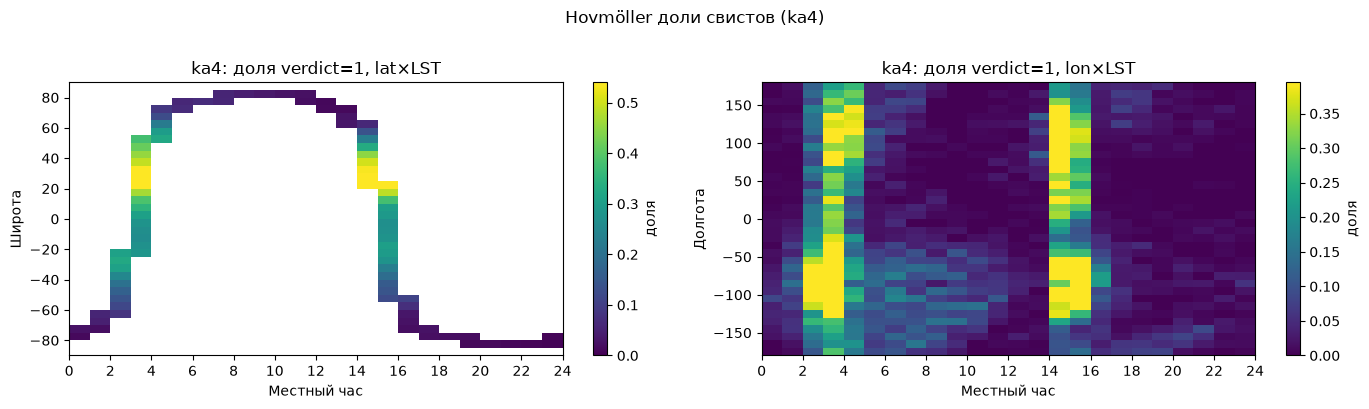

In [11]:
import gc
import matplotlib.pyplot as plt

if 'local_hour' not in df_pred_ka4.columns:
    raise ValueError('Сначала ячейку LST для ka4 (с local_hour)')

lat = df_pred_ka4['geo_lat'].to_numpy(dtype=np.float64, copy=False)
lon = df_pred_ka4['geo_lon'].to_numpy(dtype=np.float64, copy=False)
lh = df_pred_ka4['local_hour'].to_numpy(dtype=np.float64, copy=False)
verdict = df_pred_ka4['verdict'].to_numpy(dtype=np.int8, copy=False)
sc = df_pred_ka4['sc'].astype(str).to_numpy()

lat_bins = np.arange(-90, 91, 5)
lon_bins = np.arange(-180, 181, 10)
hour_bins = np.arange(0, 25)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes = np.asarray(axes).reshape(1, 2)
for row, sc_name in enumerate(['ka4']):
    m = sc == sc_name
    exp_lat, _, _ = np.histogram2d(lat[m], lh[m], bins=[lat_bins, hour_bins])
    pos_lat, _, _ = np.histogram2d(lat[m & (verdict == 1)], lh[m & (verdict == 1)], bins=[lat_bins, hour_bins])
    rate_lat = np.divide(pos_lat, exp_lat, out=np.full_like(exp_lat, np.nan), where=exp_lat > 0)

    exp_lon, _, _ = np.histogram2d(lon[m], lh[m], bins=[lon_bins, hour_bins])
    pos_lon, _, _ = np.histogram2d(lon[m & (verdict == 1)], lh[m & (verdict == 1)], bins=[lon_bins, hour_bins])
    rate_lon = np.divide(pos_lon, exp_lon, out=np.full_like(exp_lon, np.nan), where=exp_lon > 0)

    im = axes[row, 0].imshow(rate_lat, aspect='auto', origin='lower', cmap='viridis',
                             extent=[0, 24, lat_bins[0], lat_bins[-1]],
                             vmin=0, vmax=np.nanpercentile(rate_lat, 95))
    axes[row, 0].set_title(f'{sc_name}: доля verdict=1, lat×LST')
    axes[row, 0].set_ylabel('Широта')
    plt.colorbar(im, ax=axes[row, 0], label='доля')

    im = axes[row, 1].imshow(rate_lon, aspect='auto', origin='lower', cmap='viridis',
                             extent=[0, 24, lon_bins[0], lon_bins[-1]],
                             vmin=0, vmax=np.nanpercentile(rate_lon, 95))
    axes[row, 1].set_title(f'{sc_name}: доля verdict=1, lon×LST')
    axes[row, 1].set_ylabel('Долгота')
    plt.colorbar(im, ax=axes[row, 1], label='доля')

for ax in axes.ravel():
    ax.set_xlabel('Местный час')
    ax.set_xticks(range(0, 25, 2))
fig.suptitle('Hovmöller доли свистов (ka4)', y=1.01)
fig.tight_layout()
plt.show()
plt.close(fig)


## Молнии и доля свистов — сравнение формы

Совпадает ли **форма** кривой «где чаще свисты» с формой кривой «где чаще молнии». Высота кривых к сравнению не относится: каждая поделена на свой максимум.

| | Доля свистов | Молнии |
|---|---|---|
| метрика | `verdict=1 / exposure` | плотность, число разрядов на площадь бина |
| выборка | секунды на орбите | разряды в те же дни этого аппарата и в бинах, где экспозиция не ниже `MIN_EXP` |
| ночь/день | солнечный зенитный угол на поверхности `SZA > 98°` | тот же порог |
| ось Y | каждая кривая к своему максимуму | то же |

`is_night` в файле предсказаний — признак тени самого спутника (`SZA > 117.6°`, высота орбиты около 800 км). Для свиста важна освещённость ионосферы под аппаратом, поэтому ночь здесь считается по зенитному углу на поверхности, порог 98°.

Молния и свист здесь не сопоставляются по секундам: это сравнение климатических кривых. На рисунке долготы молнии берутся из тех широт, где у спутника есть экспозиция. Полушария и порог энергии `ENERGY_MIN_J` разведены по разным кривым.

Рисунки ka1 и ka2: широта, затем долгота; ночь и день — отдельные фигуры. Подзаголовки ka4 повторяют те же рисунки на сутках ka4, без требования общих дат с ka1 и ka2.


In [113]:
# --- параметры сравнения формы ---
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
importlib.reload(wc)

MIN_EXP = 200          # мин. секунд экспозиции в бине
ENERGY_MIN_J = 1000    # вторая кривая молний
SC_LIST_CMP = ('ka1', 'ka2')
# Ночь — солнечный зенитный угол НА ПОВЕРХНОСТИ, одинаково для КА и молний и
# одинаково во всех блоках ноутбука (wwlln_common.NIGHT_SZA_DEG = 98°).
# Колонка is_night в файлах — это другое: тень Земли на высоте орбиты (SZA>117.6°),
# т.е. «спутник не освещён», а не «под спутником темно».
NIGHT_SZA_DEG = wc.NIGHT_SZA_DEG

_paths_cmp = wc.resolve_paths()
# Один и тот же период для ka1 и ka2, иначе разница между аппаратами смешана
# с разницей дат (ka1 стартует 20 января).
CMP_DAYS = wc.analysis_days(_paths_cmp['pred'], _paths_cmp['ae'], SC_LIST_CMP)
CMP_DAYCODES = wc.day_codes(CMP_DAYS)
print(f'Общий период: {len(CMP_DAYS)} суток ({CMP_DAYS[0]} … {CMP_DAYS[-1]})')

df, df_pred = wc.ensure_data(globals(), days=CMP_DAYS)
if 'energy' not in df.columns:
    raise ValueError('В df нет energy')

season_order = list(wc.SEASON_ORDER)
season_to_i = dict(wc.SEASON_TO_I)
sc_to_i = {s: i for i, s in enumerate(SC_LIST_CMP)}

lat_edges = np.arange(-90, 91, 5)
lon_edges = np.arange(-180, 181, 10)
lat_centers = 0.5 * (lat_edges[:-1] + lat_edges[1:])
lon_centers = 0.5 * (lon_edges[:-1] + lon_edges[1:])
n_lat = len(lat_edges) - 1
n_lon = len(lon_edges) - 1
lat_area = np.abs(np.sin(np.radians(lat_edges[1:])) - np.sin(np.radians(lat_edges[:-1])))
lat_area = np.maximum(lat_area, 1e-12)
lon_width = np.maximum(np.diff(lon_edges).astype(np.float64), 1e-12)

n_sc, n_hem, n_sea, n_night = len(SC_LIST_CMP), 2, 4, 2
n_g = n_hem * n_sea * n_night
shp_lat = (n_hem, n_sea, n_night, n_lat)
shp_lon = (n_hem, n_sea, n_night, n_lon)
exp_lat = np.zeros((n_sc, n_hem, n_sea, n_night, n_lat), dtype=np.float64)
pos_lat = np.zeros_like(exp_lat)
exp_lon = np.zeros((n_sc, n_hem, n_sea, n_night, n_lon), dtype=np.float64)
pos_lon = np.zeros_like(exp_lon)
# energy_mode: 0=all, 1=filtered
flash_lat = np.zeros((2, n_sc, n_hem, n_sea, n_night, n_lat), dtype=np.float64)
flash_lon = np.zeros((2, n_sc, n_hem, n_sea, n_night, n_lon), dtype=np.float64)

solar_zenith_deg = wc.solar_zenith_deg
_season_idx = wc.season_index


def _day_key(dt64):
    """Номер суток целым числом. strftime('%Y%m%d') на 250М строк стоит десятки минут."""
    return np.asarray(dt64, dtype='datetime64[D]').astype(np.int64)


# дни coverage по КА
_pred_day = _day_key(df_pred['timestamp'].values)
_pred_sc = df_pred['sc'].astype(str).to_numpy()
_in_period = np.isin(_pred_day, CMP_DAYCODES)
pred_days = {sc: np.unique(_pred_day[(_pred_sc == sc) & _in_period]) for sc in SC_LIST_CMP}
for sc in SC_LIST_CMP:
    print(f'{sc}: {len(pred_days[sc])} дней predictions в общем периоде')
print(f'Отброшено сэмплов вне общего периода: {100 * (~_in_period).mean():.1f}%')

# --- predictions ---
plat = df_pred['geo_lat'].to_numpy(dtype=np.float64, copy=False)
plon = df_pred['geo_lon'].to_numpy(dtype=np.float64, copy=False)
pver = df_pred['verdict'].to_numpy(dtype=np.int8, copy=False)
pmonth = df_pred['timestamp'].dt.month.to_numpy()
psza = solar_zenith_deg(df_pred['timestamp'].values, plat, plon)
pnight = (psza > NIGHT_SZA_DEG).astype(np.int8)
if 'solar_zenith_angle' in df_pred.columns:
    err = np.abs(psza - df_pred['solar_zenith_angle'].to_numpy(dtype=np.float64))
    print(f'Проверка SZA против колонки файла: среднее |Δ| = {err.mean():.2f}° '
          f'(подтверждает, что MSK→UTC сделан верно)')
if 'is_night' in df_pred.columns:
    fn = df_pred['is_night'].to_numpy(dtype=np.int8, copy=False)
    print(f'Ночь по SZA>{NIGHT_SZA_DEG:.0f}°: {100 * pnight.mean():.1f}% сэмплов; '
          f'is_night из файла (тень на орбите): {100 * fn.mean():.1f}%')

for sc in SC_LIST_CMP:
    si = sc_to_i[sc]
    m_sc = (_pred_sc == sc) & _in_period
    if not m_sc.any():
        continue
    lat, lon = plat[m_sc], plon[m_sc]
    ver, night = pver[m_sc], pnight[m_sc]
    hem, sea = _season_idx(lat, pmonth[m_sc])
    g = (hem.astype(np.int64) * n_sea + sea) * n_night + night  # 16 групп hem×season×night
    lb = np.digitize(lat, lat_edges) - 1
    lo = np.digitize(lon, lon_edges) - 1
    ok = (lb >= 0) & (lb < n_lat) & (lo >= 0) & (lo < n_lon)
    hit = ok & (ver == 1)
    exp_lat[si] += np.bincount(g[ok] * n_lat + lb[ok], minlength=n_g * n_lat).reshape(shp_lat)
    pos_lat[si] += np.bincount(g[hit] * n_lat + lb[hit], minlength=n_g * n_lat).reshape(shp_lat)
    exp_lon[si] += np.bincount(g[ok] * n_lon + lo[ok], minlength=n_g * n_lon).reshape(shp_lon)
    pos_lon[si] += np.bincount(g[hit] * n_lon + lo[hit], minlength=n_g * n_lon).reshape(shp_lon)

# маски «спутник бывал в бине» — для фильтра молний по ортогональной оси
ok_lat = exp_lat >= MIN_EXP  # (sc,hem,sea,night,lat)
ok_lon = exp_lon >= MIN_EXP

# --- молнии: дни КА + та же ночь по SZA ---
CHUNK = 5_000_000
n = len(df)
print(f'Молнии: агрегация {n:,}...')
for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    dt = df['datetime'].iloc[start:stop]
    month = dt.dt.month.to_numpy()
    day_key = _day_key(dt.values)
    night = (solar_zenith_deg(dt.values, lat, lon) > NIGHT_SZA_DEG).astype(np.int8)
    hem, sea = _season_idx(lat, month)
    g = (hem.astype(np.int64) * n_sea + sea) * n_night + night
    lat_bin = np.digitize(lat, lat_edges) - 1
    lon_bin = np.digitize(lon, lon_edges) - 1
    valid = (lat_bin >= 0) & (lat_bin < n_lat) & (lon_bin >= 0) & (lon_bin < n_lon)

    m_e = e >= float(ENERGY_MIN_J)
    for sc in SC_LIST_CMP:
        si = sc_to_i[sc]
        # общий период → маска дней одинакова для ka1 и ka2
        base = valid & np.isin(day_key, CMP_DAYCODES)
        if not base.any():
            continue
        ok_lon_g = ok_lon[si].reshape(n_g, n_lon)
        ok_lat_g = ok_lat[si].reshape(n_g, n_lat)
        for ei, m0 in enumerate((base, base & m_e)):
            if not m0.any():
                continue
            gg, lb, lo = g[m0], lat_bin[m0], lon_bin[m0]
            # взаимная маска: в lat-профиль — только вспышки в lon с экспозицией;
            # в lon-профиль — только вспышки в lat с экспозицией
            sel = ok_lon_g[gg, lo]
            if sel.any():
                flash_lat[ei, si] += np.bincount(
                    gg[sel] * n_lat + lb[sel], minlength=n_g * n_lat
                ).reshape(shp_lat)
            sel = ok_lat_g[gg, lb]
            if sel.any():
                flash_lon[ei, si] += np.bincount(
                    gg[sel] * n_lon + lo[sel], minlength=n_g * n_lon
                ).reshape(shp_lon)
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')

print('MIN_EXP =', MIN_EXP, '| ENERGY_MIN_J =', ENERGY_MIN_J,
      f'| ночь = SZA > {NIGHT_SZA_DEG:.0f}° (общая для КА и молний)')


def _rate_masked(pos, exp, min_exp=MIN_EXP):
    out = np.full_like(exp, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = pos[ok] / exp[ok]
    return out


def _dens_masked(counts, area, exp, min_exp=MIN_EXP):
    out = np.full_like(counts, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = counts[ok] / area[ok]
    return out


def _maxn(x):
    """Нормализация формы: каждая кривая на свой max. Амплитуды несравнимы."""
    x = np.asarray(x, dtype=np.float64)
    m = np.nanmax(x) if np.isfinite(x).any() else np.nan
    if not np.isfinite(m) or m <= 0:
        return np.full_like(x, np.nan)
    return x / m


Общий период: 255 суток (20250120 … 20251031)
ka1: 255 дней predictions в общем периоде
ka2: 255 дней predictions в общем периоде
Отброшено сэмплов вне общего периода: 2.8%
Проверка SZA против колонки файла: среднее |Δ| = 0.26° (подтверждает, что MSK→UTC сделан верно)
Ночь по SZA>98°: 43.5% сэмплов; is_night из файла (тень на орбите): 26.6%
Молнии: агрегация 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337
MIN_EXP = 200 | ENERGY_MIN_J = 1000 | ночь = SZA > 98° (общая для КА и молний)


#### ka4 — агрегация для сравнения формы

Те же пороги и та же ночь по `SZA > 98°`, но только ka4 и его собственные сутки. Массивы ka1 и ka2 из ячейки выше сохраняются.


In [12]:
# --- параметры сравнения формы (ka4) ---
# не затираем навсегда массивы ka1/ka2 из ячейки выше
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
importlib.reload(wc)

_BACKUP_CMP = {k: globals()[k] for k in (
    'SC_LIST_CMP', 'sc_to_i', 'exp_lat', 'pos_lat', 'exp_lon', 'pos_lon',
    'flash_lat', 'flash_lon', 'CMP_DAYS', 'CMP_DAYCODES',
) if k in globals()}
_DF_PRED_BACKUP = globals().get('df_pred')


MIN_EXP = 200          # мин. секунд экспозиции в бине
ENERGY_MIN_J = 1000    # вторая кривая молний
SC_LIST_CMP = ('ka4',)
# Ночь — солнечный зенитный угол НА ПОВЕРХНОСТИ, одинаково для КА и молний и
# одинаково во всех блоках ноутбука (wwlln_common.NIGHT_SZA_DEG = 98°).
# Колонка is_night в файлах — это другое: тень Земли на высоте орбиты (SZA>117.6°),
# т.е. «спутник не освещён», а не «под спутником темно».
NIGHT_SZA_DEG = wc.NIGHT_SZA_DEG

_paths_cmp = wc.resolve_paths()
# Свои сутки ka4 (пересечения с ka1/ka2 не требуем)
CMP_DAYS = wc.sc_days(_paths_cmp['pred'], _paths_cmp['ae'], 'ka4')
CMP_DAYCODES = wc.day_codes(CMP_DAYS)
print(f'Период ka4∩AE: {len(CMP_DAYS)} суток ({CMP_DAYS[0]} … {CMP_DAYS[-1]})')

df, _ = wc.ensure_data(globals(), days=CMP_DAYS, need_pred=False)
if 'df_pred_ka4' not in dir() or df_pred_ka4 is None or getattr(df_pred_ka4, 'empty', True):
    raise ValueError('Нет df_pred_ka4 — загрузите ka4 выше')
df_pred = df_pred_ka4  # локально для этого блока; ka1/ka2 в ячейке выше не трогаем
if 'energy' not in df.columns:
    raise ValueError('В df нет energy')

season_order = list(wc.SEASON_ORDER)
season_to_i = dict(wc.SEASON_TO_I)
sc_to_i = {s: i for i, s in enumerate(SC_LIST_CMP)}

lat_edges = np.arange(-90, 91, 5)
lon_edges = np.arange(-180, 181, 10)
lat_centers = 0.5 * (lat_edges[:-1] + lat_edges[1:])
lon_centers = 0.5 * (lon_edges[:-1] + lon_edges[1:])
n_lat = len(lat_edges) - 1
n_lon = len(lon_edges) - 1
lat_area = np.abs(np.sin(np.radians(lat_edges[1:])) - np.sin(np.radians(lat_edges[:-1])))
lat_area = np.maximum(lat_area, 1e-12)
lon_width = np.maximum(np.diff(lon_edges).astype(np.float64), 1e-12)

n_sc, n_hem, n_sea, n_night = len(SC_LIST_CMP), 2, 4, 2
n_g = n_hem * n_sea * n_night
shp_lat = (n_hem, n_sea, n_night, n_lat)
shp_lon = (n_hem, n_sea, n_night, n_lon)
exp_lat = np.zeros((n_sc, n_hem, n_sea, n_night, n_lat), dtype=np.float64)
pos_lat = np.zeros_like(exp_lat)
exp_lon = np.zeros((n_sc, n_hem, n_sea, n_night, n_lon), dtype=np.float64)
pos_lon = np.zeros_like(exp_lon)
# energy_mode: 0=all, 1=filtered
flash_lat = np.zeros((2, n_sc, n_hem, n_sea, n_night, n_lat), dtype=np.float64)
flash_lon = np.zeros((2, n_sc, n_hem, n_sea, n_night, n_lon), dtype=np.float64)

solar_zenith_deg = wc.solar_zenith_deg
_season_idx = wc.season_index


def _day_key(dt64):
    """Номер суток целым числом. strftime('%Y%m%d') на 250М строк стоит десятки минут."""
    return np.asarray(dt64, dtype='datetime64[D]').astype(np.int64)


# дни coverage по КА
_pred_day = _day_key(df_pred['timestamp'].values)
_pred_sc = df_pred['sc'].astype(str).to_numpy()
_in_period = np.isin(_pred_day, CMP_DAYCODES)
pred_days = {sc: np.unique(_pred_day[(_pred_sc == sc) & _in_period]) for sc in SC_LIST_CMP}
for sc in SC_LIST_CMP:
    print(f'{sc}: {len(pred_days[sc])} дней predictions в общем периоде')
print(f'Отброшено сэмплов вне общего периода: {100 * (~_in_period).mean():.1f}%')

# --- predictions ---
plat = df_pred['geo_lat'].to_numpy(dtype=np.float64, copy=False)
plon = df_pred['geo_lon'].to_numpy(dtype=np.float64, copy=False)
pver = df_pred['verdict'].to_numpy(dtype=np.int8, copy=False)
pmonth = df_pred['timestamp'].dt.month.to_numpy()
psza = solar_zenith_deg(df_pred['timestamp'].values, plat, plon)
pnight = (psza > NIGHT_SZA_DEG).astype(np.int8)
if 'solar_zenith_angle' in df_pred.columns:
    err = np.abs(psza - df_pred['solar_zenith_angle'].to_numpy(dtype=np.float64))
    print(f'Проверка SZA против колонки файла: среднее |Δ| = {err.mean():.2f}° '
          f'(подтверждает, что MSK→UTC сделан верно)')
if 'is_night' in df_pred.columns:
    fn = df_pred['is_night'].to_numpy(dtype=np.int8, copy=False)
    print(f'Ночь по SZA>{NIGHT_SZA_DEG:.0f}°: {100 * pnight.mean():.1f}% сэмплов; '
          f'is_night из файла (тень на орбите): {100 * fn.mean():.1f}%')

for sc in SC_LIST_CMP:
    si = sc_to_i[sc]
    m_sc = (_pred_sc == sc) & _in_period
    if not m_sc.any():
        continue
    lat, lon = plat[m_sc], plon[m_sc]
    ver, night = pver[m_sc], pnight[m_sc]
    hem, sea = _season_idx(lat, pmonth[m_sc])
    g = (hem.astype(np.int64) * n_sea + sea) * n_night + night  # 16 групп hem×season×night
    lb = np.digitize(lat, lat_edges) - 1
    lo = np.digitize(lon, lon_edges) - 1
    ok = (lb >= 0) & (lb < n_lat) & (lo >= 0) & (lo < n_lon)
    hit = ok & (ver == 1)
    exp_lat[si] += np.bincount(g[ok] * n_lat + lb[ok], minlength=n_g * n_lat).reshape(shp_lat)
    pos_lat[si] += np.bincount(g[hit] * n_lat + lb[hit], minlength=n_g * n_lat).reshape(shp_lat)
    exp_lon[si] += np.bincount(g[ok] * n_lon + lo[ok], minlength=n_g * n_lon).reshape(shp_lon)
    pos_lon[si] += np.bincount(g[hit] * n_lon + lo[hit], minlength=n_g * n_lon).reshape(shp_lon)

# маски «спутник бывал в бине» — для фильтра молний по ортогональной оси
ok_lat = exp_lat >= MIN_EXP  # (sc,hem,sea,night,lat)
ok_lon = exp_lon >= MIN_EXP

# --- молнии: дни КА + та же ночь по SZA ---
CHUNK = 5_000_000
n = len(df)
print(f'Молнии: агрегация {n:,}...')
for start in range(0, n, CHUNK):
    stop = min(start + CHUNK, n)
    e = df['energy'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lat = df['lat'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    lon = df['lon'].iloc[start:stop].to_numpy(dtype=np.float64, copy=False)
    dt = df['datetime'].iloc[start:stop]
    month = dt.dt.month.to_numpy()
    day_key = _day_key(dt.values)
    night = (solar_zenith_deg(dt.values, lat, lon) > NIGHT_SZA_DEG).astype(np.int8)
    hem, sea = _season_idx(lat, month)
    g = (hem.astype(np.int64) * n_sea + sea) * n_night + night
    lat_bin = np.digitize(lat, lat_edges) - 1
    lon_bin = np.digitize(lon, lon_edges) - 1
    valid = (lat_bin >= 0) & (lat_bin < n_lat) & (lon_bin >= 0) & (lon_bin < n_lon)

    m_e = e >= float(ENERGY_MIN_J)
    for sc in SC_LIST_CMP:
        si = sc_to_i[sc]
        # общий период → маска дней одинакова для ka1 и ka2
        base = valid & np.isin(day_key, CMP_DAYCODES)
        if not base.any():
            continue
        ok_lon_g = ok_lon[si].reshape(n_g, n_lon)
        ok_lat_g = ok_lat[si].reshape(n_g, n_lat)
        for ei, m0 in enumerate((base, base & m_e)):
            if not m0.any():
                continue
            gg, lb, lo = g[m0], lat_bin[m0], lon_bin[m0]
            # взаимная маска: в lat-профиль — только вспышки в lon с экспозицией;
            # в lon-профиль — только вспышки в lat с экспозицией
            sel = ok_lon_g[gg, lo]
            if sel.any():
                flash_lat[ei, si] += np.bincount(
                    gg[sel] * n_lat + lb[sel], minlength=n_g * n_lat
                ).reshape(shp_lat)
            sel = ok_lat_g[gg, lb]
            if sel.any():
                flash_lon[ei, si] += np.bincount(
                    gg[sel] * n_lon + lo[sel], minlength=n_g * n_lon
                ).reshape(shp_lon)
    if (start // CHUNK) % 10 == 0:
        print(f'  ... {stop:,}/{n:,}')

print('MIN_EXP =', MIN_EXP, '| ENERGY_MIN_J =', ENERGY_MIN_J,
      f'| ночь = SZA > {NIGHT_SZA_DEG:.0f}° (общая для КА и молний)')


def _rate_masked(pos, exp, min_exp=MIN_EXP):
    out = np.full_like(exp, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = pos[ok] / exp[ok]
    return out


def _dens_masked(counts, area, exp, min_exp=MIN_EXP):
    out = np.full_like(counts, np.nan, dtype=np.float64)
    ok = exp >= min_exp
    out[ok] = counts[ok] / area[ok]
    return out


def _maxn(x):
    """Нормализация формы: каждая кривая на свой max. Амплитуды несравнимы."""
    x = np.asarray(x, dtype=np.float64)
    m = np.nanmax(x) if np.isfinite(x).any() else np.nan
    if not np.isfinite(m) or m <= 0:
        return np.full_like(x, np.nan)
    return x / m

# сохранить массивы ka4 отдельно и вернуть ka1/ka2, если они были посчитаны выше
SC_LIST_CMP_KA4 = SC_LIST_CMP
sc_to_i_ka4 = dict(sc_to_i)
exp_lat_ka4, pos_lat_ka4 = exp_lat.copy(), pos_lat.copy()
exp_lon_ka4, pos_lon_ka4 = exp_lon.copy(), pos_lon.copy()
flash_lat_ka4, flash_lon_ka4 = flash_lat.copy(), flash_lon.copy()
if _BACKUP_CMP:
    globals().update(_BACKUP_CMP)
if _DF_PRED_BACKUP is not None:
    df_pred = _DF_PRED_BACKUP
print('ka4: массивы (*_ka4) сохранены'
      + ('; ka1/ka2 восстановлены' if _BACKUP_CMP else ' (ячейка ka1/ka2 ещё не запускалась)'))


Период ka4∩AE: 10 суток (20250821 … 20250831)
df не найден — загружаю молнии
AE из кэша: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet
ka4: 10 дней predictions в общем периоде
Отброшено сэмплов вне общего периода: 0.0%
Проверка SZA против колонки файла: среднее |Δ| = 0.32° (подтверждает, что MSK→UTC сделан верно)
Ночь по SZA>98°: 44.2% сэмплов; is_night из файла (тень на орбите): 27.7%
Молнии: агрегация 254,128,337...
  ... 5,000,000/254,128,337
  ... 55,000,000/254,128,337
  ... 105,000,000/254,128,337
  ... 155,000,000/254,128,337
  ... 205,000,000/254,128,337
  ... 254,128,337/254,128,337
MIN_EXP = 200 | ENERGY_MIN_J = 1000 | ночь = SZA > 98° (общая для КА и молний)
ka4: массивы (*_ka4) сохранены; ka1/ka2 восстановлены


#### Широта, ka1 и ka2

Ночь и день — отдельные фигуры. На панели форма доли свистов и форма плотности молний: каждая кривая поделена на свой максимум.


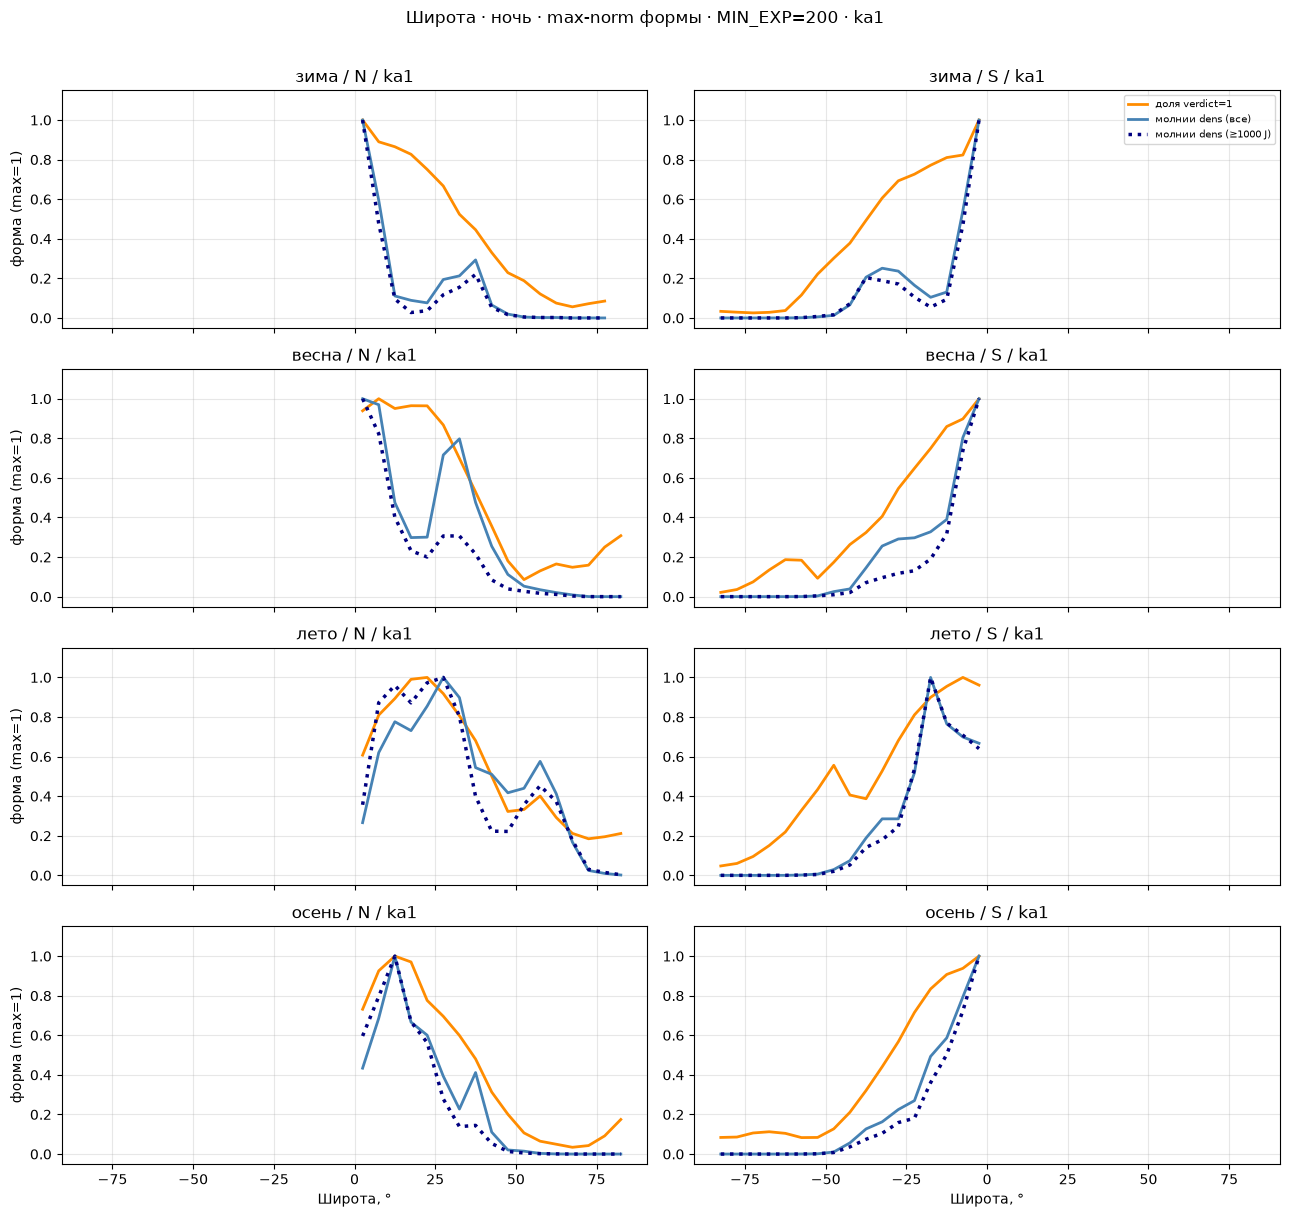

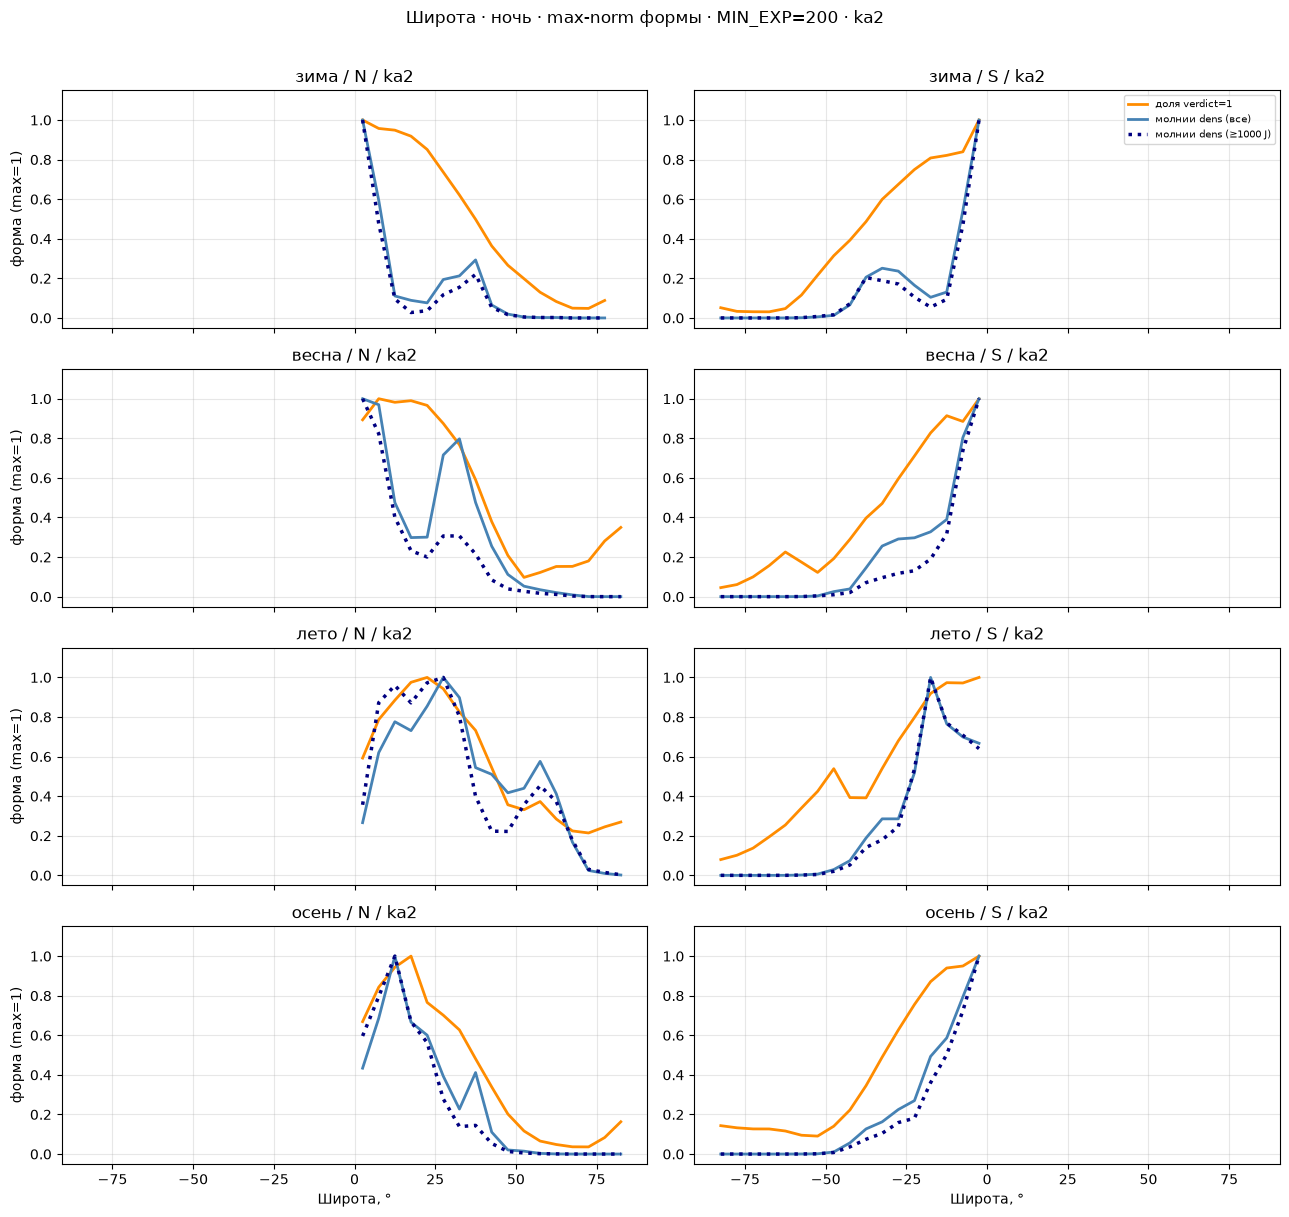

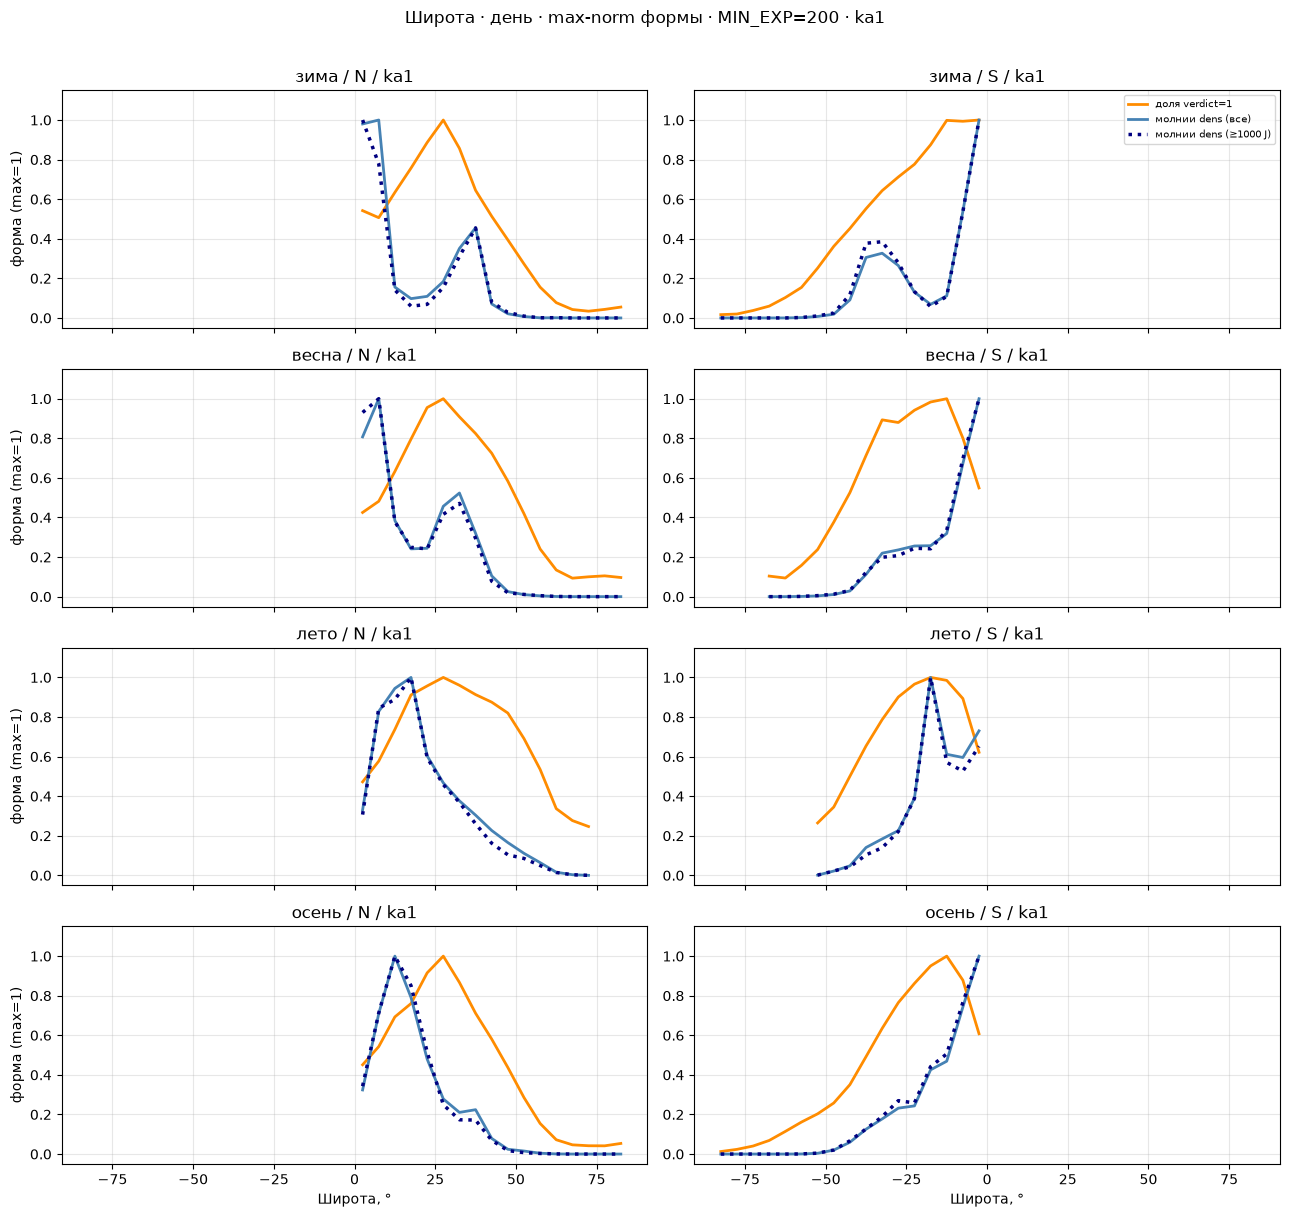

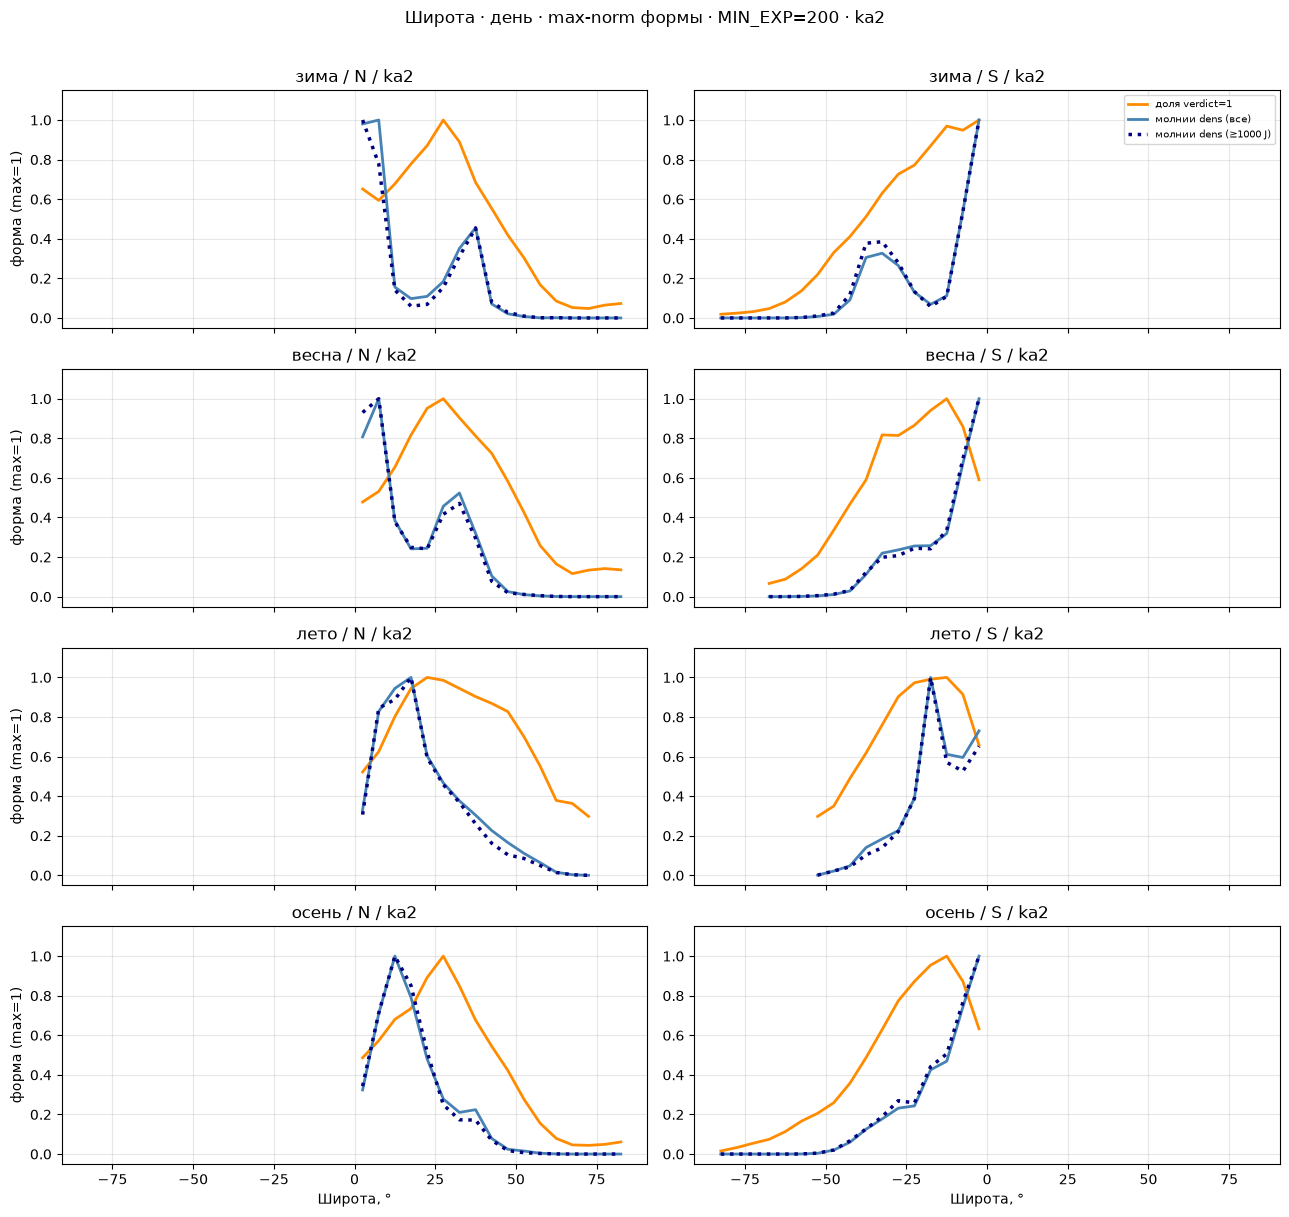

In [114]:
import matplotlib.pyplot as plt

# Широта: отдельные фигуры ночь / день (не мешаем разные режимы на одной оси).
# В панели: доля (maxn) + плотность молний all / ≥E (maxn) — только форма.

for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in SC_LIST_CMP:
        si = sc_to_i[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lat[si, hi, sei, night_i]
                rate = _rate_masked(pos_lat[si, hi, sei, night_i], exp)
                dens0 = _dens_masked(flash_lat[0, si, hi, sei, night_i], lat_area, exp)
                dens1 = _dens_masked(flash_lat[1, si, hi, sei, night_i], lat_area, exp)

                ln1, = ax.plot(lat_centers, _maxn(rate), color='darkorange', lw=2, label='доля verdict=1')
                ln2, = ax.plot(lat_centers, _maxn(dens0), color='steelblue', lw=2, label='молнии dens (все)')
                ln3, = ax.plot(
                    lat_centers, _maxn(dens1), color='navy', ls=':', lw=2.5,
                    label=f'молнии dens (≥{ENERGY_MIN_J:g} J)',
                )
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2, ln3], [l.get_label() for l in (ln1, ln2, ln3)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Широта, °')
        fig.suptitle(
            f'Широта · {night_lab} · max-norm формы · MIN_EXP={MIN_EXP} · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


#### ka4 — широта

Форма доли свистов и форма плотности молний вдоль широты. Ночь и день отдельными фигурами.


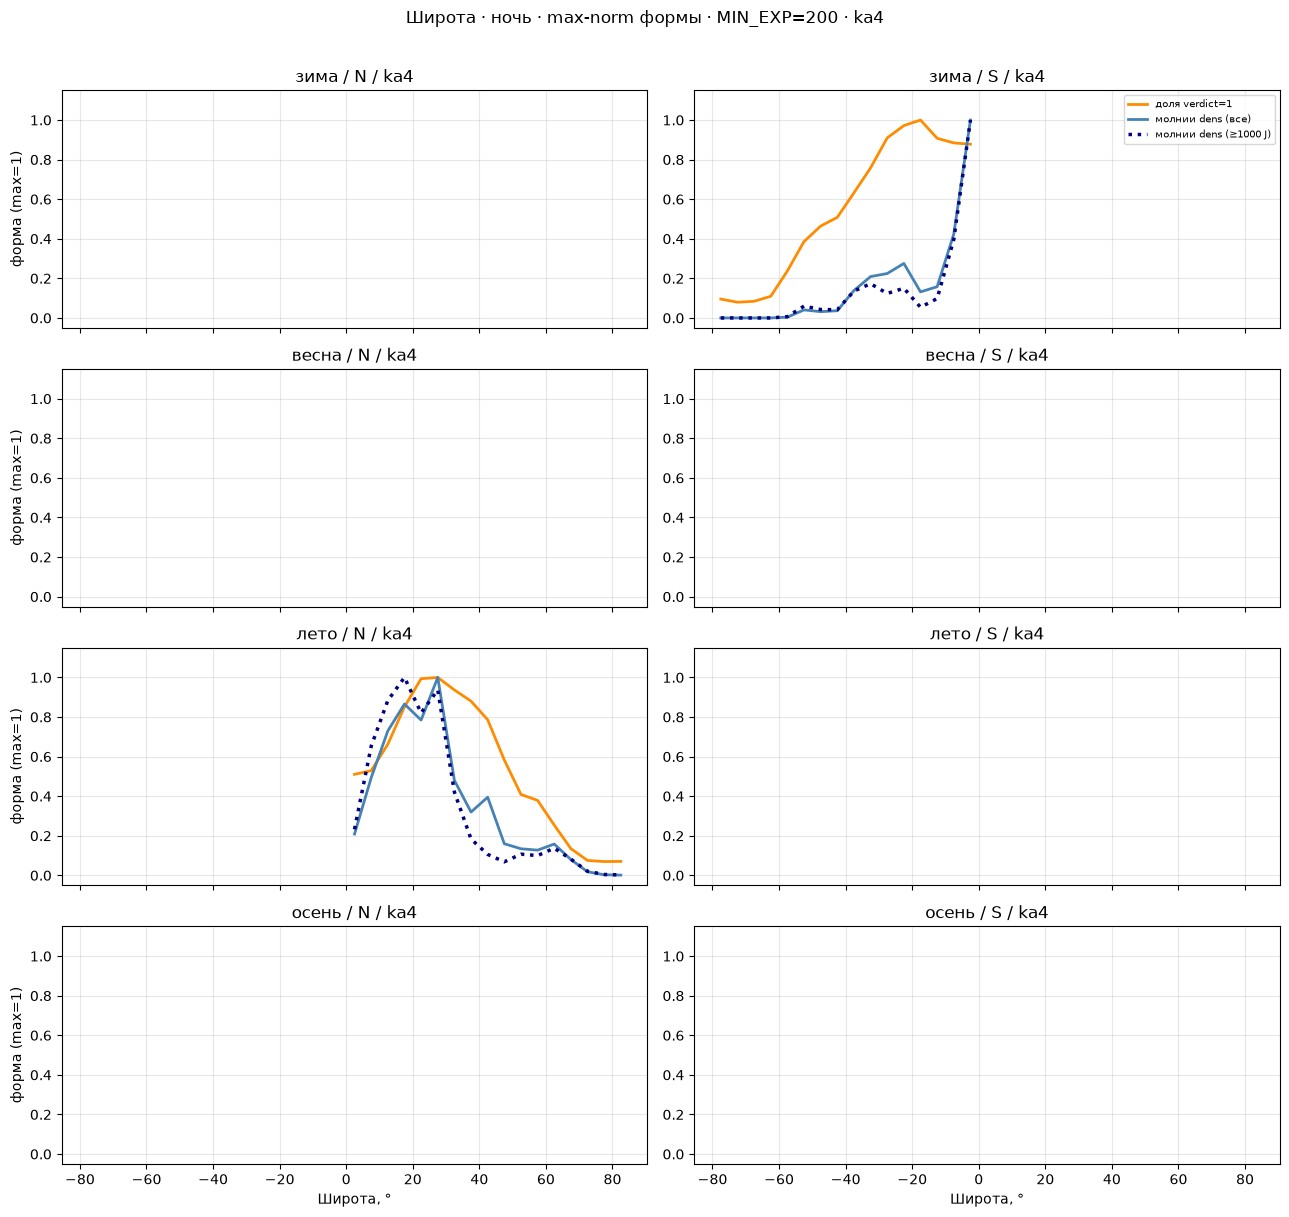

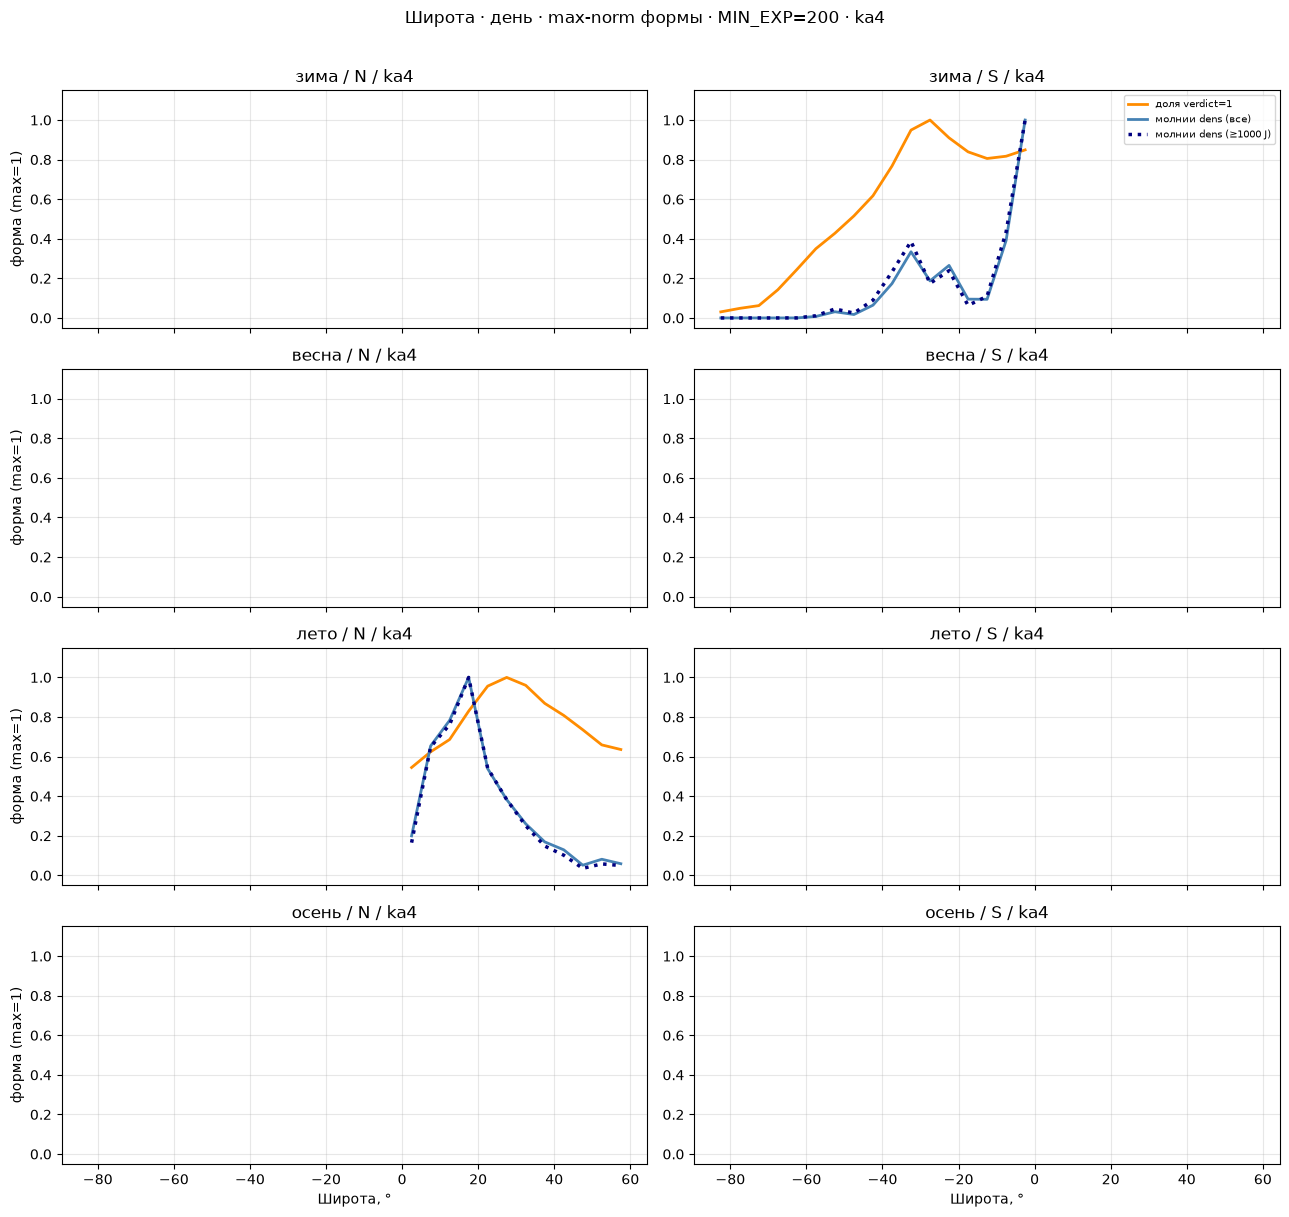

In [13]:
import matplotlib.pyplot as plt

# Широта: отдельные фигуры ночь / день (не мешаем разные режимы на одной оси).
# В панели: доля (maxn) + плотность молний all / ≥E (maxn) — только форма.

for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in SC_LIST_CMP_KA4:
        si = sc_to_i_ka4[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lat_ka4[si, hi, sei, night_i]
                rate = _rate_masked(pos_lat_ka4[si, hi, sei, night_i], exp)
                dens0 = _dens_masked(flash_lat_ka4[0, si, hi, sei, night_i], lat_area, exp)
                dens1 = _dens_masked(flash_lat_ka4[1, si, hi, sei, night_i], lat_area, exp)

                ln1, = ax.plot(lat_centers, _maxn(rate), color='darkorange', lw=2, label='доля verdict=1')
                ln2, = ax.plot(lat_centers, _maxn(dens0), color='steelblue', lw=2, label='молнии dens (все)')
                ln3, = ax.plot(
                    lat_centers, _maxn(dens1), color='navy', ls=':', lw=2.5,
                    label=f'молнии dens (≥{ENERGY_MIN_J:g} J)',
                )
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2, ln3], [l.get_label() for l in (ln1, ln2, ln3)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Широта, °')
        fig.suptitle(
            f'Широта · {night_lab} · max-norm формы · MIN_EXP={MIN_EXP} · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


#### Долгота, ka1 и ka2

То же сравнение формы вдоль долготы. Молнии взяты из широтных бинов, где у аппарата есть экспозиция.


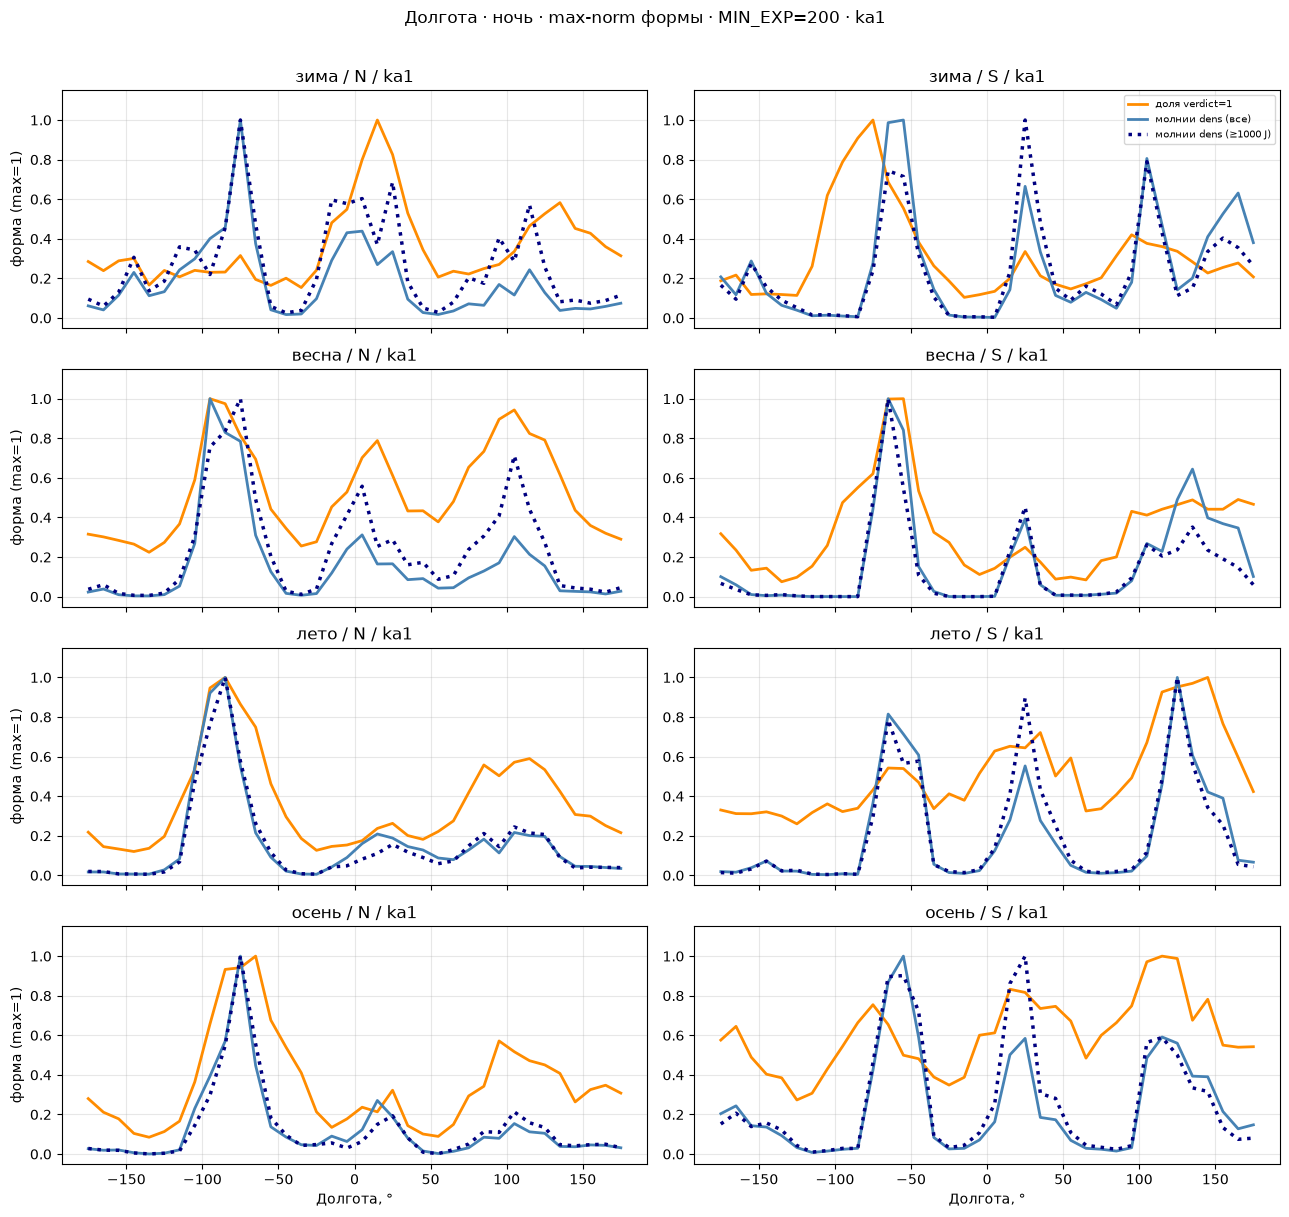

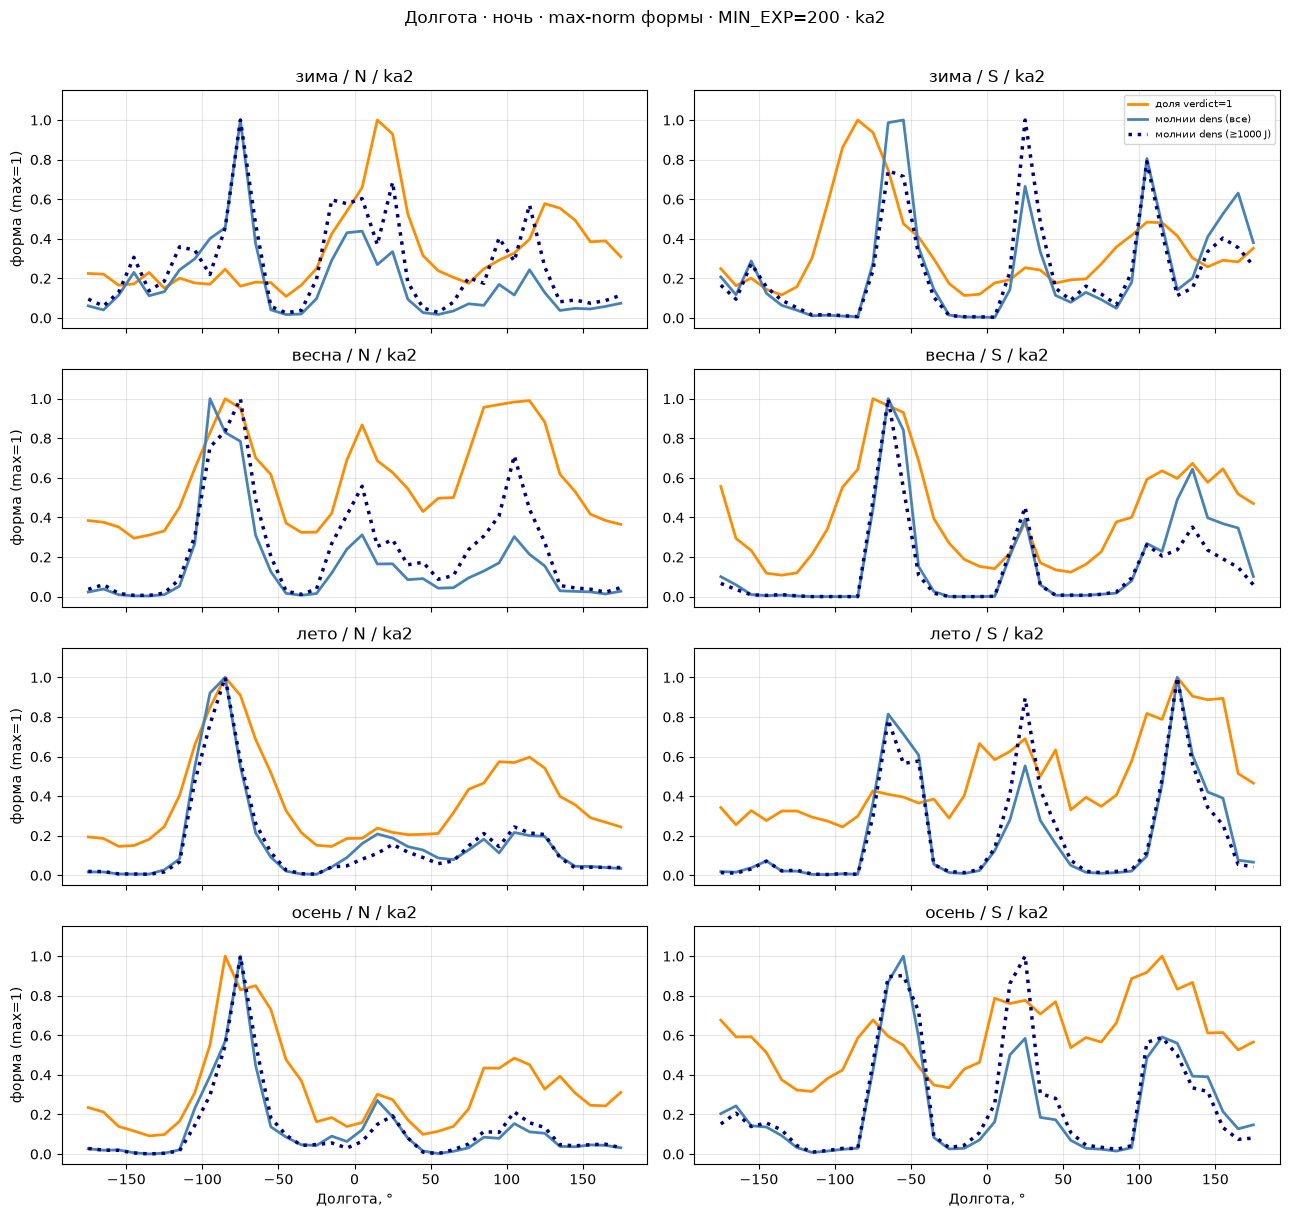

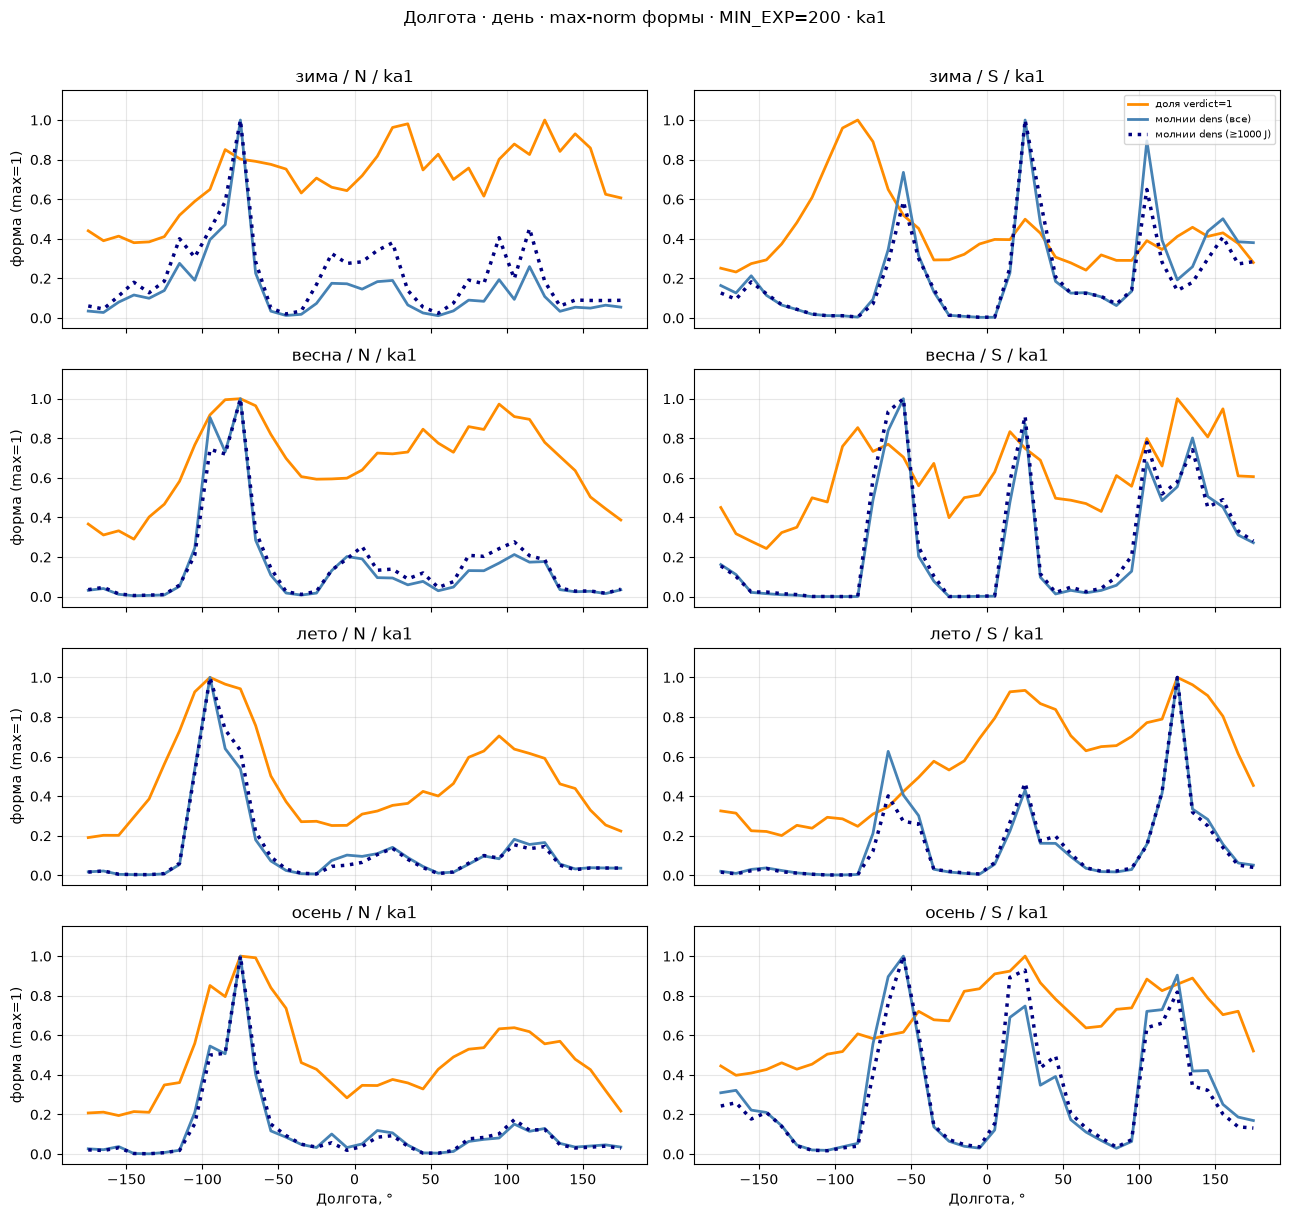

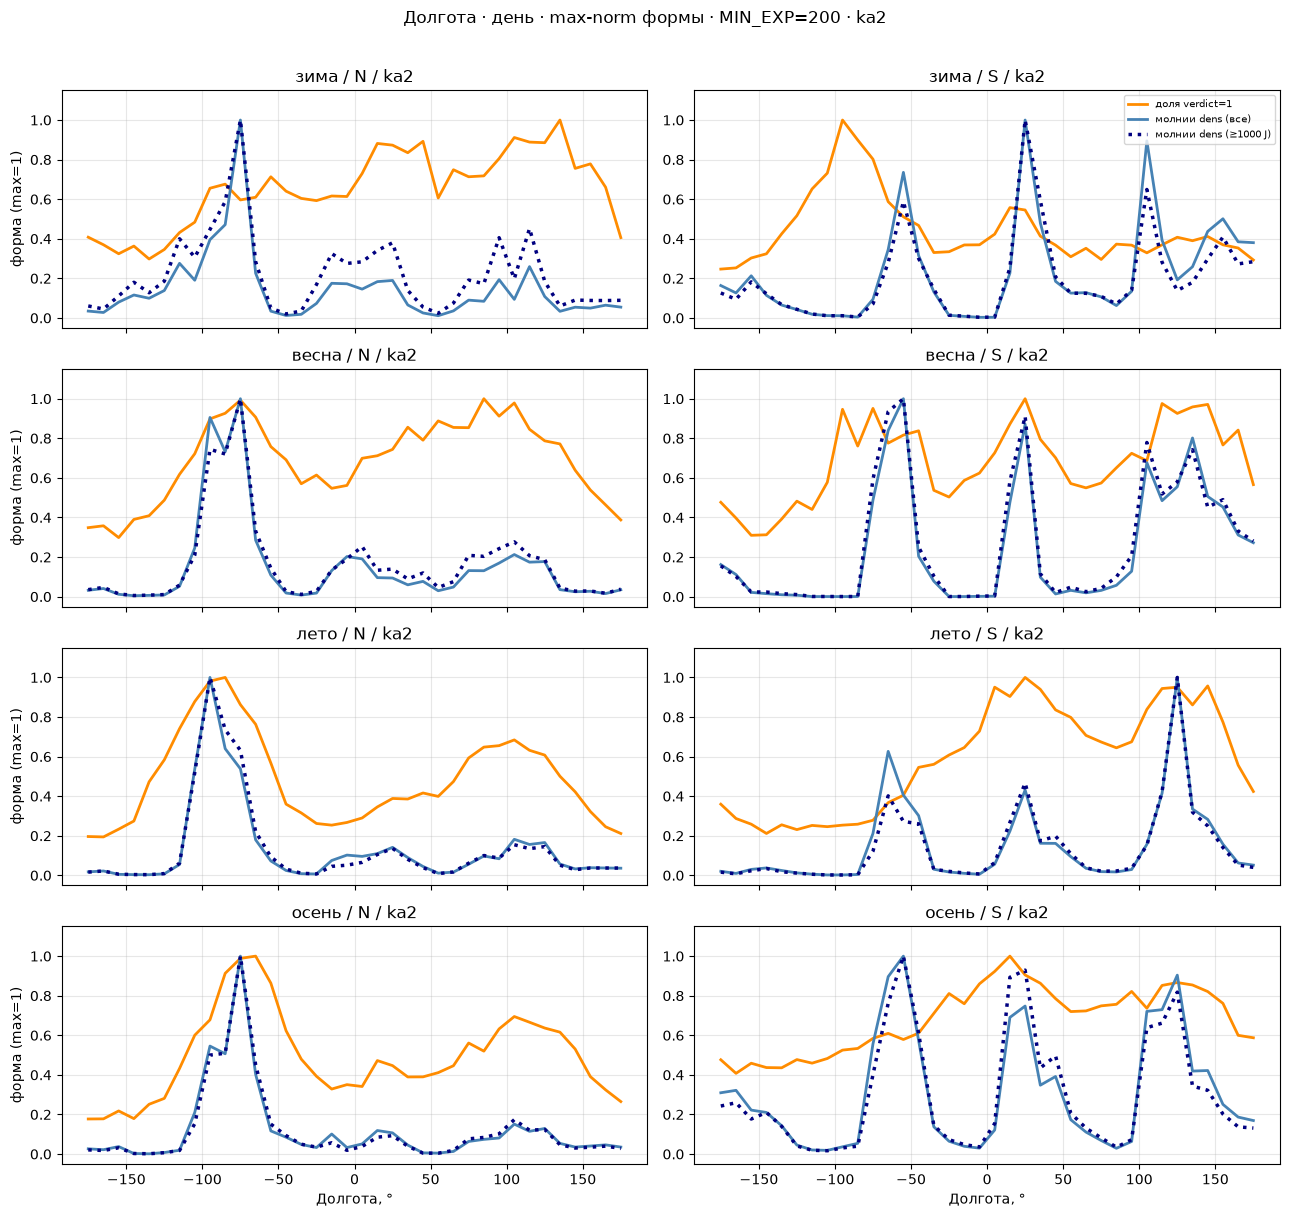

In [115]:
import matplotlib.pyplot as plt

# Долгота: ночь/день отдельно; молнии уже ограничены lat-бинами с экспозицией
for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in SC_LIST_CMP:
        si = sc_to_i[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lon[si, hi, sei, night_i]
                rate = _rate_masked(pos_lon[si, hi, sei, night_i], exp)
                dens0 = _dens_masked(flash_lon[0, si, hi, sei, night_i], lon_width, exp)
                dens1 = _dens_masked(flash_lon[1, si, hi, sei, night_i], lon_width, exp)

                ln1, = ax.plot(lon_centers, _maxn(rate), color='darkorange', lw=2, label='доля verdict=1')
                ln2, = ax.plot(lon_centers, _maxn(dens0), color='steelblue', lw=2, label='молнии dens (все)')
                ln3, = ax.plot(
                    lon_centers, _maxn(dens1), color='navy', ls=':', lw=2.5,
                    label=f'молнии dens (≥{ENERGY_MIN_J:g} J)',
                )
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2, ln3], [l.get_label() for l in (ln1, ln2, ln3)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Долгота, °')
        fig.suptitle(
            f'Долгота · {night_lab} · max-norm формы · MIN_EXP={MIN_EXP} · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


#### ka4 — долгота

То же сравнение формы вдоль долготы. Молнии взяты из широтных бинов, где у ka4 есть экспозиция.


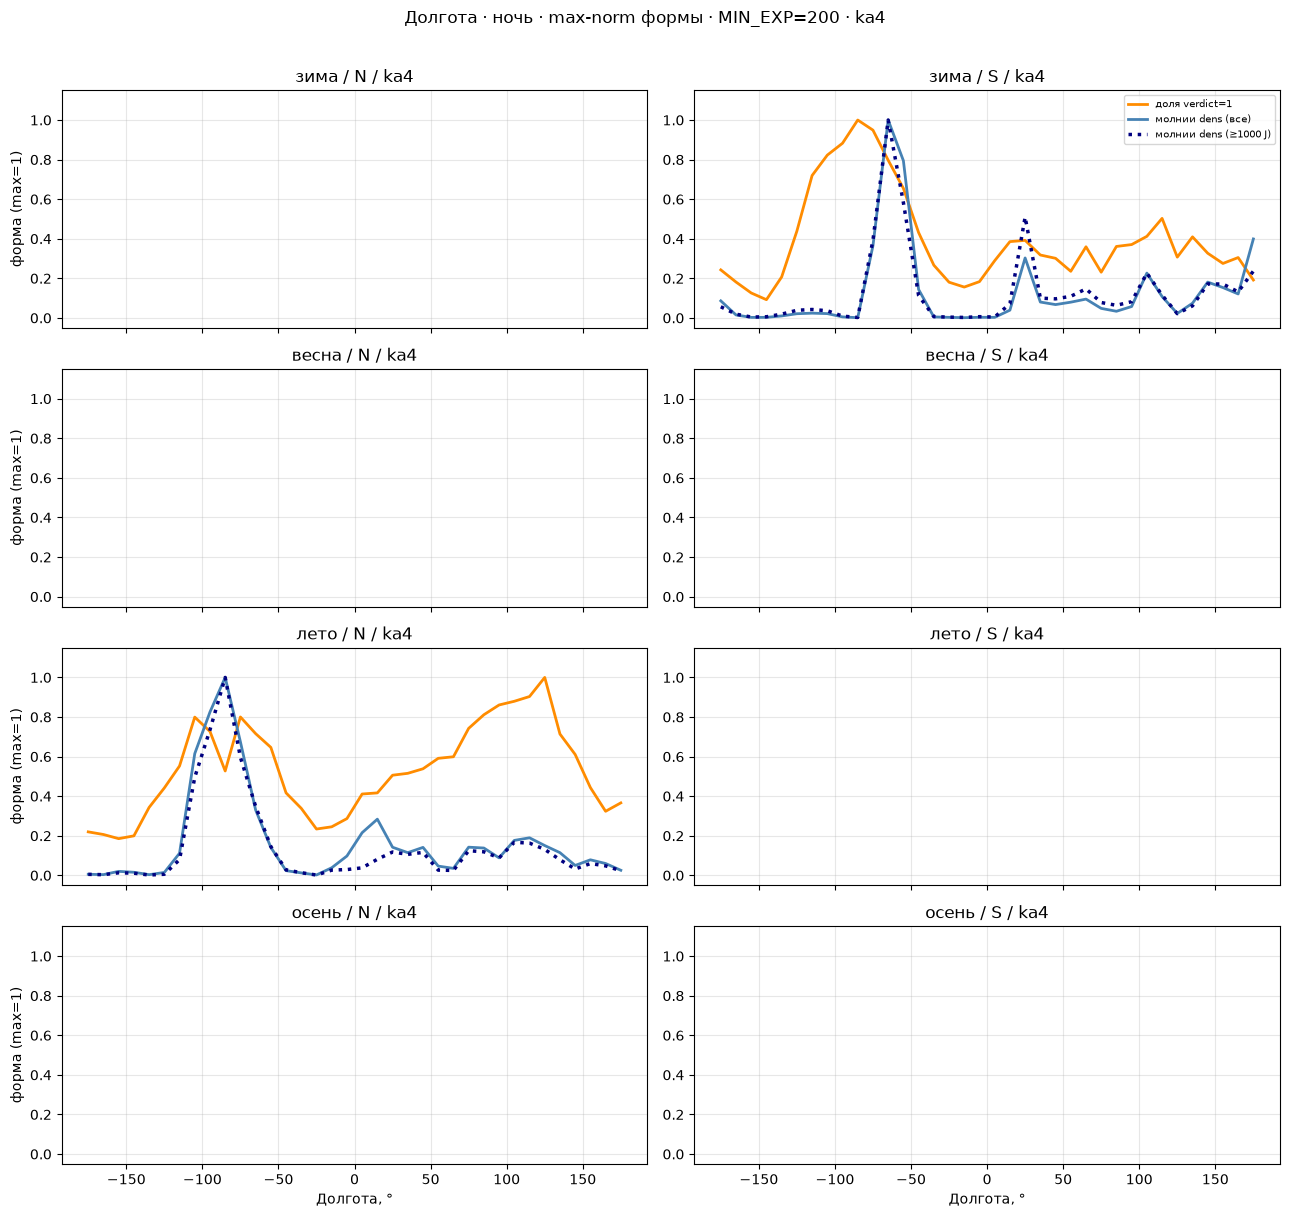

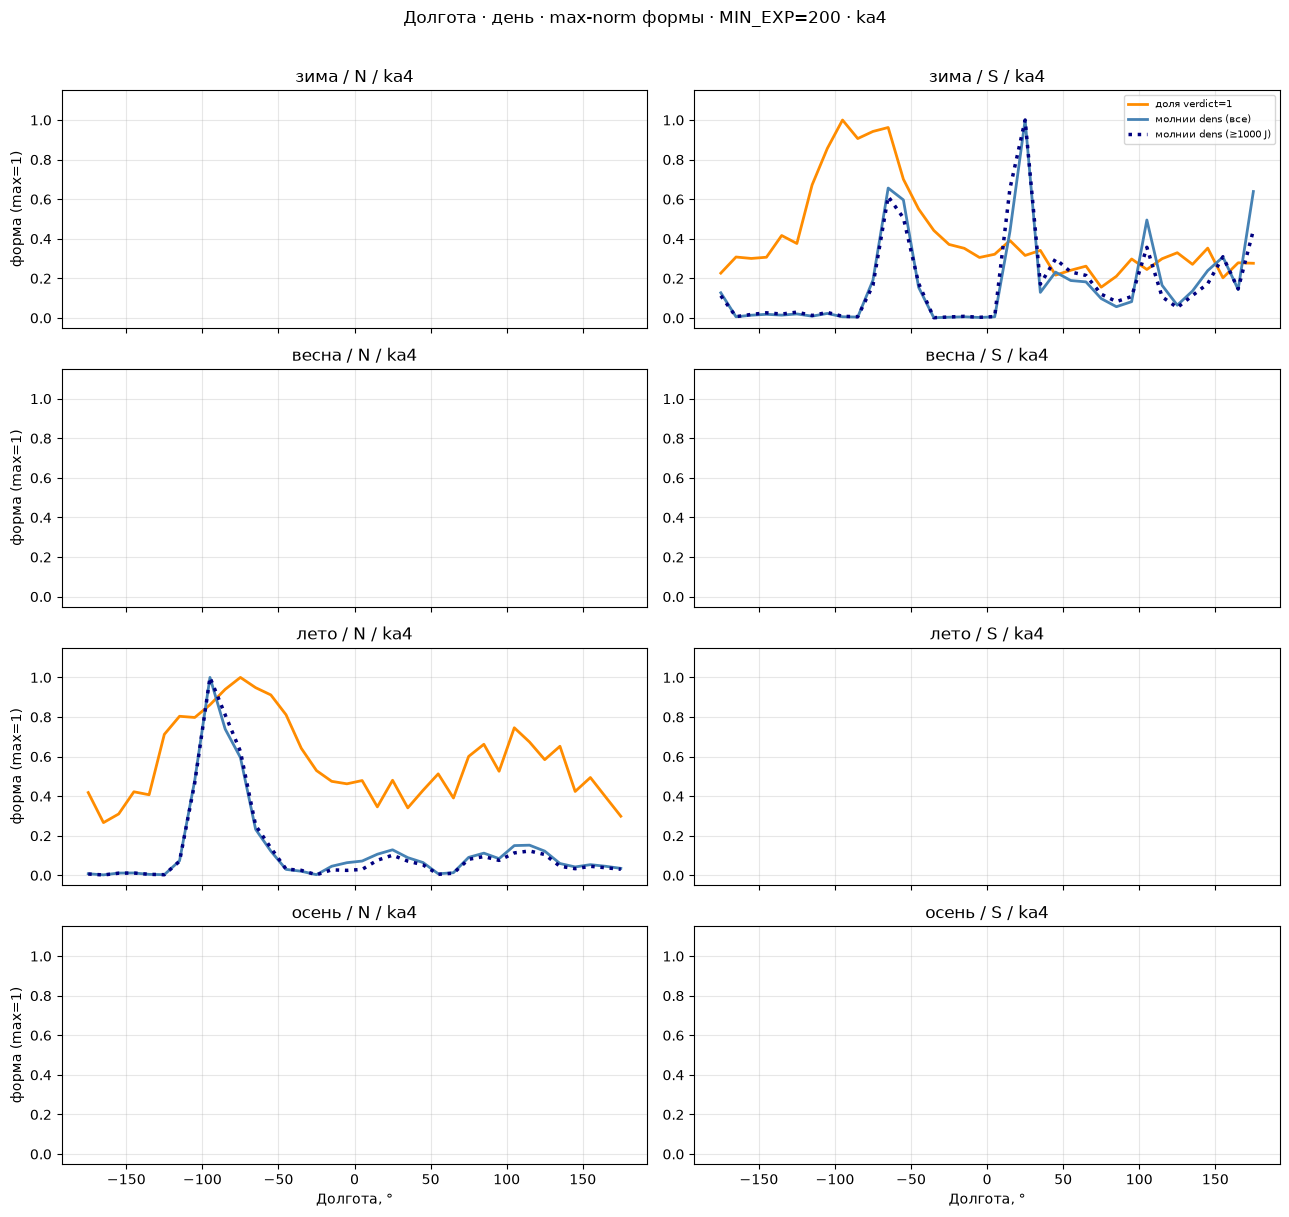

In [14]:
import matplotlib.pyplot as plt

# Долгота: ночь/день отдельно; молнии уже ограничены lat-бинами с экспозицией
for night_i, night_lab in enumerate(['ночь', 'день']):
    for sc in SC_LIST_CMP_KA4:
        si = sc_to_i_ka4[sc]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
        for row, sname in enumerate(season_order):
            sei = season_to_i[sname]
            for col, (hname, hi) in enumerate([('N', 0), ('S', 1)]):
                ax = axes[row, col]
                exp = exp_lon_ka4[si, hi, sei, night_i]
                rate = _rate_masked(pos_lon_ka4[si, hi, sei, night_i], exp)
                dens0 = _dens_masked(flash_lon_ka4[0, si, hi, sei, night_i], lon_width, exp)
                dens1 = _dens_masked(flash_lon_ka4[1, si, hi, sei, night_i], lon_width, exp)

                ln1, = ax.plot(lon_centers, _maxn(rate), color='darkorange', lw=2, label='доля verdict=1')
                ln2, = ax.plot(lon_centers, _maxn(dens0), color='steelblue', lw=2, label='молнии dens (все)')
                ln3, = ax.plot(
                    lon_centers, _maxn(dens1), color='navy', ls=':', lw=2.5,
                    label=f'молнии dens (≥{ENERGY_MIN_J:g} J)',
                )
                ax.set_ylim(-0.05, 1.15)
                ax.set_title(f'{sname} / {hname} / {sc}')
                ax.grid(alpha=0.3)
                if row == 0 and col == 1:
                    ax.legend([ln1, ln2, ln3], [l.get_label() for l in (ln1, ln2, ln3)],
                              loc='upper right', fontsize=7)
                if col == 0:
                    ax.set_ylabel('форма (max=1)')
                if row == 3:
                    ax.set_xlabel('Долгота, °')
        fig.suptitle(
            f'Долгота · {night_lab} · max-norm формы · MIN_EXP={MIN_EXP} · {sc}',
            y=1.01,
        )
        fig.tight_layout()
        plt.show()
        plt.close(fig)


## Whistler ↔ молнии

Здесь свист и молния уже связываются по месту и времени, а не только по форме климатических кривых. `verdict` — разметка из файлов предсказаний, время уже в UTC. Молнии — AE, тоже UTC. Порог по энергии выключен: берутся все разряды.

Порядок разделов:

1. Каузальный матчинг на секундах.
2. Статистическая ассоциация на минутах и часах.
3. Сводка этих двух проверок.
4. Доза–эффект — основной вывод, уже с контролем широты, местного времени, сезона и ночи.

Ночь (`SZA > 98°` на поверхности), сезоны, пути и список суток задаёт `wwlln_common.py`. Первая ячейка каждого блока сама импортирует модули. Если `df` или `df_pred` в ядре нет, `wc.ensure_data()` их догружает, поэтому блок можно запустить отдельно.

Общий период ka1, ka2 и файла AE считает `wc.analysis_days()`, и первая ячейка блока его печатает. В сохранённом прогоне это 255 суток, 20.01.2025–31.10.2025. Общие сутки нужны, чтобы разница ka1 и ka2 была разницей аппаратов: у ka1 данные начинаются 20 января.


### 1. Каузальный матчинг (секунды)

Проверка, приходит ли молния незадолго до свиста. Для каждой детекции ищется разряд WWLLN в радиусе R. Время `Δt = t_свиста − t_молнии`: положительное значение значит, что молния была раньше.

На рисунках — как избыток «молния до» над «молния после» зависит от радиуса. Аппараты ka1 и ka2, ночь и день раздельно. Сохранённый прогон — режим `pilot`: 21 сутки, равномерно по общему окну года. Геометрия сопряжённой точки в этом прогоне выключена (`RUN_CONJUGATE = False`).


In [1]:
# === Каузальный блок: самодостаточен, запускается сразу после рестарта ядра ===
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
import whistler_lightning_assoc as wla

importlib.reload(wc)
importlib.reload(wla)

PATHS = wc.resolve_paths()
PRED_DIR, AE_DIR = PATHS['pred'], PATHS['ae']

ASSOC_MODE = 'pilot'  # 'pilot' | 'full'
N_PILOT_DAYS = 21  # в pilot — равномерно по году (wc.spread_days)

# Единый период для всех блоков: сутки, где есть И ka1, И ka2, И файл AE.
# Иначе разница между аппаратами смешивается с разницей дат — ka1 начинается
# только 20 января, и «joint» вырождался в копию ka2.
ALL_DAYS = wc.analysis_days(PRED_DIR, AE_DIR, ('ka1', 'ka2'))
DAY_LIST = (
    wc.spread_days(ALL_DAYS, N_PILOT_DAYS) if ASSOC_MODE == 'pilot' else ALL_DAYS
)
print(f'Общих дней ka1∩ka2∩AE: {len(ALL_DAYS)} ({ALL_DAYS[0]} … {ALL_DAYS[-1]})')
print(f'Режим {ASSOC_MODE}: используем {len(DAY_LIST)} дней '
      f'({DAY_LIST[0]} … {DAY_LIST[-1]})'
      + (', spread по году' if ASSOC_MODE == 'pilot' else ''))
print('DAY_LIST:', DAY_LIST)

ENERGY_MIN_J_MATCH = None  # None = все молнии; иначе energy >= порог, Дж

cfg_causal = wla.AssocConfig(
    pred_dir=PRED_DIR,
    ae_dir=AE_DIR,
    sc_list=('ka1', 'ka2'),
    geometry='satellite',
    energy_min=ENERGY_MIN_J_MATCH,
    causal_r_km=1500.0,
    causal_tmax_s=5.0,
    causal_bin_s=1,
    max_whistlers_per_day=4000,
    day_list=DAY_LIST,
    max_days=None,
    causal_only=True,          # только секундный тест
    night_sza_deg=wc.NIGHT_SZA_DEG,
)
RUN_CONJUGATE = False  # conjugate здесь = (−lat, lon), грубый диполь; до IGRF смысла мало
print(f'energy_min={ENERGY_MIN_J_MATCH}, ночь = SZA > {wc.NIGHT_SZA_DEG:.0f}° на поверхности')

Общих дней ka1∩ka2∩AE: 255 (20250120 … 20251031)
Режим pilot: используем 21 дней (20250120 … 20251031), spread по году
DAY_LIST: ('20250120', '20250202', '20250214', '20250227', '20250312', '20250325', '20250406', '20250419', '20250502', '20250514', '20250527', '20250609', '20250621', '20250704', '20250717', '20250729', '20250811', '20250824', '20251006', '20251018', '20251031')
energy_min=None, ночь = SZA > 98° на поверхности


  [1/21] 20250120: pred=15,158 ae=1,667,999 wh_used=1,202 [causal_only]
  [2/21] 20250202: pred=80,032 ae=1,703,450 wh_used=4,000 [causal_only]
  [3/21] 20250214: pred=84,114 ae=1,724,640 wh_used=4,000 [causal_only]
  [4/21] 20250227: pred=86,386 ae=1,838,768 wh_used=4,000 [causal_only]
  [5/21] 20250312: pred=85,553 ae=2,075,166 wh_used=4,000 [causal_only]
  [6/21] 20250325: pred=86,394 ae=2,229,999 wh_used=4,000 [causal_only]
  [7/21] 20250406: pred=82,000 ae=2,057,904 wh_used=4,000 [causal_only]
  [8/21] 20250419: pred=85,719 ae=2,013,179 wh_used=4,000 [causal_only]
  [9/21] 20250502: pred=86,308 ae=1,947,827 wh_used=4,000 [causal_only]
  [10/21] 20250514: pred=86,178 ae=2,235,423 wh_used=4,000 [causal_only]
  [11/21] 20250527: pred=86,397 ae=2,207,334 wh_used=4,000 [causal_only]
  [12/21] 20250609: pred=86,396 ae=2,186,863 wh_used=4,000 [causal_only]
  [13/21] 20250621: pred=84,639 ae=2,130,039 wh_used=4,000 [causal_only]
  [14/21] 20250704: pred=85,927 ae=2,204,098 wh_used=4,000 [

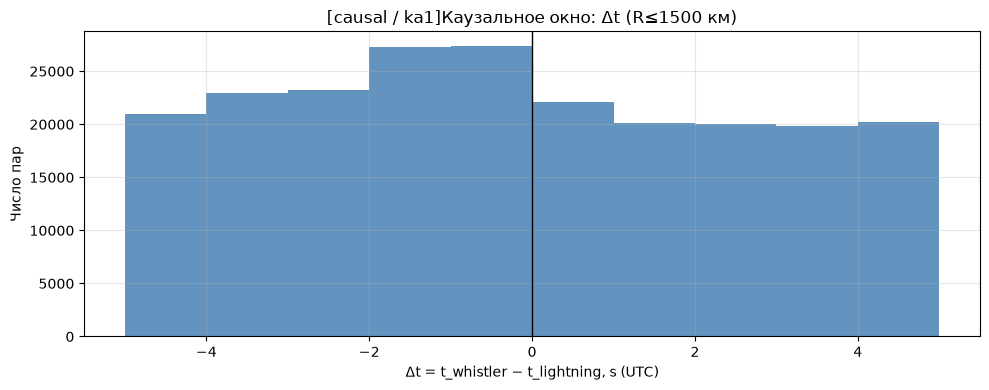

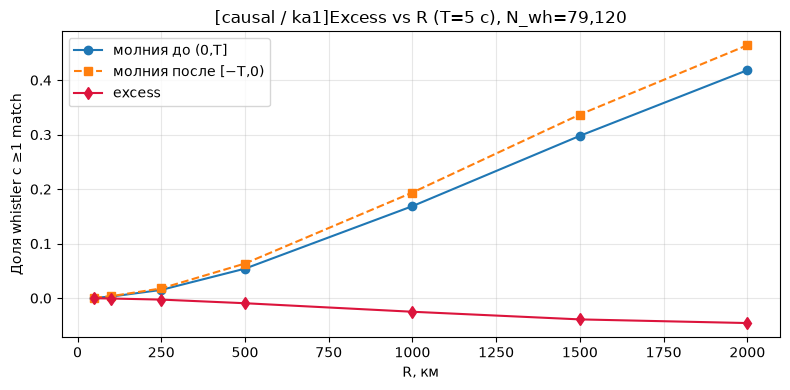

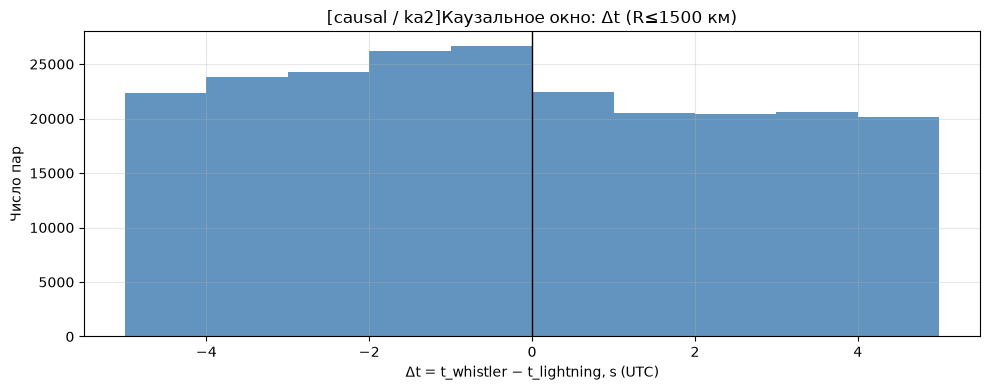

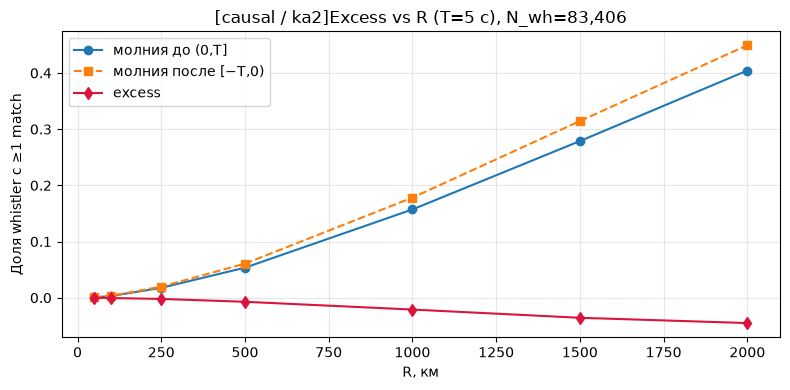

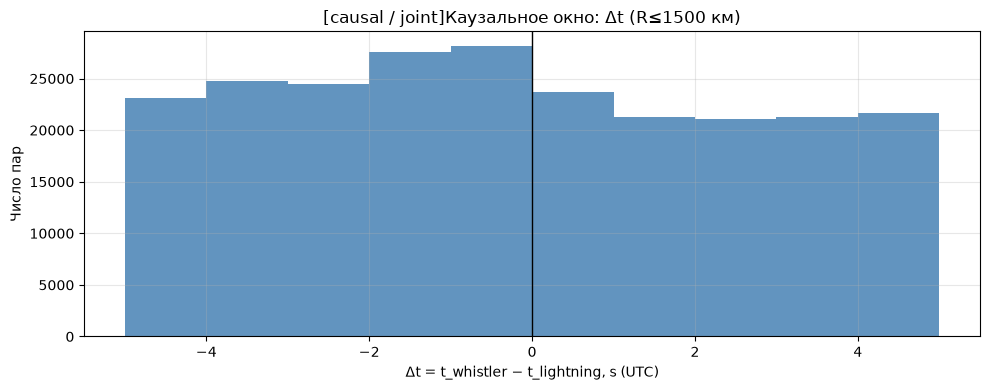

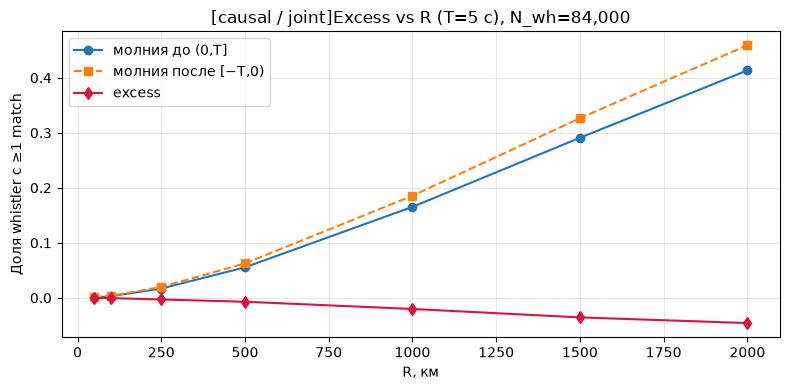

CPU times: user 2min 36s, sys: 12.7 s, total: 2min 49s
Wall time: 2min 58s


In [2]:
%%time
# Каузально: ka1 и ka2 отдельно (+ joint для справки)
res_c_ka1 = wla.run_association(cfg_causal, sc_filter='ka1', verbose=True)
res_c_ka2 = wla.run_association(cfg_causal, sc_filter='ka2', verbose=True)
res_c_all = wla.run_association(cfg_causal, sc_filter=None, verbose=True)

print('N_wh ka1/ka2/all:', res_c_ka1.n_whistlers, res_c_ka2.n_whistlers, res_c_all.n_whistlers)
_ = wla.plot_causal_suite(res_c_ka1, title_prefix='[causal / ka1]')
_ = wla.plot_causal_suite(res_c_ka2, title_prefix='[causal / ka2]')
_ = wla.plot_causal_suite(res_c_all, title_prefix='[causal / joint]')


  [1/21] 20250120: pred=6,715 ae=1,667,999 wh_used=1,116 [causal_only]
  [2/21] 20250202: pred=35,562 ae=1,703,450 wh_used=4,000 [causal_only]
  [3/21] 20250214: pred=35,857 ae=1,724,640 wh_used=4,000 [causal_only]
  [4/21] 20250227: pred=36,877 ae=1,838,768 wh_used=4,000 [causal_only]
  [5/21] 20250312: pred=36,091 ae=2,075,166 wh_used=4,000 [causal_only]
  [6/21] 20250325: pred=37,076 ae=2,229,999 wh_used=4,000 [causal_only]
  [7/21] 20250406: pred=35,919 ae=2,057,904 wh_used=4,000 [causal_only]
  [8/21] 20250419: pred=36,990 ae=2,013,179 wh_used=4,000 [causal_only]
  [9/21] 20250502: pred=36,888 ae=1,947,827 wh_used=4,000 [causal_only]
  [10/21] 20250514: pred=38,043 ae=2,235,423 wh_used=4,000 [causal_only]
  [11/21] 20250527: pred=38,413 ae=2,207,334 wh_used=4,000 [causal_only]
  [12/21] 20250609: pred=37,822 ae=2,186,863 wh_used=3,893 [causal_only]
  [13/21] 20250621: pred=37,018 ae=2,130,039 wh_used=4,000 [causal_only]
  [14/21] 20250704: pred=37,370 ae=2,204,098 wh_used=2,820 [c

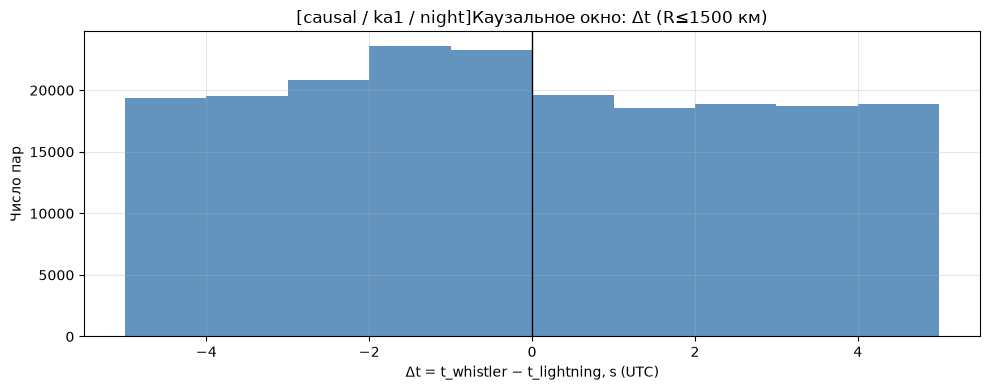

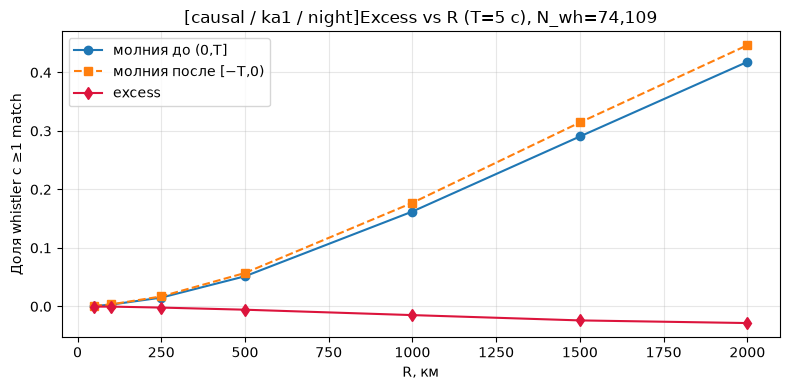

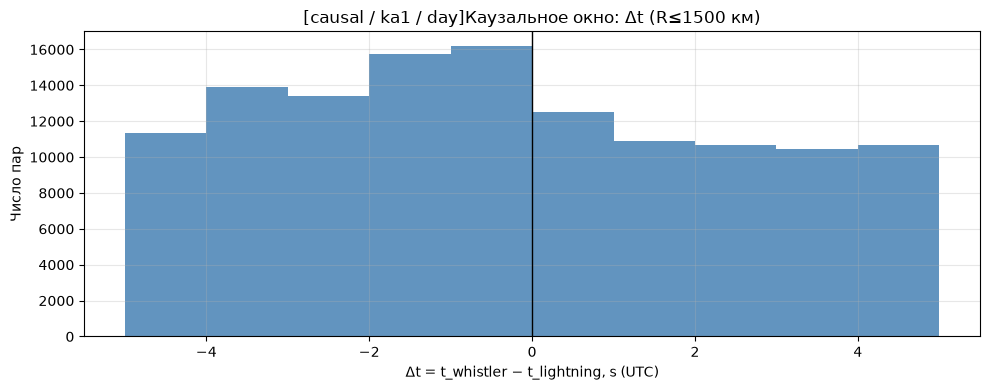

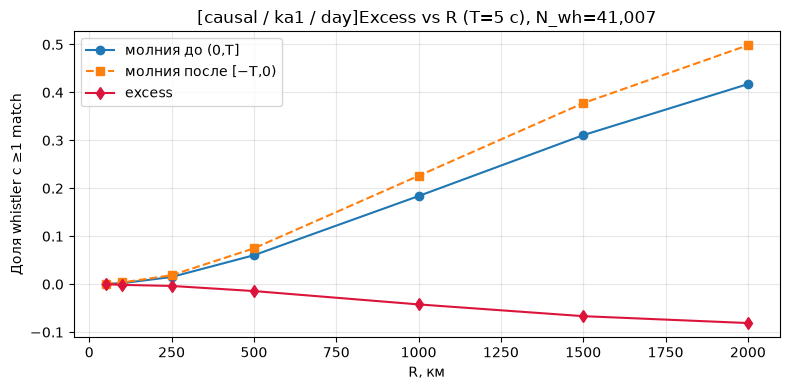

  [1/21] 20250120: pred=30,469 ae=1,667,999 wh_used=4,000 [causal_only]
  [2/21] 20250202: pred=30,005 ae=1,703,450 wh_used=4,000 [causal_only]
  [3/21] 20250214: pred=36,222 ae=1,724,640 wh_used=4,000 [causal_only]
  [4/21] 20250227: pred=36,381 ae=1,838,768 wh_used=4,000 [causal_only]
  [5/21] 20250312: pred=38,078 ae=2,075,166 wh_used=4,000 [causal_only]
  [6/21] 20250325: pred=37,314 ae=2,229,999 wh_used=4,000 [causal_only]
  [7/21] 20250406: pred=34,182 ae=2,057,904 wh_used=4,000 [causal_only]
  [8/21] 20250419: pred=37,725 ae=2,013,179 wh_used=4,000 [causal_only]
  [9/21] 20250502: pred=37,896 ae=1,947,827 wh_used=4,000 [causal_only]
  [10/21] 20250514: pred=35,136 ae=2,235,423 wh_used=4,000 [causal_only]
  [11/21] 20250527: pred=37,089 ae=2,207,334 wh_used=4,000 [causal_only]
  [12/21] 20250609: pred=37,321 ae=2,186,863 wh_used=3,997 [causal_only]
  [13/21] 20250621: pred=35,740 ae=2,130,039 wh_used=4,000 [causal_only]
  [14/21] 20250704: pred=33,929 ae=2,204,098 wh_used=4,000 [

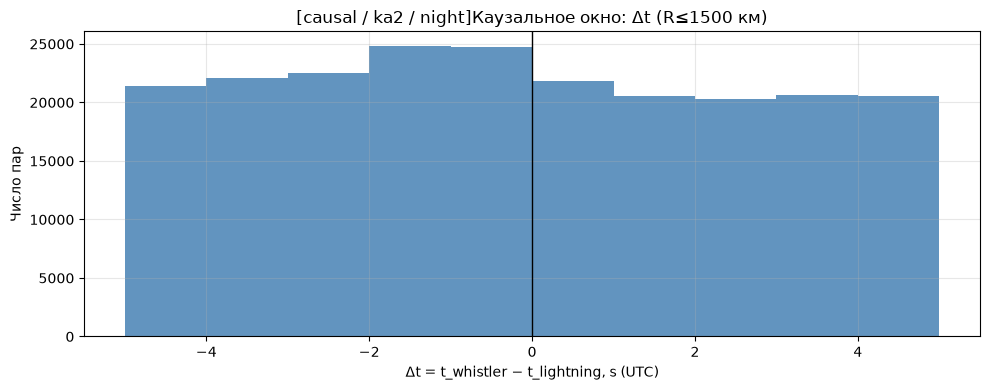

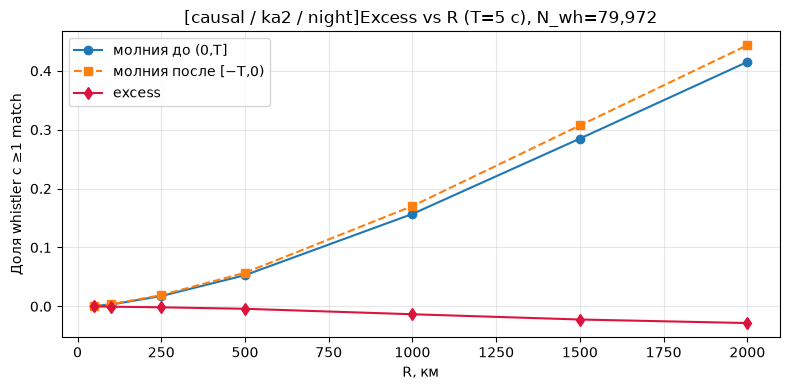

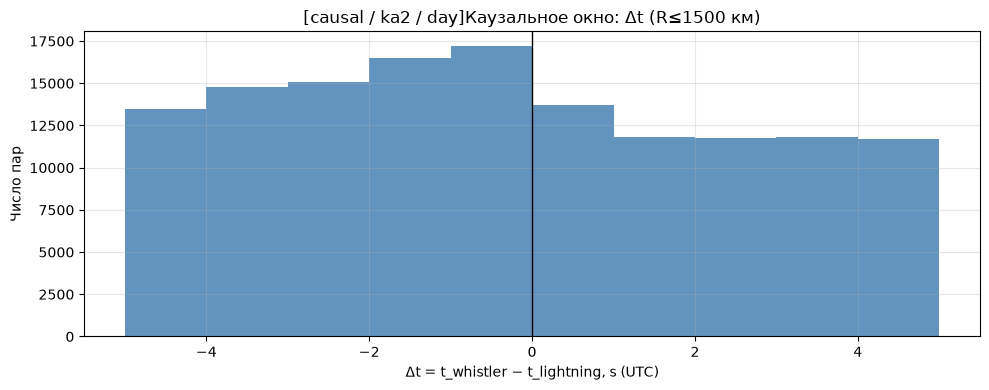

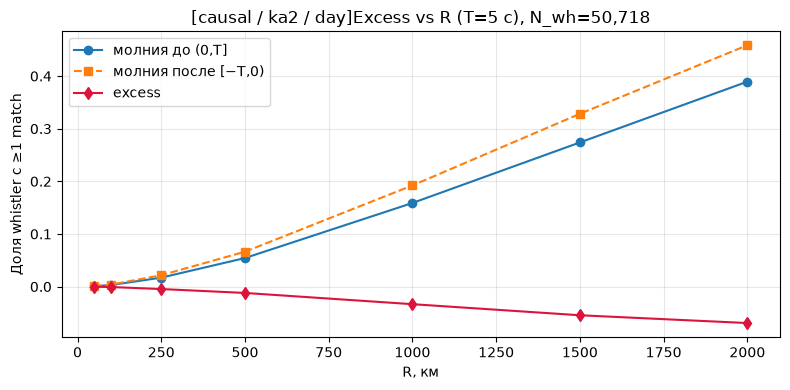

CPU times: user 3min 23s, sys: 15 s, total: 3min 38s
Wall time: 3min 48s


In [3]:
%%time
# Каузальный контроль: ночь / день — отдельно для каждого КА
for sc_name in ['ka1', 'ka2']:
    r_n = wla.run_association(cfg_causal, sc_filter=sc_name, night_filter=1, verbose=True)
    r_d = wla.run_association(cfg_causal, sc_filter=sc_name, night_filter=0, verbose=True)
    _ = wla.plot_causal_suite(r_n, title_prefix=f'[causal / {sc_name} / night]')
    _ = wla.plot_causal_suite(r_d, title_prefix=f'[causal / {sc_name} / day]')


In [4]:
%%time
# Опционально: грубый conjugate (−lat, lon) — ka1/ka2 отдельно.
# Это центрированный диполь, реальная силовая линия смещена (в районе Южно-Атлантической
# аномалии — на тысячи км). Пока не перейдём на трассировку по IGRF, тест мало что проверяет.
res_conj_ka1 = res_conj_ka2 = None
if RUN_CONJUGATE:
    cfg_conj = wla.AssocConfig(**{**cfg_causal.__dict__, 'geometry': 'conjugate'})
    res_conj_ka1 = wla.run_association(cfg_conj, sc_filter='ka1', verbose=True)
    res_conj_ka2 = wla.run_association(cfg_conj, sc_filter='ka2', verbose=True)
    _ = wla.plot_causal_suite(res_conj_ka1, title_prefix='[causal / conjugate / ka1]')
    _ = wla.plot_causal_suite(res_conj_ka2, title_prefix='[causal / conjugate / ka2]')
else:
    print('conjugate пропущен (RUN_CONJUGATE=False): −lat вместо силовой линии IGRF')

conjugate пропущен (RUN_CONJUGATE=False): −lat вместо силовой линии IGRF
CPU times: user 183 μs, sys: 94 μs, total: 277 μs
Wall time: 314 μs


In [5]:
# Сводка каузального блока
import numpy as np
import pandas as pd


def _causal_row(name, res):
    edges = res.causal_dt_edges_s
    centers = 0.5 * (edges[:-1] + edges[1:])
    pos = float(res.causal_hist_pairs[centers > 0].sum())
    neg = float(res.causal_hist_pairs[centers < 0].sum())
    excess = (res.matches_forward - res.matches_chance) / max(res.n_whistlers, 1)
    i1500 = int(np.argmin(np.abs(res.excess_r_km - 1500)))
    return {
        'run': name,
        'дни': f'{res.days[0]}…{res.days[-1]} ({len(res.days)})' if res.days else '—',
        'N_wh': res.n_whistlers,
        'causal_pos/neg': (pos / neg) if neg > 0 else np.nan,
        'excess@1500km': float(excess[i1500]),
        'excess_max': float(np.nanmax(excess)),
        'R_at_excess_max': float(res.excess_r_km[int(np.nanargmax(excess))]),
    }


_runs = [('ka1', globals().get('res_c_ka1')), ('ka2', globals().get('res_c_ka2')),
         ('joint', globals().get('res_c_all')),
         ('conj/ka1', globals().get('res_conj_ka1')),
         ('conj/ka2', globals().get('res_conj_ka2'))]
causal_summary = pd.DataFrame([_causal_row(n, r) for n, r in _runs if r is not None])
display(causal_summary)
print('Успех каузального теста: pos/neg > 1 и excess > 0 (отдельно по ka1 и ka2).')
print('Колонка «дни» должна быть одинаковой у всех строк — иначе строки несравнимы.')

,run,дни,N_wh,causal_pos/neg,excess@1500km,excess_max,R_at_excess_max
0,ka1,20250120…20251031 (21),79120,0.839089,-0.039067,-0.000253,50.0
1,ka2,20250120…20251031 (21),83406,0.845176,-0.035669,-0.000024,50.0
2,joint,20250120…20251031 (21),84000,0.849947,-0.035560,-0.000262,50.0


Успех каузального теста: pos/neg > 1 и excess > 0 (отдельно по ka1 и ka2).
Колонка «дни» должна быть одинаковой у всех строк — иначе строки несравнимы.


### 2. Статистическая ассоциация (минуты–часы)

Здесь уже не время пролёта одного свиста, а связь с грозовой активностью вокруг трассы. Рисунки: `lift(R, Δt)`, вероятность `verdict=1` против расстояния и против времени с последней молнии, и event study.

ka1 и ka2 считаются на 21 сутках каждый, равномерно по своему покрытию (`STAT_MODE = 'spread'`). У ka4 берутся все его сутки: в сохранённом прогоне 10, 21–31 августа 2025. Общие даты трём аппаратам не требуются, список суток печатает ячейка. Каузальные секундные кривые в этом блоке не строятся (`skip_causal=True`), они в разделе выше.

**Как читать карты и кривые**

- Число, которое забираем в сводку, — `lift` в двух заранее выбранных клетках `LIFT_REF_CELLS`: 100 км / 5 мин и 1000 км / 30 мин. На картах они обведены белым квадратом. Максимум `lift` по всей сетке в отчёт не идёт: он уезжает в угол больших R и Δt, где группа «без молнии» почти пустая.
- Пустая клетка на карте — в одной из двух групп меньше 200 наблюдений, оценку туда не ставим. На малом радиусе такое обычно: разряд в 50 км от подспутниковой точки редок.
- Карты вероятности нарисованы дважды. Общая цветовая шкала позволяет сравнивать уровень между панелями. Своя шкала у каждой панели показывает форму внутри карты; уровни панелей тогда несравнимы.
- На кривой `P` против времени последняя точка — это всё ещё внутри окна 180 минут. Секунды, у которых молнии в радиусе не было, вынесены отдельной серой линией.
- Ночь — тот же порог `SZA > 98°`.

**Event study.** Сравнение в одной и той же точке: меняется только время относительно момента, когда вероятность свиста скачком выросла. География из отношения `real/null` выпадает. Окно ±30 минут, бины по 5 минут, чтобы кривая показывала отклик на этот момент, а не суточный ход гроз в этом месте.


In [15]:
# === Статистический блок: самодостаточен, не зависит от каузального ===
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
import whistler_lightning_assoc as wla

importlib.reload(wc)
importlib.reload(wla)

PATHS = wc.resolve_paths()
STAT_SC = ('ka1', 'ka2', 'ka4')

# Какие сутки берём. У каждого КА — СВОЁ покрытие (пересечения не требуем):
# У каждого аппарата свои сутки. В сохранённом прогоне у ka4 — конец августа 2025.
# Точность ограничена числом независимых суток, не числом секунд в дне.
#   'pilot'  — N суток подряд с начала покрытия КА
#   'spread' — N суток равномерно по покрытию этого КА
#   'full'   — все сутки КА
STAT_MODE = 'spread'
N_STAT_DAYS = 21

STAT_DAYS_BY_SC = wc.days_by_sc(
    PATHS['pred'], PATHS['ae'], STAT_SC, n_per_sc=N_STAT_DAYS, mode=STAT_MODE,
)
# для сезонного контроля ниже — пересечение ka1∩ka2, без ka4:
# у ka4 нет января/апреля/…
STAT_DAYS_ALL = wc.analysis_days(PATHS['pred'], PATHS['ae'], ('ka1', 'ka2'))

for _sc, _days in STAT_DAYS_BY_SC.items():
    _all = wc.sc_days(PATHS['pred'], PATHS['ae'], _sc)
    if _days:
        print(f'{_sc}: покрытие {_all[0]}…{_all[-1]} ({len(_all)} сут) → '
              f'{STAT_MODE} {len(_days)} сут ({_days[0]}…{_days[-1]})')
    else:
        print(f'{_sc}: нет суток с AE')

# Ячейки сетки, по которым отчитываемся. Выбраны ЗАРАНЕЕ: максимум по сетке —
# это максимум из десятков коррелированных оценок, он смещён вверх и садится в
# дальний угол (максимальные R и Δt), где «неэкспонированных» почти не остаётся
# и где контраст на деле означает «тропики против приполярья».
# Значения снапятся к ближайшим узлам cfg_stat.stat_r_km / stat_dt_min.
LIFT_REF_CELLS = ((100.0, 5.0), (1000.0, 30.0))

# Шаблон конфига; day_list подставляется отдельно для каждого КА в ячейке ниже.
cfg_stat = wla.AssocConfig(
    pred_dir=PATHS['pred'],
    ae_dir=PATHS['ae'],
    sc_list=STAT_SC,
    geometry='satellite',
    energy_min=None,
    day_list=None,
    max_days=None,
    max_points_per_day=12000,
    causal_only=False,
    skip_causal=True,   # каузальную часть считает свой блок
    night_sza_deg=wc.NIGHT_SZA_DEG,
    # Event study: узкое окно, где вопрос вообще осмыслен — «есть ли всплеск
    # молний в момент включения свиста». Прежние ±12 ч в часовых бинах показывали
    # суточный ход грозовой активности места, а не отклик на onset.
    event_r_km=1000.0,
    event_pre_h=0.5,
    event_post_h=0.5,
    event_bin_h=1 / 12,        # 5-минутные бины
    max_onsets_per_sc_day=200,
    time_near_r_km=250.0,      # вторая кривая на рисунке P vs время
)

_n_days_total = sum(len(d) for d in STAT_DAYS_BY_SC.values())
_sec_day = 25 if STAT_MODE == 'spread' else 20
print(f'Статистика [{STAT_MODE}]: {STAT_SC}, суммарно {_n_days_total} КА·суток, '
      f'{cfg_stat.max_points_per_day:,} точек/сутки, ночь = SZA > {wc.NIGHT_SZA_DEG:.0f}°')
print(f'Ожидаемое время ячейки ниже: ~{_sec_day * _n_days_total / 60:.0f} мин '
      f'(~{_sec_day} с на КА·сутки)')
print(f'Сетка R, км: {cfg_stat.stat_r_km}')
print(f'Сетка Δt, мин: {cfg_stat.stat_dt_min} (окно поиска = {max(cfg_stat.stat_dt_min):.0f} мин)')
print(f'Опорные ячейки для lift: {LIFT_REF_CELLS}')
print(f'P vs время: R≤{cfg_stat.time_near_r_km:.0f} км и '
      f'R≤{max(cfg_stat.stat_r_km):.0f} км')


ka1: покрытие 20250120…20251031 (255 сут) → spread 21 сут (20250120…20251031)
ka2: покрытие 20250101…20251031 (272 сут) → spread 21 сут (20250101…20251031)
ka4: покрытие 20250821…20250831 (10 сут) → spread 10 сут (20250821…20250831)
Статистика [spread]: ('ka1', 'ka2', 'ka4'), суммарно 52 КА·суток, 12,000 точек/сутки, ночь = SZA > 98°
Ожидаемое время ячейки ниже: ~22 мин (~25 с на КА·сутки)
Сетка R, км: (50, 100, 250, 500, 1000, 1500, 2000)
Сетка Δt, мин: (1, 5, 15, 30, 60, 120, 180) (окно поиска = 180 мин)
Опорные ячейки для lift: ((100.0, 5.0), (1000.0, 30.0))
P vs время (ячейка 41): R≤250 км и R≤2000 км


  [1/21] 20250120: pred=15,158 ae=1,667,999 wh_used=0
  [2/21] 20250202: pred=80,032 ae=1,703,450 wh_used=0
  [3/21] 20250214: pred=84,114 ae=1,724,640 wh_used=0
  [4/21] 20250227: pred=86,386 ae=1,838,768 wh_used=0
  [5/21] 20250312: pred=85,553 ae=2,075,166 wh_used=0
  [6/21] 20250325: pred=86,394 ae=2,229,999 wh_used=0
  [7/21] 20250406: pred=82,000 ae=2,057,904 wh_used=0
  [8/21] 20250419: pred=85,719 ae=2,013,179 wh_used=0
  [9/21] 20250502: pred=86,308 ae=1,947,827 wh_used=0
  [10/21] 20250514: pred=86,178 ae=2,235,423 wh_used=0
  [11/21] 20250527: pred=86,397 ae=2,207,334 wh_used=0
  [12/21] 20250609: pred=86,396 ae=2,186,863 wh_used=0
  [13/21] 20250621: pred=84,639 ae=2,130,039 wh_used=0
  [14/21] 20250704: pred=85,927 ae=2,204,098 wh_used=0
  [15/21] 20250717: pred=64,799 ae=2,000,877 wh_used=0
  [16/21] 20250729: pred=86,056 ae=2,144,708 wh_used=0
  [17/21] 20250811: pred=86,396 ae=2,281,619 wh_used=0
  [18/21] 20250824: pred=85,543 ae=2,280,758 wh_used=0
  [19/21] 20251006:

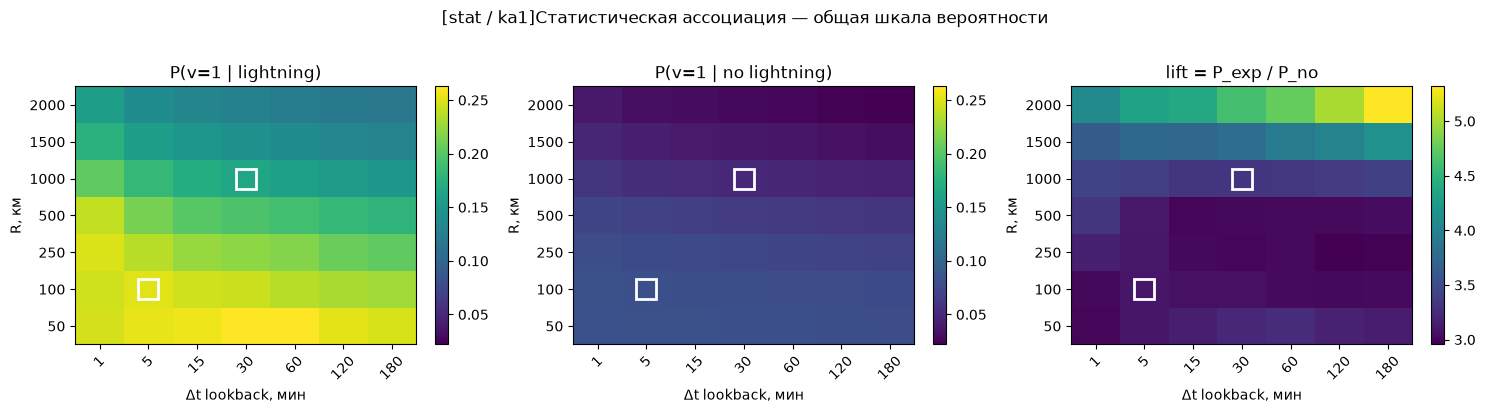

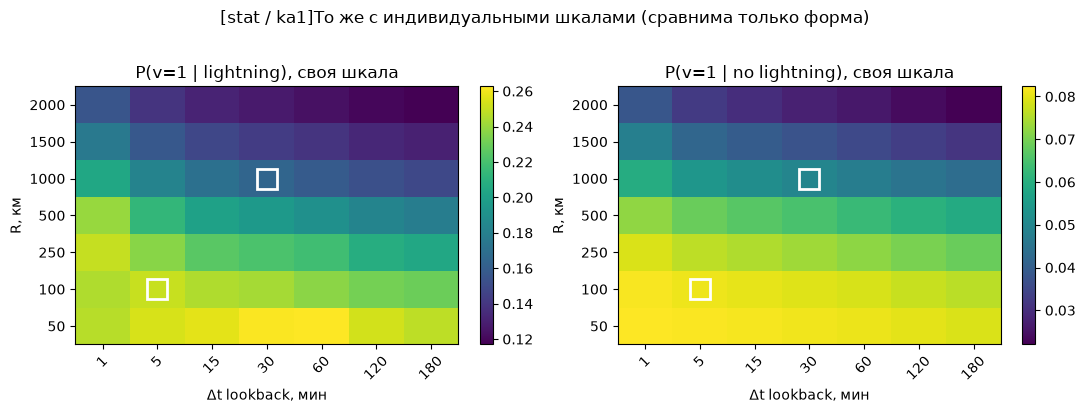

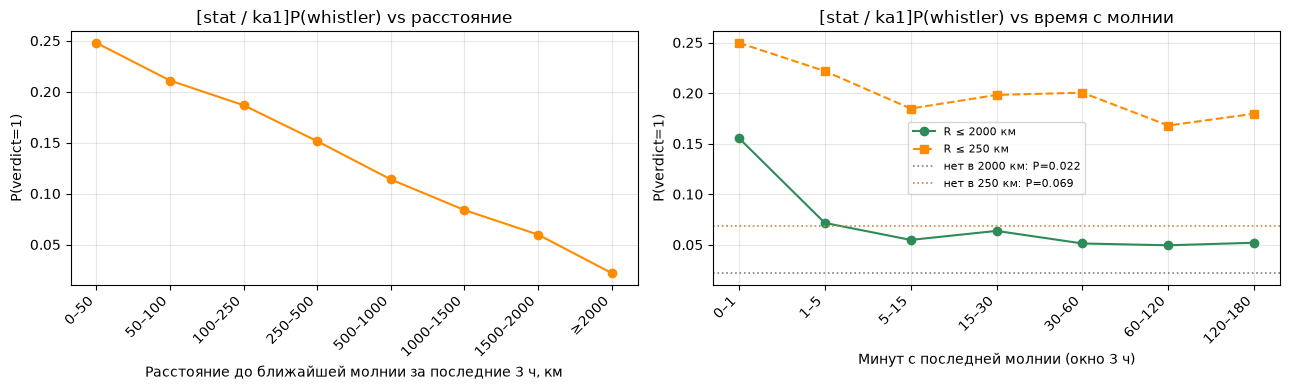

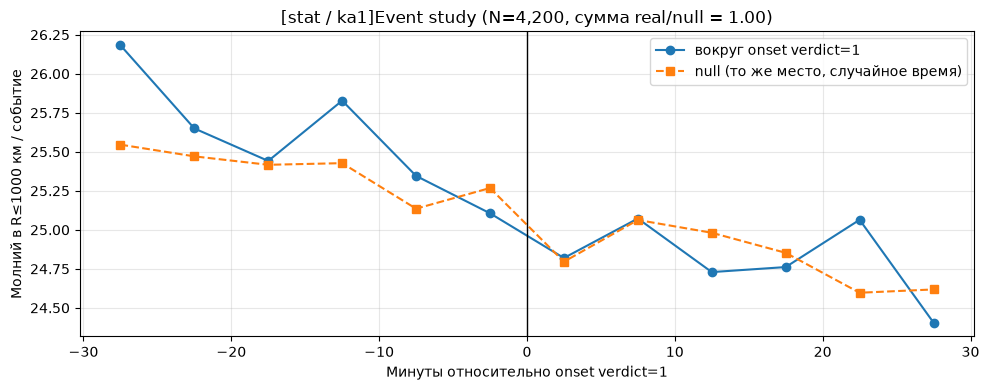

ka1 R=100 км Δt=5 мин: P(есть)=0.2505 (n=2,754) P(нет)=0.0808 (n=249,246) lift=3.10
ka1 R=1000 км Δt=30 мин: P(есть)=0.1646 (n=72,520) P(нет)=0.0495 (n=179,480) lift=3.32
  [1/21] 20250101: pred=79,571 ae=1,359,513 wh_used=0
  [2/21] 20250117: pred=84,475 ae=1,796,799 wh_used=0
  [3/21] 20250130: pred=73,981 ae=1,916,279 wh_used=0
  [4/21] 20250213: pred=77,522 ae=1,745,810 wh_used=0
  [5/21] 20250226: pred=78,366 ae=1,780,606 wh_used=0
  [6/21] 20250312: pred=86,345 ae=2,075,166 wh_used=0
  [7/21] 20250325: pred=86,217 ae=2,229,999 wh_used=0
  [8/21] 20250408: pred=86,376 ae=2,080,780 wh_used=0
  [9/21] 20250421: pred=79,865 ae=1,957,045 wh_used=0
  [10/21] 20250505: pred=86,357 ae=1,947,414 wh_used=0
  [11/21] 20250519: pred=86,396 ae=2,122,798 wh_used=0
  [12/21] 20250601: pred=86,396 ae=2,140,242 wh_used=0
  [13/21] 20250615: pred=86,135 ae=2,247,679 wh_used=0
  [14/21] 20250628: pred=85,594 ae=2,152,405 wh_used=0
  [15/21] 20250712: pred=85,488 ae=2,187,105 wh_used=0
  [16/21] 202

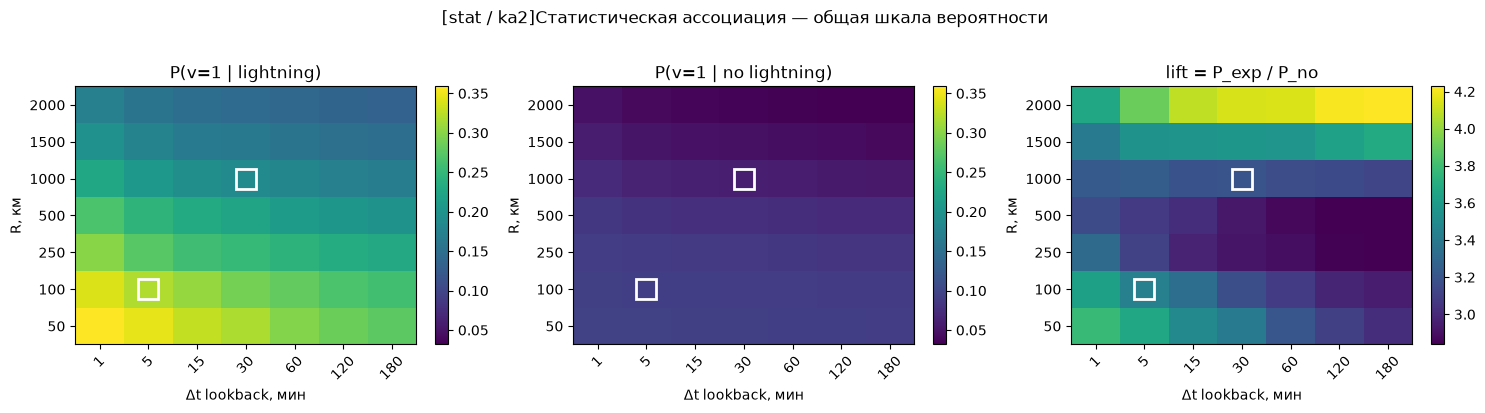

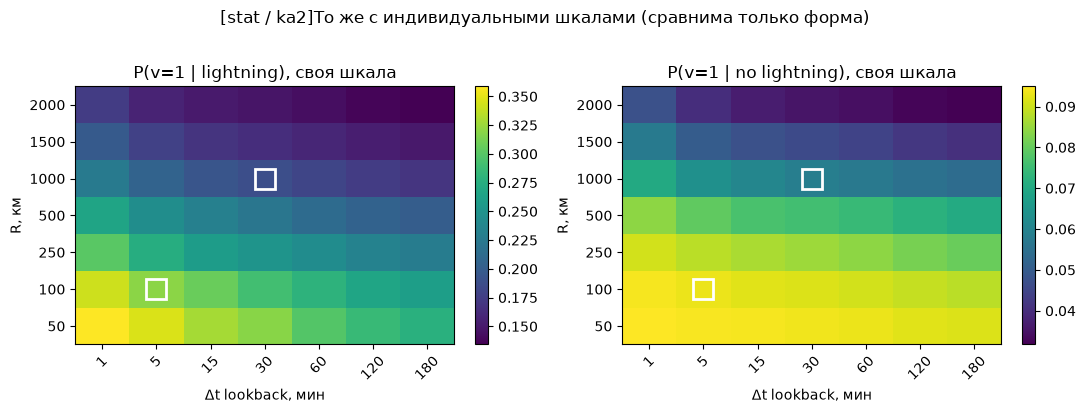

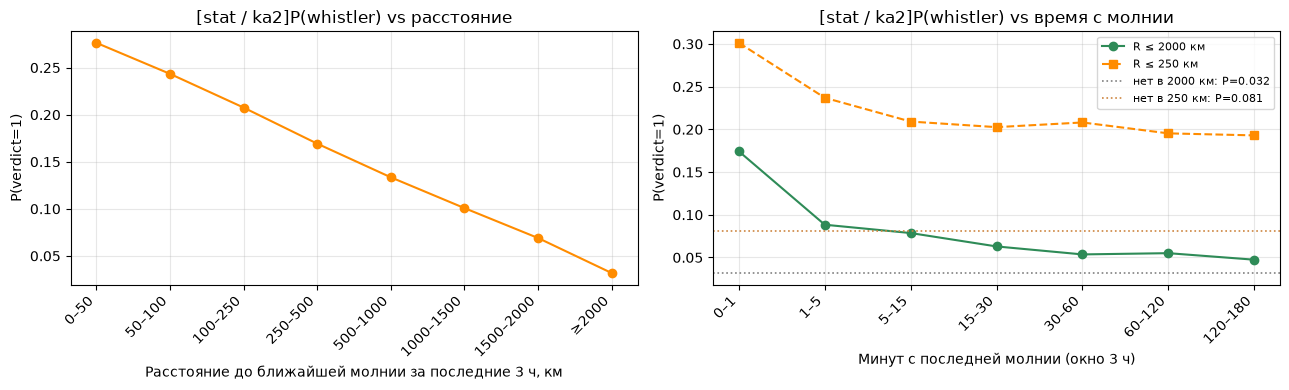

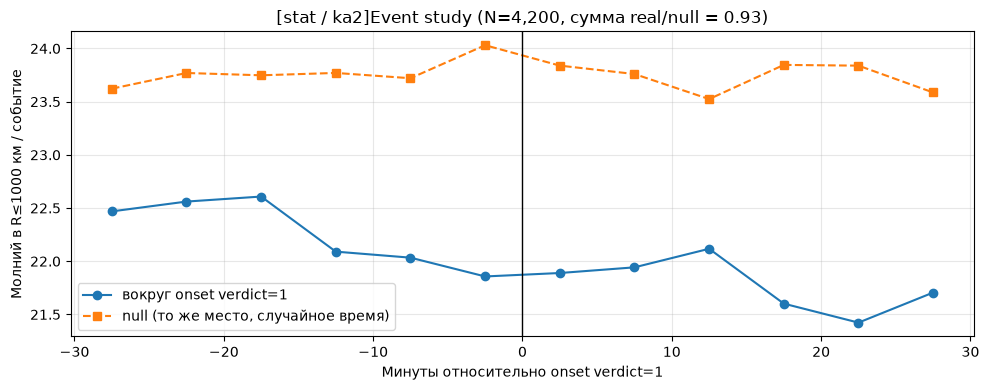

ka2 R=100 км Δt=5 мин: P(есть)=0.3200 (n=2,591) P(нет)=0.0930 (n=249,409) lift=3.44
ka2 R=1000 км Δt=30 мин: P(есть)=0.1878 (n=71,425) P(нет)=0.0587 (n=180,575) lift=3.20
  [1/10] 20250821: pred=13,397 ae=2,204,260 wh_used=0
  [2/10] 20250823: pred=13,397 ae=2,264,014 wh_used=0
  [3/10] 20250824: pred=84,566 ae=2,280,758 wh_used=0
  [4/10] 20250825: pred=85,659 ae=2,309,291 wh_used=0
  [5/10] 20250826: pred=85,853 ae=2,373,841 wh_used=0
  [6/10] 20250827: pred=84,299 ae=2,418,752 wh_used=0
  [7/10] 20250828: pred=85,725 ae=2,454,888 wh_used=0
  [8/10] 20250829: pred=78,928 ae=2,428,676 wh_used=0
  [9/10] 20250830: pred=76,328 ae=2,393,960 wh_used=0
  [10/10] 20250831: pred=85,360 ae=2,374,033 wh_used=0


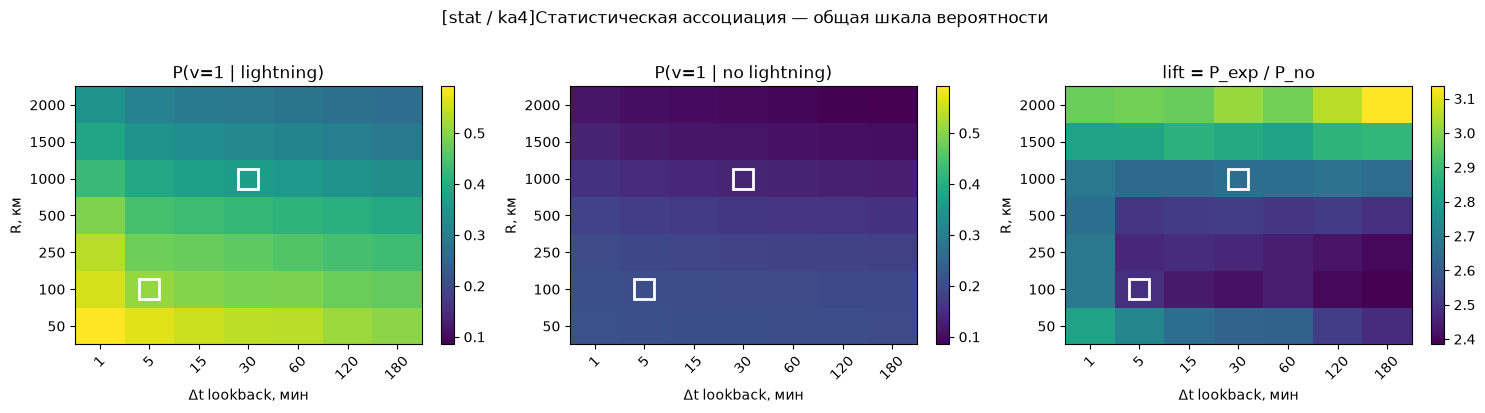

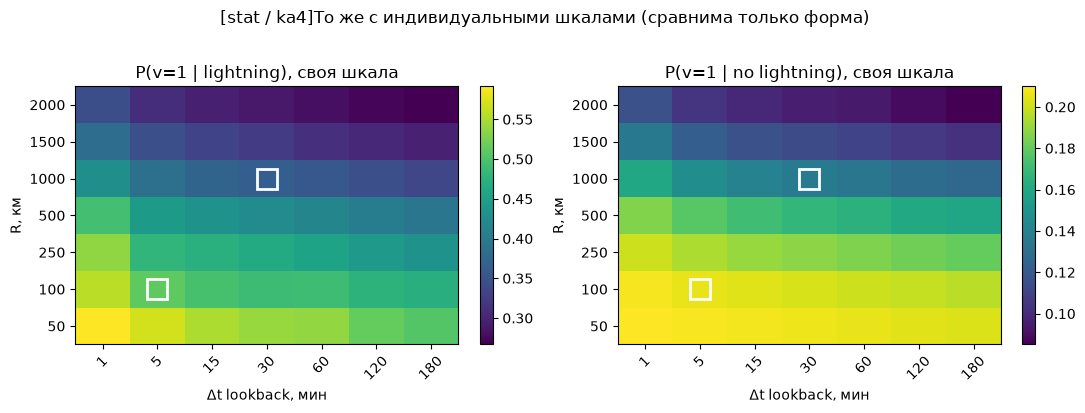

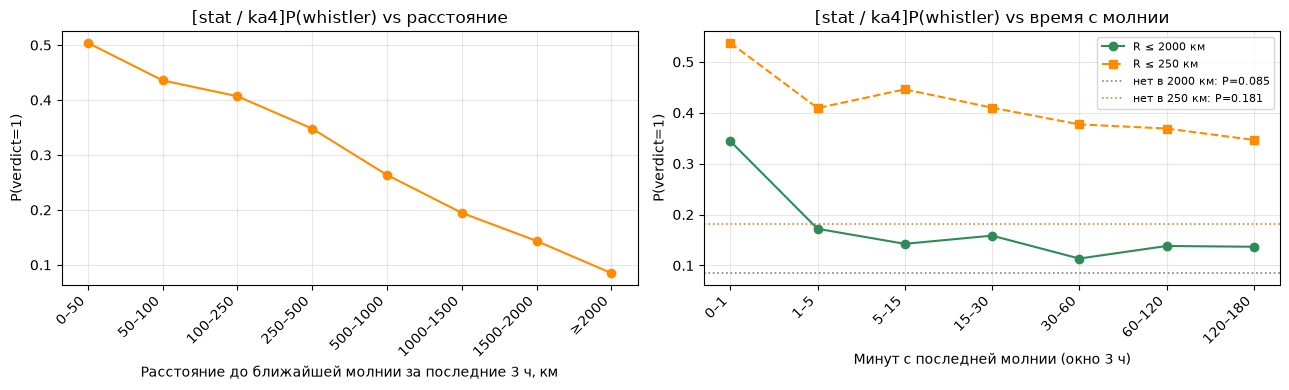

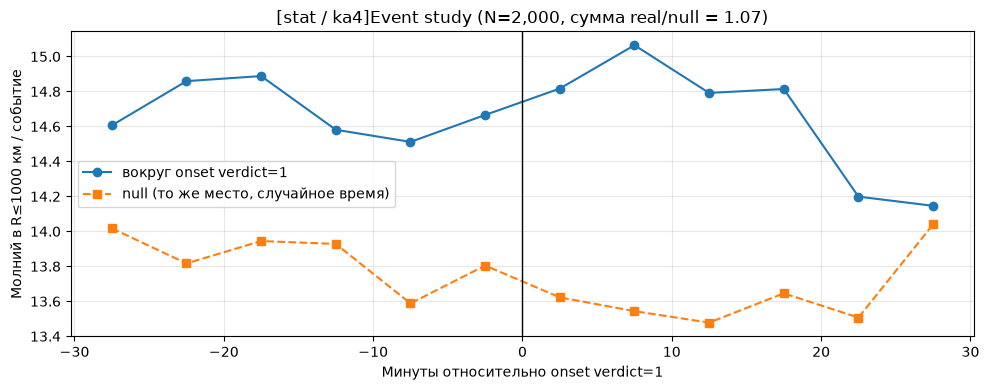

ka4 R=100 км Δt=5 мин: P(есть)=0.5110 (n=2,092) P(нет)=0.2056 (n=117,908) lift=2.49
ka4 R=1000 км Δt=30 мин: P(есть)=0.3642 (n=38,970) P(нет)=0.1372 (n=81,030) lift=2.65
CPU times: user 17min 19s, sys: 1min 30s, total: 18min 50s
Wall time: 19min 7s


In [16]:
%%time
# У каждого КА — свой day_list (равномерность по его покрытию года).
res_s = {}
for sc in STAT_SC:
    days = STAT_DAYS_BY_SC[sc]
    if not days:
        print(f'{sc}: пропуск — нет суток')
        continue
    cfg = wla.AssocConfig(**{**cfg_stat.__dict__, 'day_list': days, 'sc_list': (sc,)})
    r = wla.run_association(cfg, sc_filter=sc, verbose=True)
    res_s[sc] = r
    _ = wla.plot_statistical_suite(r, title_prefix=f'[stat / {sc}]',
                                   mark_cells=LIFT_REF_CELLS)
    for _R, _dt in LIFT_REF_CELLS:
        _v = wla.lift_at(r, _R, _dt)
        print(f"{sc} R={_v['R_km']:.0f} км Δt={_v['dt_min']:.0f} мин: "
              f"P(есть)={_v['P_exp']:.4f} (n={_v['n_exp']:,.0f}) "
              f"P(нет)={_v['P_no']:.4f} (n={_v['n_no']:,.0f}) lift={_v['lift']:.2f}")

# алиасы для сводки / старых ячеек
res_s_ka1 = res_s.get('ka1')
res_s_ka2 = res_s.get('ka2')
res_s_ka4 = res_s.get('ka4')


ka1 R=100 Δt=5: night lift=2.32 (P=0.3073/0.1326), day lift=3.78 (P=0.1528/0.0405)
ka1 R=1000 Δt=30: night lift=2.74 (P=0.2341/0.0856), day lift=4.26 (P=0.0968/0.0227)


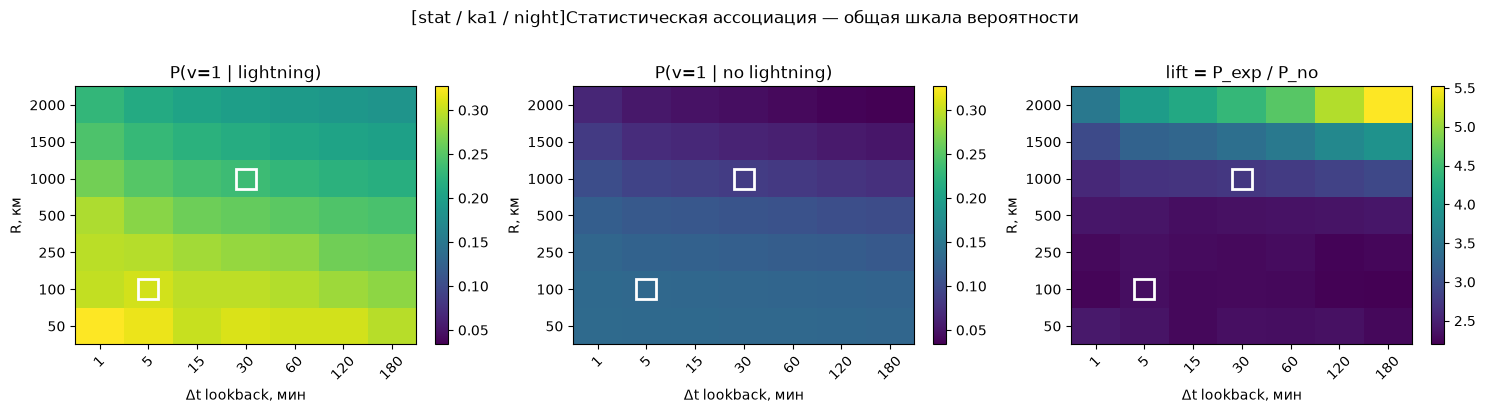

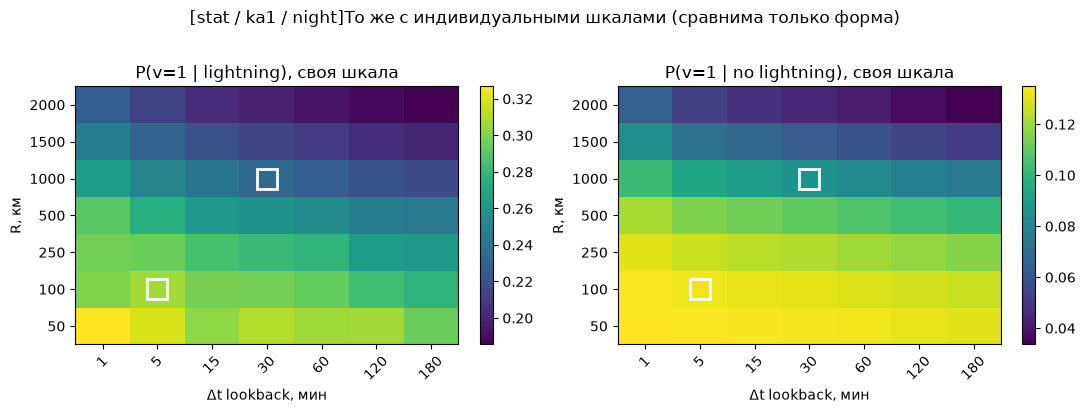

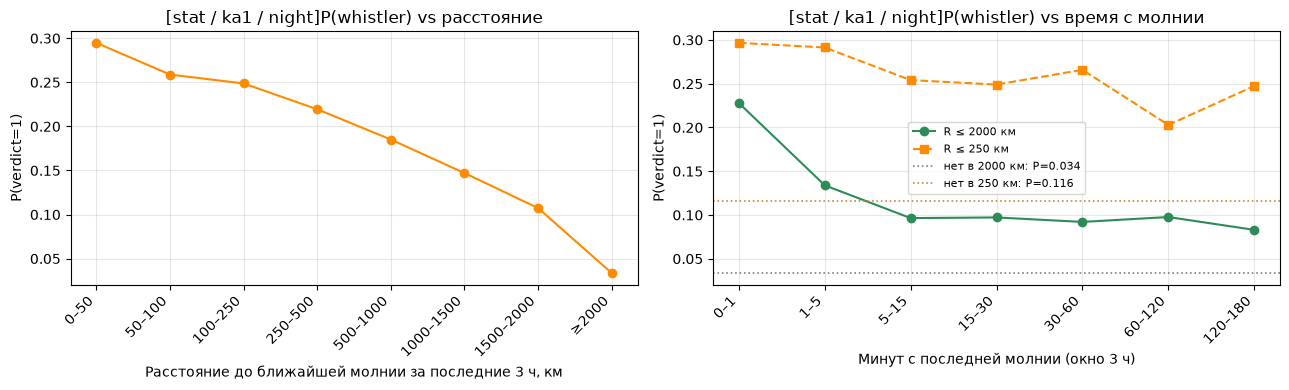

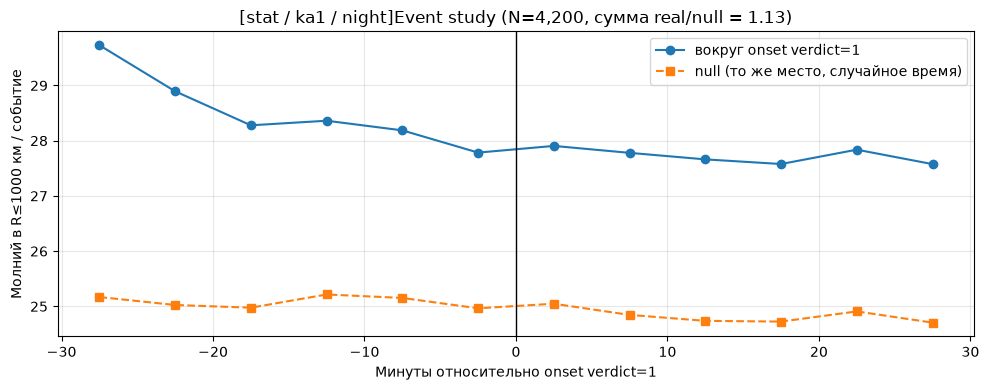

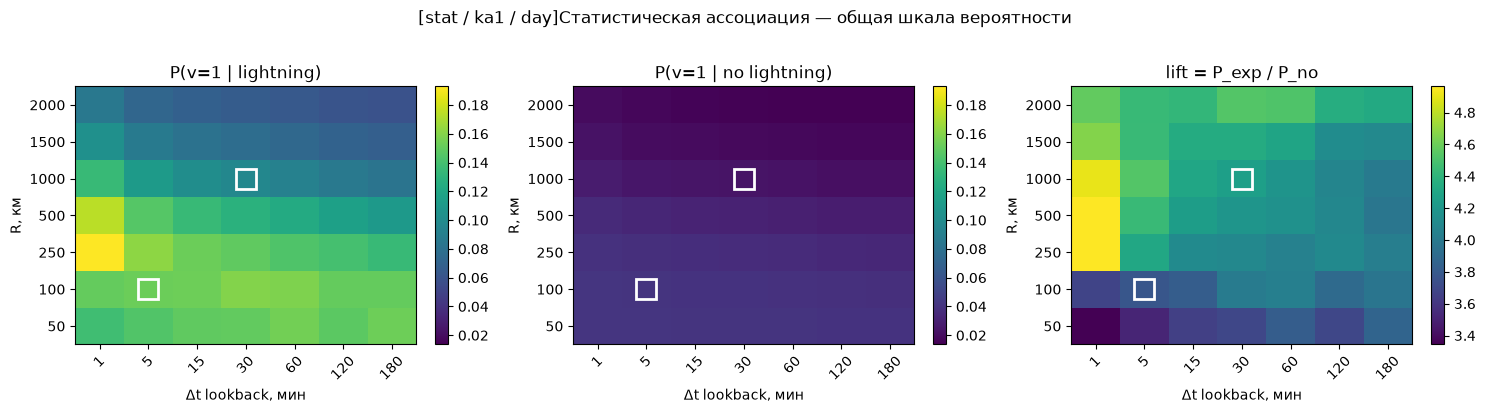

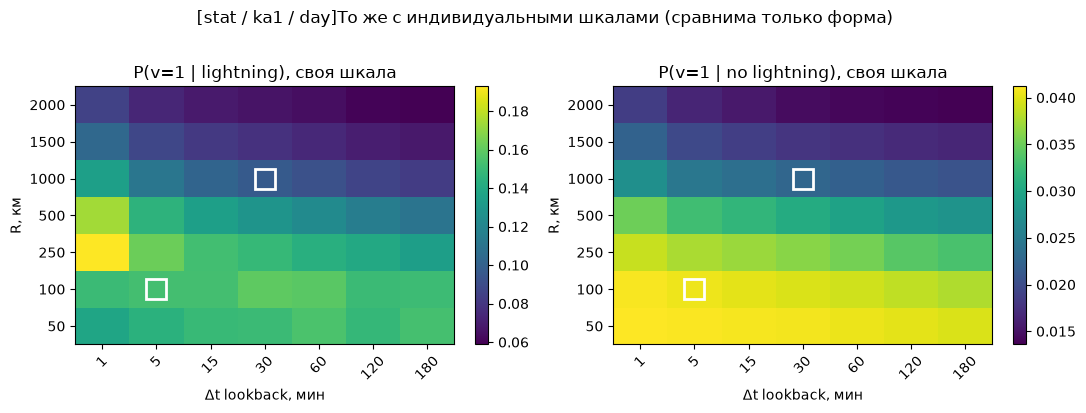

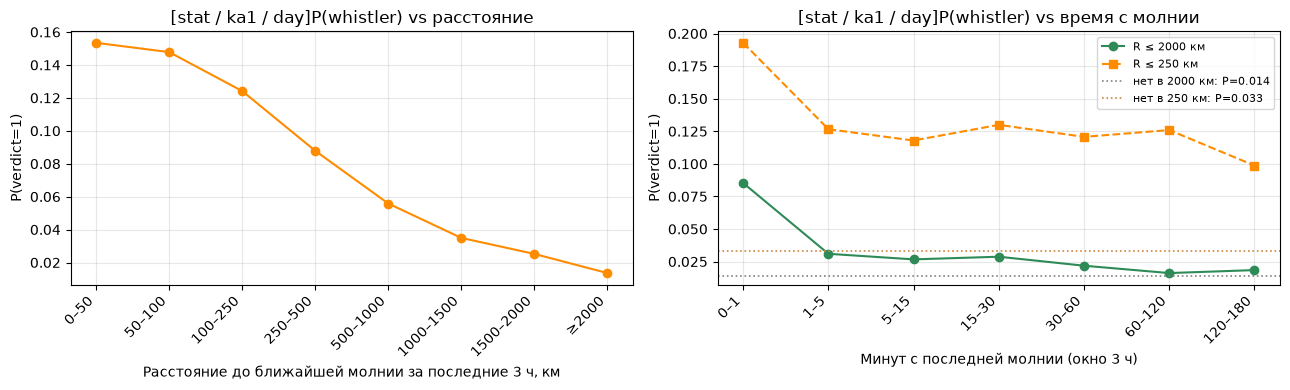

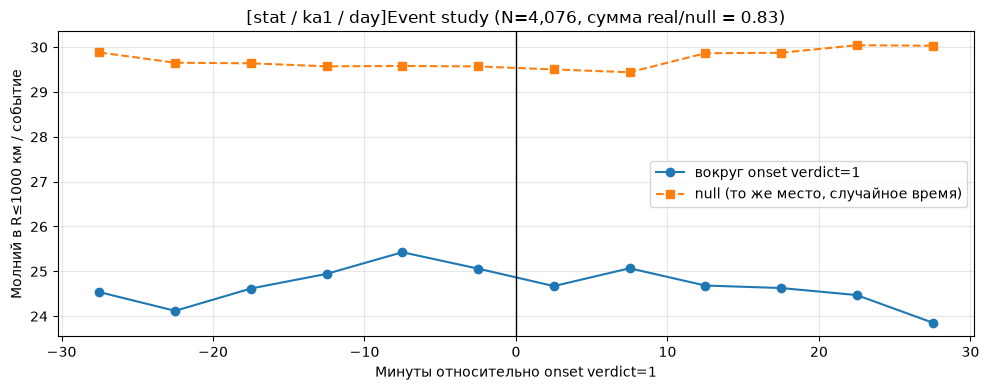

ka2 R=100 Δt=5: night lift=2.36 (P=0.3342/0.1417), day lift=4.87 (P=0.2646/0.0543)
ka2 R=1000 Δt=30: night lift=2.65 (P=0.2467/0.0930), day lift=3.46 (P=0.1211/0.0349)


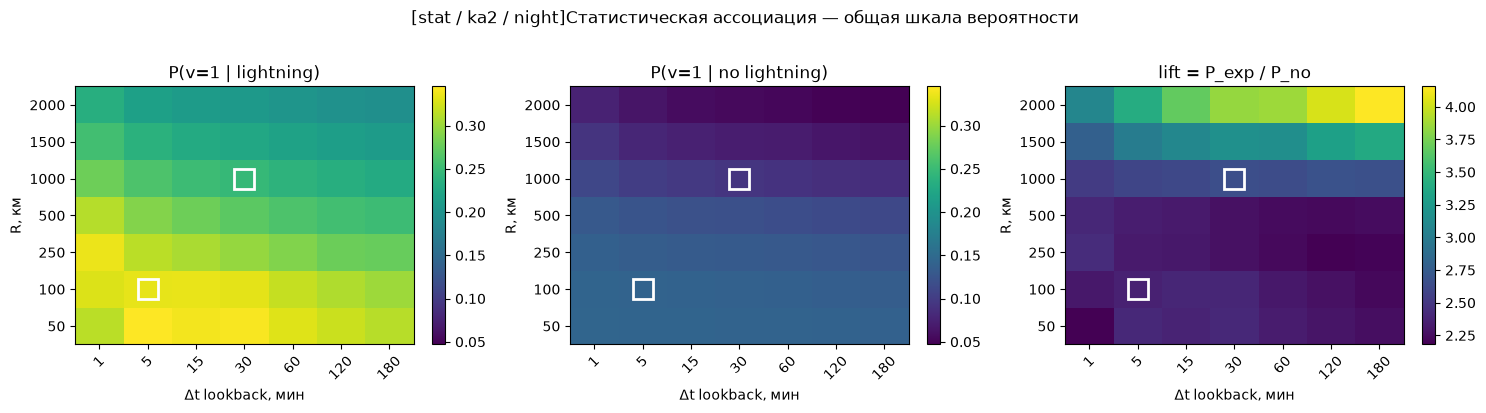

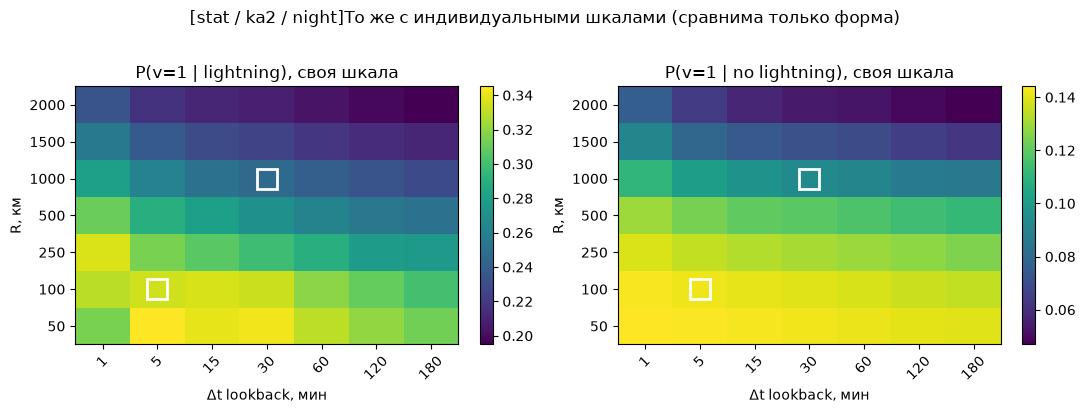

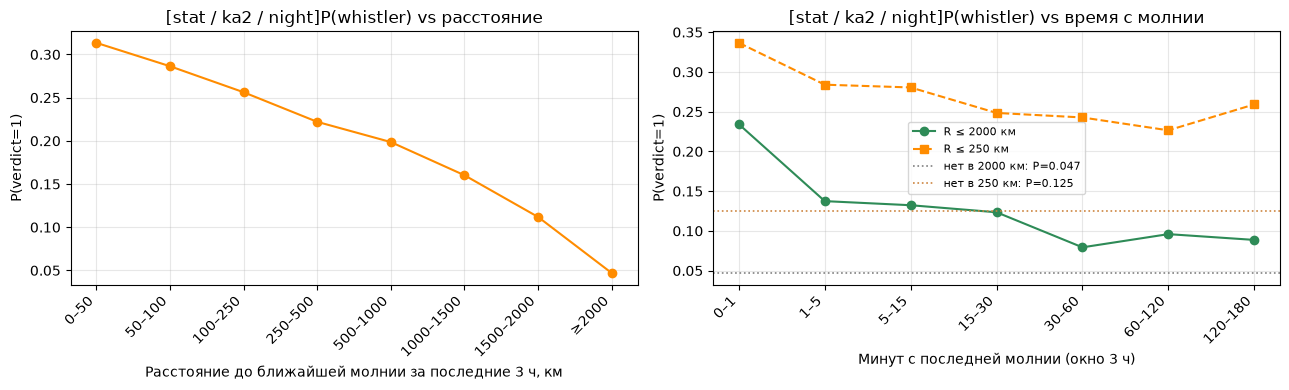

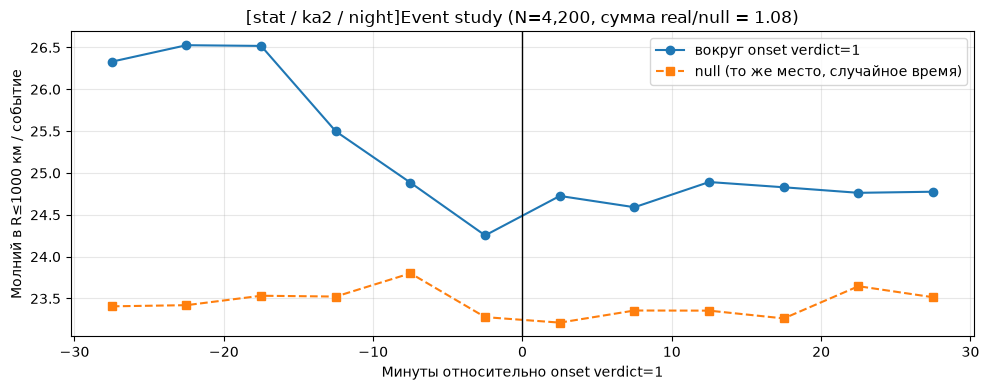

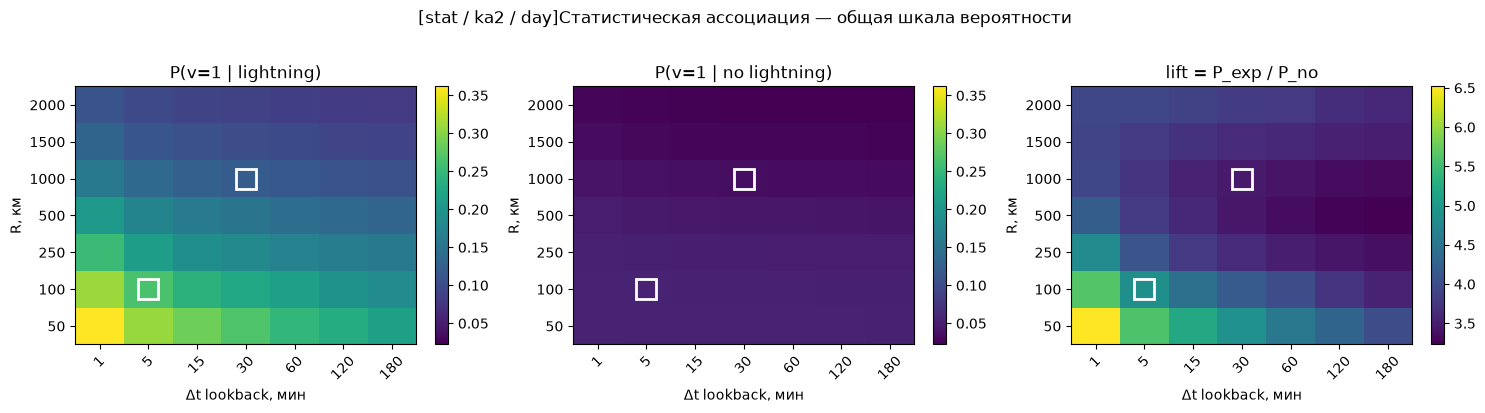

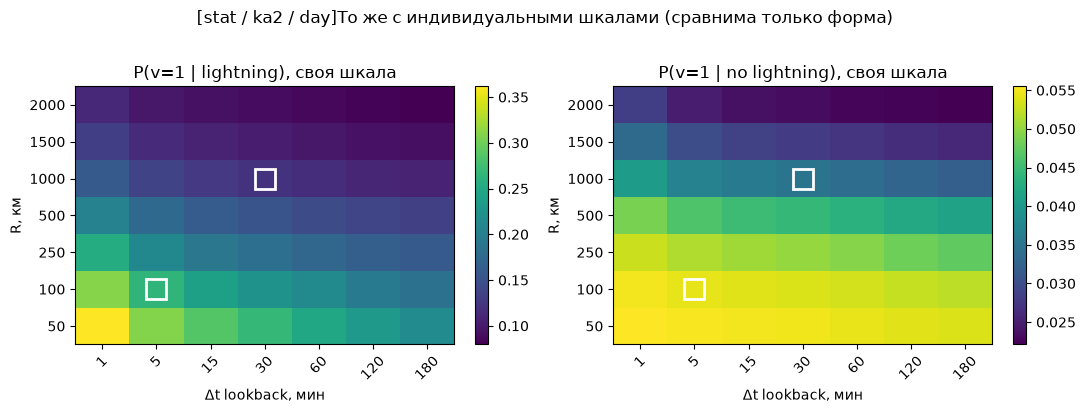

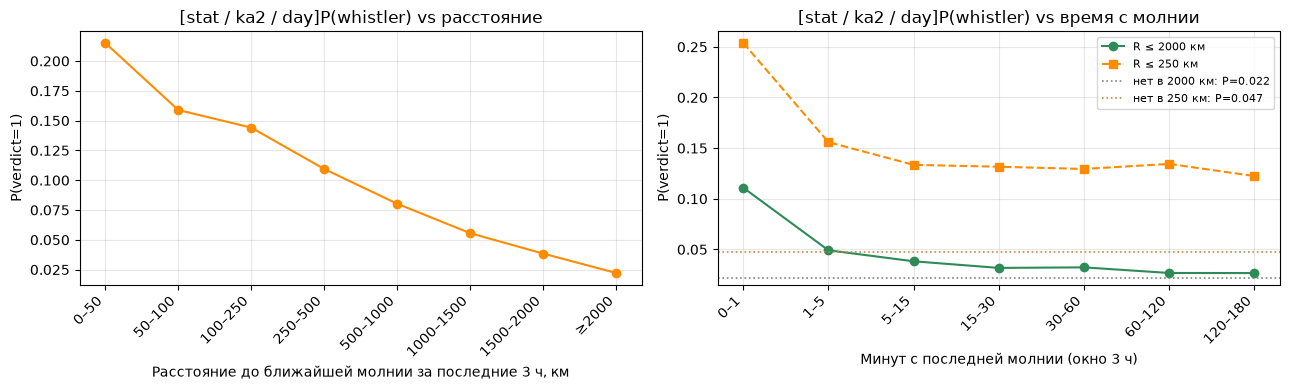

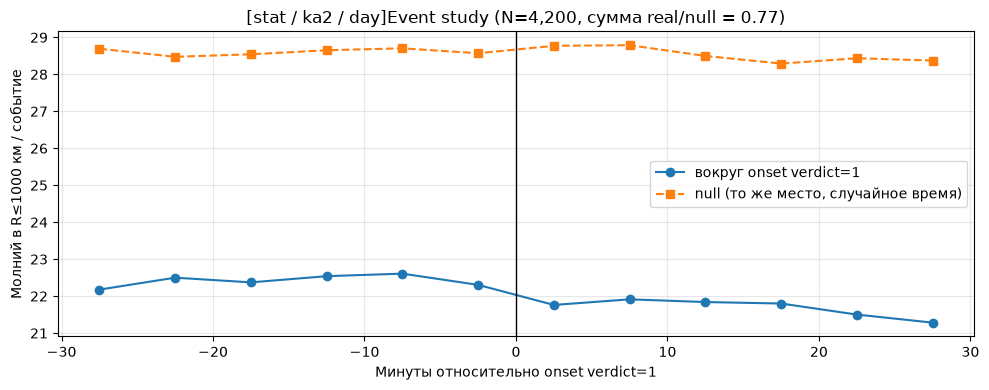

ka4 R=100 Δt=5: night lift=2.05 (P=0.4902/0.2389), day lift=2.85 (P=0.5678/0.1994)
ka4 R=1000 Δt=30: night lift=2.22 (P=0.3811/0.1717), day lift=2.97 (P=0.3728/0.1257)


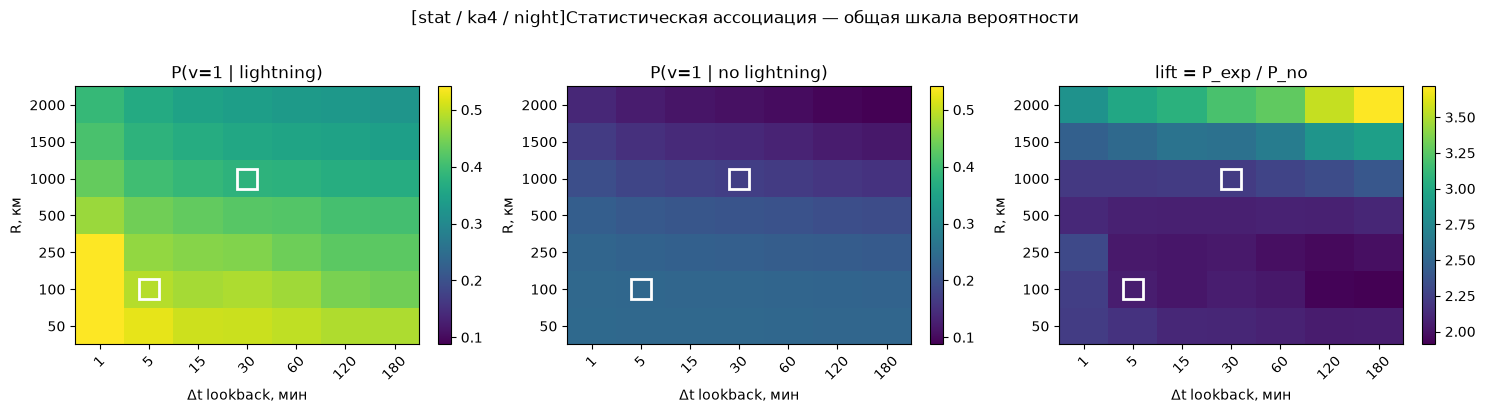

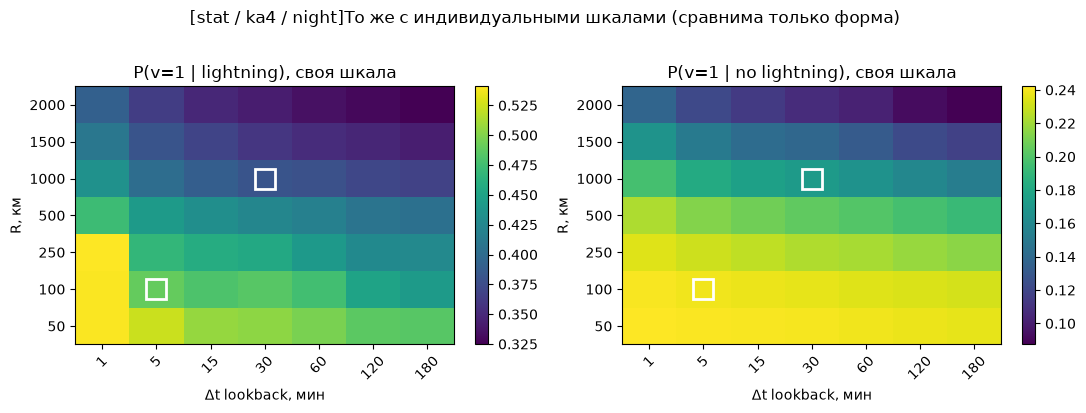

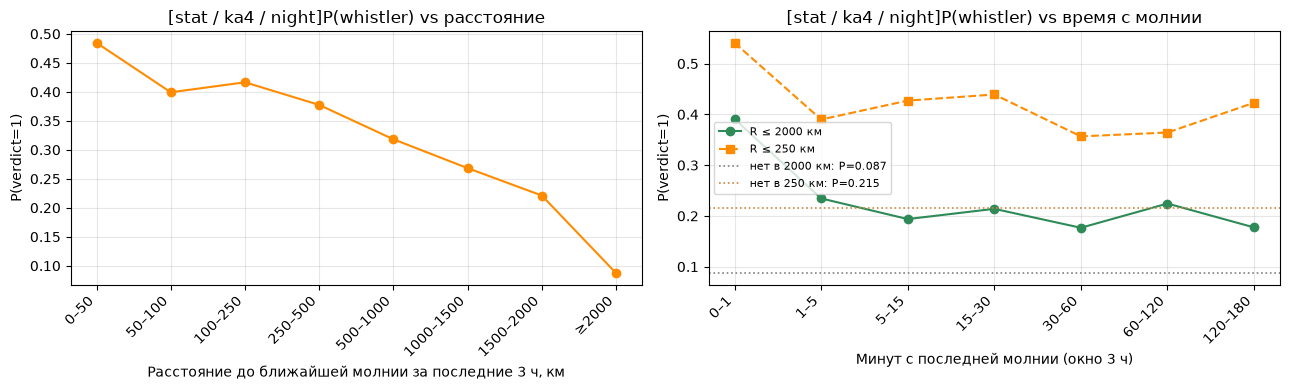

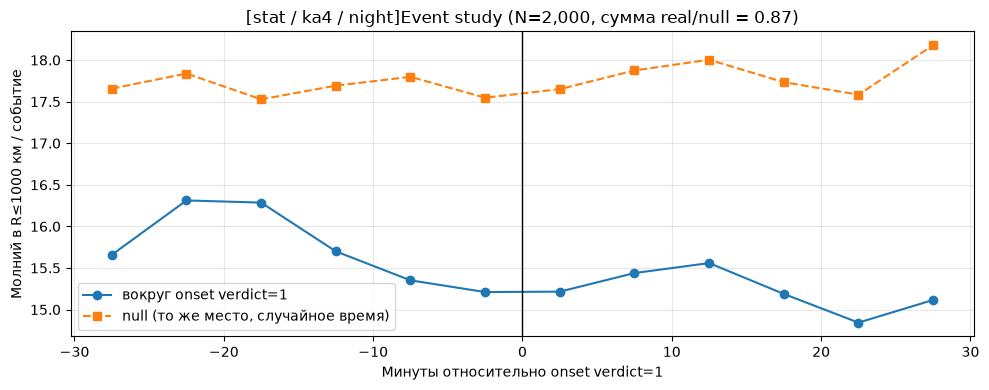

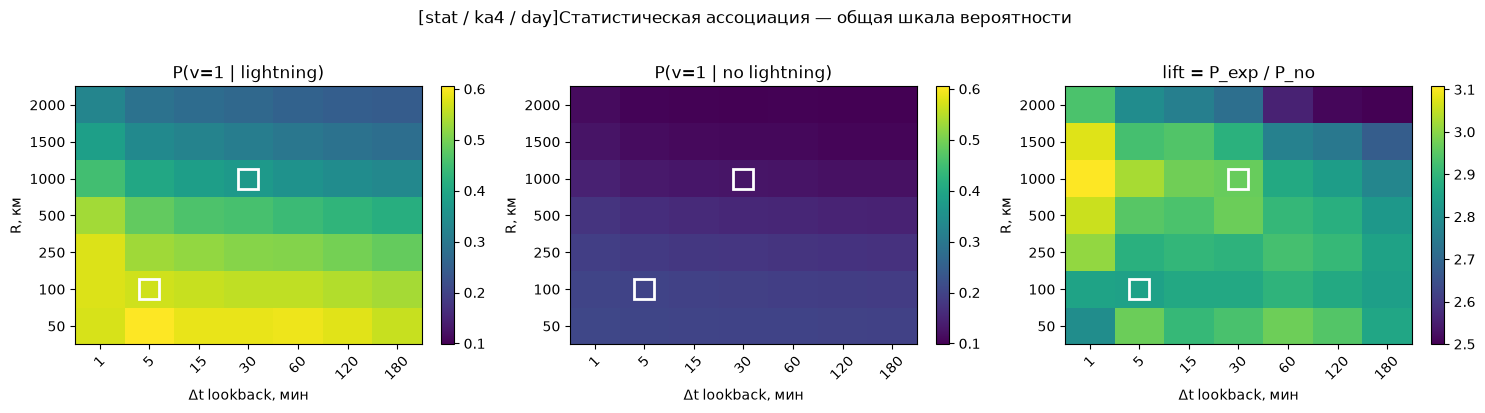

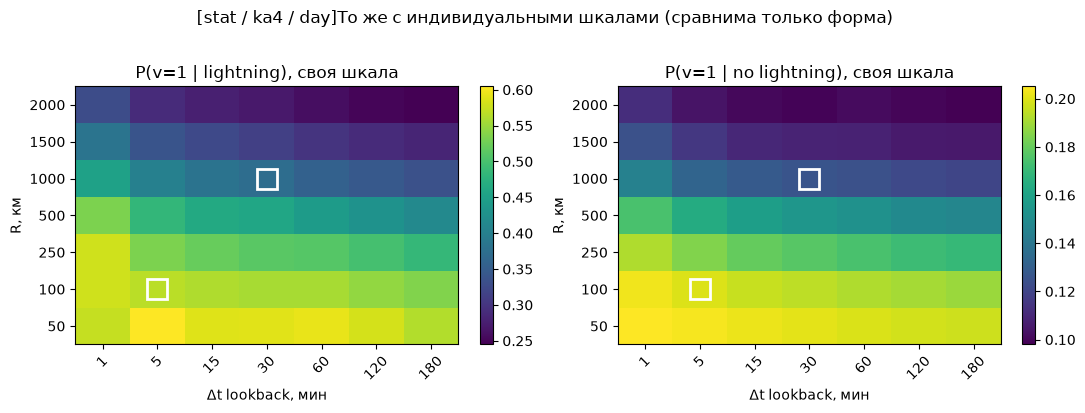

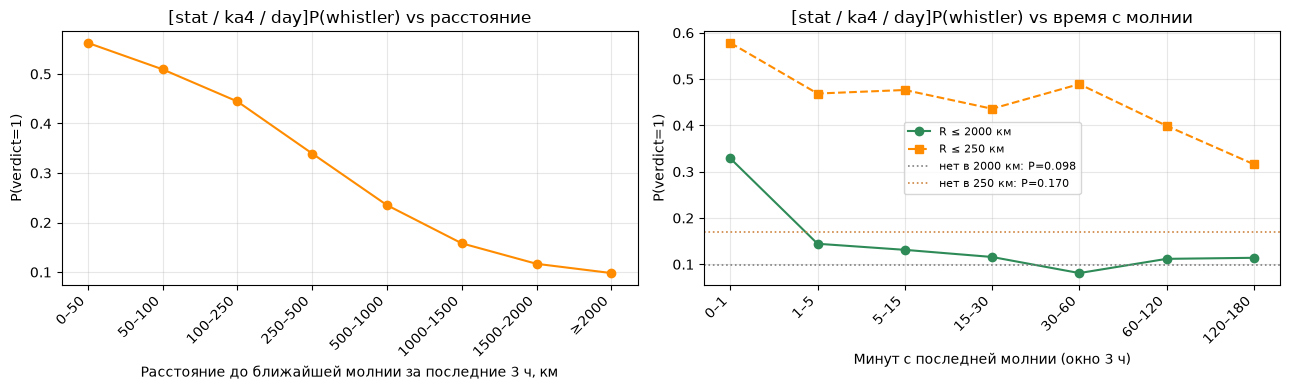

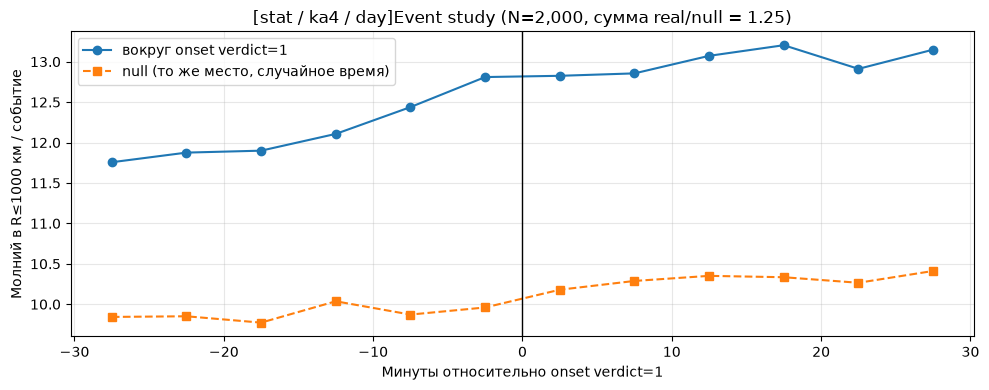

CPU times: user 34min 28s, sys: 3min 6s, total: 37min 35s
Wall time: 38min 10s


In [17]:
%%time
# Стат. контроль night/day по каждому КА. Ночь — SZA > 98° на поверхности
# (то же определение, что в блоке доза-эффект), а не is_night из файла.
# У каждого КА — свои сутки из STAT_DAYS_BY_SC.
RUN_STAT_NIGHT_DAY = True

res_s_nd = {}
if RUN_STAT_NIGHT_DAY:
    for sc_name in STAT_SC:
        days = STAT_DAYS_BY_SC.get(sc_name) or ()
        if not days:
            print(f'{sc_name}: night/day пропуск — нет суток')
            continue
        cfg_nd = wla.AssocConfig(**{**cfg_stat.__dict__, 'day_list': days, 'sc_list': (sc_name,)})
        rn = wla.run_association(cfg_nd, sc_filter=sc_name, night_filter=1, verbose=False)
        rd = wla.run_association(cfg_nd, sc_filter=sc_name, night_filter=0, verbose=False)
        res_s_nd[(sc_name, 'night')] = rn
        res_s_nd[(sc_name, 'day')] = rd
        for _R, _dt in LIFT_REF_CELLS:
            vn, vd = wla.lift_at(rn, _R, _dt), wla.lift_at(rd, _R, _dt)
            print(f'{sc_name} R={_R:.0f} Δt={_dt:.0f}: '
                  f'night lift={vn["lift"]:.2f} (P={vn["P_exp"]:.4f}/{vn["P_no"]:.4f}), '
                  f'day lift={vd["lift"]:.2f} (P={vd["P_exp"]:.4f}/{vd["P_no"]:.4f})')
        _ = wla.plot_statistical_suite(rn, title_prefix=f'[stat / {sc_name} / night]',
                                       mark_cells=LIFT_REF_CELLS)
        _ = wla.plot_statistical_suite(rd, title_prefix=f'[stat / {sc_name} / day]',
                                       mark_cells=LIFT_REF_CELLS)
else:
    print('night/day контроль пропущен (RUN_STAT_NIGHT_DAY=False)')


#### Сезонный контроль

Те же кривые `P(verdict=1)` против расстояния и против времени, в четырёх окнах года и отдельно по полушариям. В каждом окне 7 суток: с 20 января, 15 апреля, 15 июля и 15 октября. Полушария разделены, потому что за один виток аппарат пересекает оба, и в июле на севере лето, а на юге зима. Локальный сезон подписан в таблице. В этот контроль ka4 не входит: у него нет января и апреля. Берутся общие сутки ka1 и ka2.

Смотреть, держится ли `lift` в клетке 1000 км / 30 мин во всех восьми сочетаниях окна и полушария. Сам уровень `P(verdict=1)` от окна к окну меняется вместе с грозами и освещённостью. Вопрос в том, остаётся ли контраст «молния рядом» и «молнии в радиусе нет».


янв/N (20250120…20250126): lift=2.57 P_exp=0.1728 P_no=0.0672
янв/S (20250120…20250126): lift=4.26 P_exp=0.2721 P_no=0.0639
апр/N (20250415…20250421): lift=2.78 P_exp=0.2457 P_no=0.0883
апр/S (20250415…20250421): lift=3.23 P_exp=0.2304 P_no=0.0713
июл/N (20250715…20250721): lift=3.00 P_exp=0.1239 P_no=0.0413
июл/S (20250715…20250721): lift=2.18 P_exp=0.0367 P_no=0.0169
окт/N (20251015…20251021): lift=3.81 P_exp=0.1631 P_no=0.0428
окт/S (20251015…20251021): lift=3.22 P_exp=0.1655 P_no=0.0515


,окно,полушарие,локальный сезон,дни,P(есть молния),P(нет молнии),lift,n_есть,n_нет,P(база)
0,янв,N,зима,20250120…20250126,0.1728,0.0672,2.5732,9379.0,32621.0,0.0908
1,янв,S,лето,20250120…20250126,0.2721,0.0639,4.2578,10833.0,31167.0,0.1176
2,апр,N,весна,20250415…20250421,0.2457,0.0883,2.7820,12509.0,29491.0,0.1352
3,апр,S,осень,20250415…20250421,0.2304,0.0713,3.2336,11250.0,30750.0,0.1139
4,июл,N,лето,20250715…20250721,0.1239,0.0413,2.9997,22555.0,19445.0,0.0856
5,июл,S,зима,20250715…20250721,0.0367,0.0169,2.1787,6777.0,35223.0,0.0201
6,окт,N,осень,20251015…20251021,0.1631,0.0428,3.8094,14572.0,27428.0,0.0845
7,окт,S,весна,20251015…20251021,0.1655,0.0515,3.2159,8842.0,33158.0,0.0755


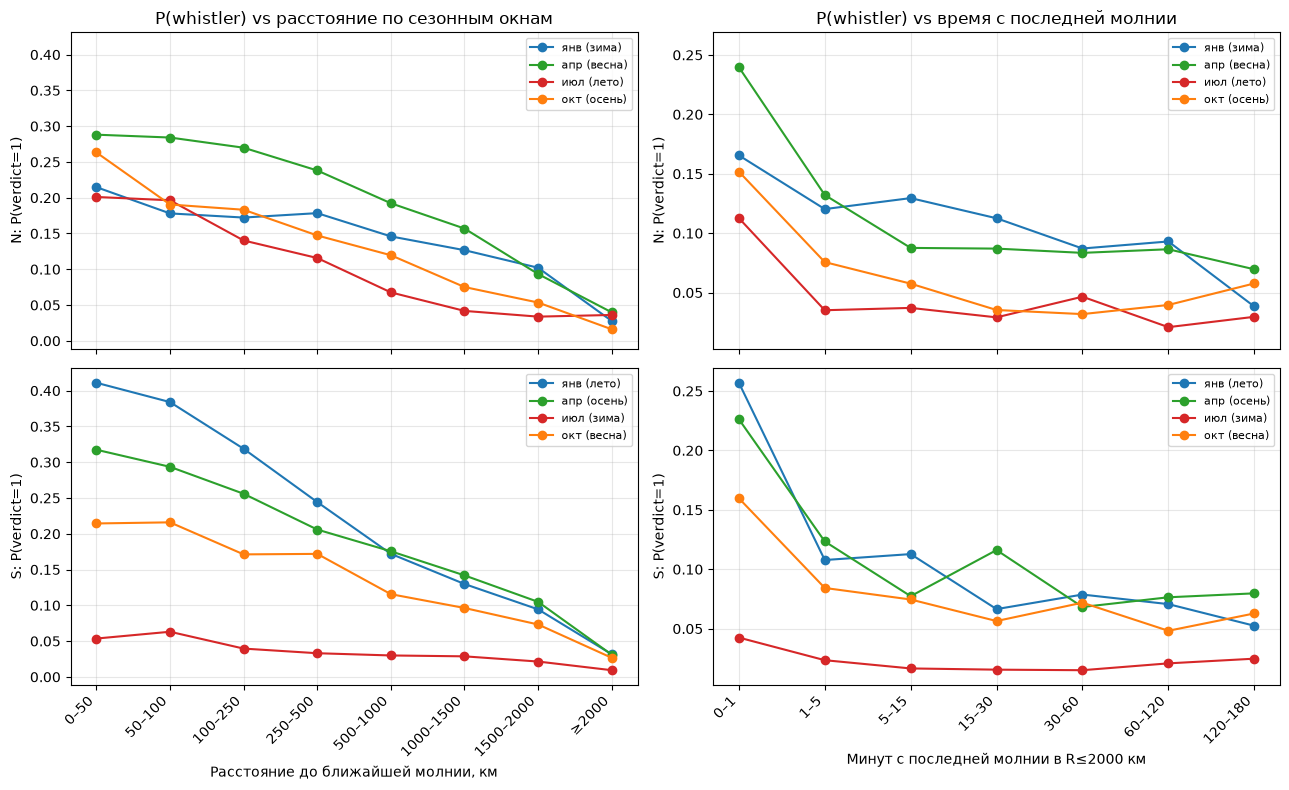

CPU times: user 9min 30s, sys: 49.4 s, total: 10min 20s
Wall time: 10min 30s


In [18]:
%%time
# Сезонный контроль: те же кривые в четырёх окнах года и отдельно по полушариям.
# Полушария разделяем обязательно: аппарат за один виток пересекает оба, и в июле
# в северном лето, а в южном зима — без разделения сезон в выборке смешан.
import matplotlib.pyplot as plt

RUN_SEASONS = True
N_SEASON_DAYS = 7          # суток в каждом окне
SEASON_PTS_PER_DAY = 6000  # 8 прогонов; ~1.9 мс на сэмпл

SEASON_STARTS = {
    'янв': '20250120', 'апр': '20250415', 'июл': '20250715', 'окт': '20251015',
}
SEASON_LOCAL = {'янв': ('зима', 'лето'), 'апр': ('весна', 'осень'),
                'июл': ('лето', 'зима'), 'окт': ('осень', 'весна')}
HEMIS = {'N': (0.0, 90.0), 'S': (-90.0, 0.0)}
SEASON_REF = (1000.0, 30.0)   # ячейка сетки, по которой сравниваем окна

res_season, season_rows = {}, []
if RUN_SEASONS:
    for tag, start in SEASON_STARTS.items():
        days = tuple(d for d in STAT_DAYS_ALL if d >= start)[:N_SEASON_DAYS]
        if len(days) < N_SEASON_DAYS:
            print(f'{tag}: в общем периоде нет {N_SEASON_DAYS} суток с {start} — пропуск')
            continue
        for hem, lat_rng in HEMIS.items():
            # сезон — только ka1∩ka2: у ka4 нет покрытия вне конца августа
            cfg_s = wla.AssocConfig(**{**cfg_stat.__dict__, 'day_list': days,
                                       'sc_list': ('ka1', 'ka2'),
                                       'lat_range': lat_rng,
                                       'max_points_per_day': SEASON_PTS_PER_DAY})
            r = wla.run_association(cfg_s, verbose=False)
            res_season[(tag, hem)] = r
            v = wla.lift_at(r, *SEASON_REF)
            season_rows.append({
                'окно': tag, 'полушарие': hem,
                'локальный сезон': SEASON_LOCAL[tag][0 if hem == 'N' else 1],
                'дни': f'{days[0]}…{days[-1]}',
                'P(есть молния)': v['P_exp'], 'P(нет молнии)': v['P_no'],
                'lift': v['lift'], 'n_есть': v['n_exp'], 'n_нет': v['n_no'],
                'P(база)': (r.dist_v1.sum() + 0.0) / max(r.dist_n.sum(), 1),
            })
            print(f'{tag}/{hem} ({days[0]}…{days[-1]}): lift={v["lift"]:.2f} '
                  f'P_exp={v["P_exp"]:.4f} P_no={v["P_no"]:.4f}', flush=True)

    season_summary = pd.DataFrame(season_rows)
    display(season_summary.round(4))

    colors = dict(zip(SEASON_STARTS, ['tab:blue', 'tab:green', 'tab:red', 'tab:orange']))
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex='col', sharey='col')
    for row, hem in enumerate(HEMIS):
        for tag in SEASON_STARTS:
            r = res_season.get((tag, hem))
            if r is None:
                continue
            lab = f'{tag} ({SEASON_LOCAL[tag][0 if hem == "N" else 1]})'
            d_lab = wla._edge_labels(r.dist_edges_km)
            axes[row, 0].plot(np.arange(len(d_lab)), r.dist_v1 / np.maximum(r.dist_n, 1),
                              'o-', color=colors[tag], label=lab)
            t_lab = wla._edge_labels(r.time_edges_min)
            axes[row, 1].plot(np.arange(len(t_lab)), r.time_v1 / np.maximum(r.time_n, 1),
                              'o-', color=colors[tag], label=lab)
        axes[row, 0].set_ylabel(f'{hem}: P(verdict=1)')
        axes[row, 1].set_ylabel(f'{hem}: P(verdict=1)')
        for ax in axes[row]:
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
    _any = next(iter(res_season.values()))
    _dl = wla._edge_labels(_any.dist_edges_km)
    axes[1, 0].set_xticks(np.arange(len(_dl)))
    axes[1, 0].set_xticklabels(_dl, rotation=45, ha='right')
    axes[1, 0].set_xlabel('Расстояние до ближайшей молнии, км')
    _tl = wla._edge_labels(_any.time_edges_min)
    axes[1, 1].set_xticks(np.arange(len(_tl)))
    axes[1, 1].set_xticklabels(_tl, rotation=45, ha='right')
    axes[1, 1].set_xlabel(f'Минут с последней молнии в R≤{max(cfg_stat.stat_r_km):.0f} км')
    axes[0, 0].set_title('P(whistler) vs расстояние по сезонным окнам')
    axes[0, 1].set_title('P(whistler) vs время с последней молнии')
    fig.tight_layout()
    plt.show()
else:
    print('сезонный контроль пропущен (RUN_SEASONS=False)')


### 3. Сводка

Таблица появляется для того блока, который в этом ядре уже выполнен.

Каузальный тест читается так: отношение «молния до / молния после» больше 1 и избыток положительный. Статистический — `lift` в двух заранее выбранных клетках, по каждому аппарату на его сутках.

`lift` больше 1 фиксирует совместную встречаемость. Ночь и география объясняют её заметную часть, поэтому ответ о связи «гроза сейчас → свист» даёт раздел доза–эффект ниже.


In [20]:
# Сводка. Каждая таблица показывается, только если её блок был выполнен.
import numpy as np
import pandas as pd


def _stat_rows(name, res):
    rows = []
    
    for _R, _dt in LIFT_REF_CELLS:
        v = wla.lift_at(res, _R, _dt)
        rows.append({
            'run': name,
            'дни': f'{res.days[0]}…{res.days[-1]} ({len(res.days)})' if res.days else '—',
            'R_км': v['R_km'], 'Δt_мин': v['dt_min'],
            'P(есть молния)': v['P_exp'], 'n_есть': v['n_exp'],
            'P(нет молнии)': v['P_no'], 'n_нет': v['n_no'],
            'lift': v['lift'],
            'N_onsets': res.n_events,
        })
    return rows


_stat_runs = []
if 'res_s' in globals() and res_s:
    _stat_runs += list(res_s.items())
else:
    for _sc in ('ka1', 'ka2', 'ka4'):
        _r = globals().get(f'res_s_{_sc}')
        if _r is not None:
            _stat_runs.append((_sc, _r))
_stat_runs += [(f'{sc}/{nd}', r) for (sc, nd), r in (globals().get('res_s_nd') or {}).items()]
_stat_runs = [(n, r) for n, r in _stat_runs if r is not None]

if _stat_runs:
    stat_summary = pd.DataFrame([r for n, res in _stat_runs for r in _stat_rows(n, res)])
    print('Статистическая ассоциация в заранее выбранных ячейках сетки:')
    print('(у каждого КА свои сутки — колонка «дни» может отличаться)')
    display(stat_summary.round(4))
else:
    print('Статистический блок не выполнялся (нет res_s_*)')

if 'causal_summary' in globals():
    print('\nКаузальный блок:')
    display(causal_summary)
else:
    print('\nКаузальный блок не выполнялся — таблица causal_summary отсутствует')

print(
    '\nЧитать так: lift > 1 означает корреляцию, а не причинность. Ночь и география\n'
    'объясняют её значительную часть, поэтому итоговый вывод даёт блок доза-эффект\n'
    'со стратификацией по (широта × местное время × сезон × ночь/день × КА).'
)


Статистическая ассоциация в заранее выбранных ячейках сетки:
(у каждого КА свои сутки — колонка «дни» может отличаться)


,run,дни,R_км,Δt_мин,P(есть молния),n_есть,P(нет молнии),n_нет,lift,N_onsets
0,ka1,20250120…20251031 (21),100.0,5.0,0.2505,2754.0,0.0808,249246.0,3.1011,4200
1,ka1,20250120…20251031 (21),1000.0,30.0,0.1646,72520.0,0.0495,179480.0,3.3219,4200
2,ka2,20250101…20251031 (21),100.0,5.0,0.3200,2591.0,0.0930,249409.0,3.4411,4200
3,ka2,20250101…20251031 (21),1000.0,30.0,0.1878,71425.0,0.0587,180575.0,3.1962,4200
4,ka4,20250821…20250831 (10),100.0,5.0,0.5110,2092.0,0.2056,117908.0,2.4854,2000
5,ka4,20250821…20250831 (10),1000.0,30.0,0.3642,38970.0,0.1372,81030.0,2.6548,2000
6,ka1/night,20250120…20251031 (21),100.0,5.0,0.3073,3775.0,0.1326,242940.0,2.3170,4200
7,ka1/night,20250120…20251031 (21),1000.0,30.0,0.2341,82606.0,0.0856,164109.0,2.7354,4200
8,ka1/day,20250120…20251031 (21),100.0,5.0,0.1528,1878.0,0.0405,246565.0,3.7775,4076
9,ka1/day,20250120…20251031 (21),1000.0,30.0,0.0968,62303.0,0.0227,186140.0,4.2604,4076



Каузальный блок не выполнялся — таблица causal_summary отсутствует

Читать так: lift > 1 означает корреляцию, а не причинность. Ночь и география
объясняют её значительную часть, поэтому итоговый вывод даёт блок доза-эффект
со стратификацией по (широта × местное время × сезон × ночь/день × КА).


## 4. Доза–эффект: вероятность свиста и сегодняшняя гроза

Кривые раздела 2 показывают, что рядом с молниями свистов больше. Это можно объяснить и тем, что и грозы, и свисты чаще в тропиках и ночью. Здесь эта путаница снимается.

**Что в ячейке сетки.** Сетка — 5 минут × 2° широты × 2° долготы. Для каждого аппарата в ячейке:

- `exposure` — сколько секунд он там был, `pos` — сколько из них с `verdict=1`, плюс сумма `prob_whistle`;
- **доза** — число молний в радиусе `DOSE_R_KM` (1000 км) за последние `DOSE_DT_MIN` (30 мин);
- средняя энергия этих молний.

**Три кривые**

| Кривая | Что показывает |
|---|---|
| **raw** | сырая доля `verdict=1` против дозы; в неё входят широта, местное время и сезон |
| **MH** | во сколько раз доля выше, чем в опорном бине «молний не было», внутри одной и той же страты `широта 15° × местное время 3 ч × сезон × ночь`; оценка Мантеля–Хензеля |
| **null** | та же оценка, но доза взята из грозовой картины других суток в этой точке (`NULL_LAGS`: 3, 7 и 14 дней) |

**Почему Мантель–Хензель.** Если усреднить долю по стратам, которые просто набрали порог экспозиции в данном бине дозы, набор страт меняется вместе с дозой: высокие дозы почти только в тропиках, и география возвращается в оценку. На синтетике с истинным ростом 2.0× такое усреднение даёт 7×, Мантель–Хензель — 2.0×. Сравнение бина с опорным идёт только по стратам, которые есть в обоих.

**Доверительный интервал** — блочный бутстрап, блок равен суткам. Секунды одного пролёта не независимы: независимых наблюдений здесь сотни дней.

**Что смотреть.** Главное отношение — `MH / null`: во сколько раз сегодняшняя гроза поднимает вероятность свиста сверх климатологии этого места и времени. Интервал, который накрывает 1, такой подъём не подтверждает. Рост одного только `MH` завышен там, где грозы в точке повторяются изо дня в день.

Аппараты в этом блоке — ka1 и ka2, общее окно суток. Следующая ячейка считает страты и кривые. Последняя — ту же оценку для средней энергии молний при уже фиксированном их числе.


In [125]:
%%time
# === Блок доза-эффект: самодостаточен, данные догружаются при необходимости ===
import gc
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
importlib.reload(wc)

# ================= параметры =================
DOSE_R_KM = 1000.0        # радиус окрестности вокруг точки трека
DOSE_DT_MIN = 30          # «молнии за последние N минут»
GLAT, GLON, GDT_MIN = 2.0, 2.0, 5      # сетка: широта, долгота, время
# Нулевая модель: доза из грозовой картины ДРУГИХ суток в той же точке и в тот же LST.
# Несколько лагов вместо одного: один лаг шумит и сохраняет многодневную
# персистентность гроз, из-за чего null завышается.
NULL_LAGS = (3, 7, 14)
MAX_LAG = max(NULL_LAGS)
DOSE_MAX_DAYS = None      # None = все дни общего периода; число = пилот
DOSE_SC = ('ka1', 'ka2')
DO_ENERGY = True          # средняя энергия молний в окрестности
NIGHT_SZA_DEG = wc.NIGHT_SZA_DEG   # ночь на поверхности, единая по ноутбуку

DOSE_EDGES = np.array([0, 1, 3, 10, 30, 100, 300, 1000, 3000, np.inf], dtype=np.float64)
DOSE_LABELS = ['0', '1–2', '3–9', '10–29', '30–99', '100–299', '300–999', '1000–2999', '≥3000']
E_EDGES = np.array([0.0, 2000.0, 6000.0, np.inf])
E_LABELS = ['<2 кДж', '2–6 кДж', '≥6 кДж']

# Единый период: сутки, где есть все КА и файл AE. AE нужен глубже — нулевой
# модели требуются сутки за MAX_LAG до начала оценки.
_paths_d = wc.resolve_paths()
DOSE_DAYS = wc.analysis_days(_paths_d['pred'], _paths_d['ae'], DOSE_SC)
if DOSE_MAX_DAYS is not None:
    DOSE_DAYS = DOSE_DAYS[:DOSE_MAX_DAYS]
_dc = wc.day_codes(DOSE_DAYS)
DOSE_DAYCODES = set(int(c) for c in _dc)
AE_DAYS = [str(np.datetime64(int(c), 'D')).replace('-', '')
           for c in range(int(_dc.min()) - MAX_LAG - 1, int(_dc.max()) + 1)]
print(f'Период оценки: {len(DOSE_DAYS)} суток ({DOSE_DAYS[0]} … {DOSE_DAYS[-1]})')

df, df_pred = wc.ensure_data(globals(), days=DOSE_DAYS, ae_days=AE_DAYS)
if 'energy' not in df.columns:
    raise ValueError('В df нет energy')

solar_zenith_deg = wc.solar_zenith_deg

# ================= сетка =================
lat_edges_d = np.arange(-90.0, 90.0 + 1e-9, GLAT)
lon_edges_d = np.arange(-180.0, 180.0 + 1e-9, GLON)
NLAT, NLON = len(lat_edges_d) - 1, len(lon_edges_d) - 1
NT = int(round(24 * 60 / GDT_MIN))
PAD = int(round(DOSE_DT_MIN / GDT_MIN))
lat_c_d = 0.5 * (lat_edges_d[:-1] + lat_edges_d[1:])
lon_c_d = 0.5 * (lon_edges_d[:-1] + lon_edges_d[1:])
NCELL = NT * NLAT * NLON

# окрестность ~R: полуширина в ячейках (по долготе зависит от широты)
hlat_d = int(np.ceil(DOSE_R_KM / 111.0 / GLAT))
hlon_d = np.ceil(
    DOSE_R_KM / (111.0 * np.maximum(np.cos(np.radians(lat_c_d)), 0.05)) / GLON
).astype(int)
hlon_d = np.minimum(hlon_d, NLON // 2)
print(f'Сетка: {NT}×{NLAT}×{NLON}; окно {DOSE_DT_MIN} мин ({PAD} бинов); '
      f'R≈{DOSE_R_KM:.0f} км → ±{hlat_d} шир. ячеек, ±{hlon_d.min()}…{hlon_d.max()} долг.')

season_order_d = list(wc.SEASON_ORDER)


def _grid(lat, lon, tmin, weights=None):
    """Раскладываем события по сетке (время × широта × долгота)."""
    ti = np.clip((tmin / GDT_MIN).astype(np.int64), 0, NT - 1)
    ii = np.clip(((lat + 90.0) / GLAT).astype(np.int64), 0, NLAT - 1)
    jj = np.clip(((lon + 180.0) / GLON).astype(np.int64), 0, NLON - 1)
    idx = (ti * NLAT + ii) * NLON + jj
    g = np.bincount(idx, weights=weights, minlength=NCELL)
    return g.reshape(NT, NLAT, NLON).astype(np.float32)


def _dose_grid(cur, prev):
    """Доза каждой ячейки дня: сумма по временному окну и по окрестности ~R.

    Окно — PAD бинов, ЗАКАНЧИВАЮЩИХСЯ текущим, т.е. `[t − DOSE_DT_MIN + GDT_MIN, t]`.
    Текущий бин включён намеренно: свист приходит через доли секунды после разряда,
    так что причинно значимые молнии лежат именно в нём. Плата — до GDT_MIN минут
    «будущего» относительно сэмпла в начале бина.
    """
    G = np.concatenate([prev[NT - PAD:], cur], axis=0)
    S = np.cumsum(G, axis=0, dtype=np.float32)
    W = S[PAD:PAD + NT] - S[0:NT]
    del G, S

    A = np.cumsum(np.concatenate([W, W, W], axis=2), axis=2, dtype=np.float32)
    L = np.empty_like(W)
    jj = np.arange(NLON)
    for i in range(NLAT):
        h = int(hlon_d[i])
        if h >= NLON // 2:
            L[:, i, :] = (A[:, i, 2 * NLON - 1] - A[:, i, NLON - 1])[:, None]
        else:
            L[:, i, :] = A[:, i, NLON + jj + h] - A[:, i, NLON + jj - h - 1]
    del A, W

    C = np.cumsum(L, axis=1, dtype=np.float32)
    ii = np.arange(NLAT)
    out = C[:, np.clip(ii + hlat_d, 0, NLAT - 1), :].copy()
    lo = ii - hlat_d - 1
    m = lo >= 0
    out[:, m, :] -= C[:, lo[m], :]
    return out


# ================= индексы дней =================
_pts = df_pred['timestamp'].values
_plat, _plon = df_pred['geo_lat'].values, df_pred['geo_lon'].values
_pver = df_pred['verdict'].values
_pprob = df_pred['prob_whistle'].values.astype(np.float64)
_psc = df_pred['sc'].astype(str).to_numpy()

pred_daycode = _pts.astype('datetime64[D]').astype(np.int64).astype(np.int32)
pred_sccode = np.where(_psc == DOSE_SC[0], 0, 1).astype(np.int8)
_key = pred_daycode.astype(np.int32) * 4 + pred_sccode
pred_order = np.argsort(_key, kind='stable')
_ks = _key[pred_order]
_uk, _us = np.unique(_ks, return_index=True)
_ue = np.append(_us[1:], len(_ks))
pred_slices = {int(k): (int(s), int(e)) for k, s, e in zip(_uk, _us, _ue)}
del _key, _ks, _psc
gc.collect()

ae_t_all = df['datetime'].values
ae_day0 = ae_t_all[0].astype('datetime64[D]').astype(np.int64)
ae_day1 = ae_t_all[-1].astype('datetime64[D]').astype(np.int64)

acc_days = sorted({int(k) // 4 for k in pred_slices} & DOSE_DAYCODES)
acc_days = [d for d in acc_days if ae_day0 <= d <= ae_day1]
acc_set = set(acc_days)
if not acc_days:
    raise ValueError('Нет суток, где есть и предсказания всех КА, и AE')
build_days = list(range(acc_days[0] - MAX_LAG - 1, acc_days[-1] + 1))
print(f'Дней с оценкой: {len(acc_days)} ({np.datetime64(acc_days[0], "D")} … '
      f'{np.datetime64(acc_days[-1], "D")}); сетки строим для {len(build_days)} дней')

# ================= накопители =================
# оси: сутки × КА × широтный пояс × LST × сезон × ночь/день × доза
# Ось суток нужна для блочного бутстрапа: соседние секунды одного пролёта
# скоррелированы, независимая единица наблюдения — сутки, а не секунда.
N_DOSE, N_EB = len(DOSE_EDGES) - 1, len(E_EDGES) - 1
N_SC, N_LATB, N_HOURB, N_SEA, N_NIGHT = len(DOSE_SC), 12, 8, 4, 2
shape6 = (N_SC, N_LATB, N_HOURB, N_SEA, N_NIGHT, N_DOSE)
day_pos = {d: i for i, d in enumerate(acc_days)}
shape7 = (len(acc_days),) + shape6
exp_true_d = np.zeros(shape7, dtype=np.float32)
pos_true_d = np.zeros(shape7, dtype=np.float32)
prb_true_d = np.zeros(shape7, dtype=np.float32)   # сумма prob_whistle — отклик без порога
exp_null_d = np.zeros(shape7, dtype=np.float32)
pos_null_d = np.zeros(shape7, dtype=np.float32)
prb_null_d = np.zeros(shape7, dtype=np.float32)
exp_en_d = np.zeros(shape7 + (N_EB,), dtype=np.float32)
pos_en_d = np.zeros(shape7 + (N_EB,), dtype=np.float32)
print(f'Накопители: {(6 * np.prod(shape7) + 2 * np.prod(shape7) * N_EB) * 4 / 2**20:.0f} МБ')

cnt_grids, en_grids = {}, {}
zero_grid = np.zeros((NT, NLAT, NLON), dtype=np.float32)

for n_done, day in enumerate(build_days, start=1):
    d0 = np.datetime64(day, 'D').astype('datetime64[ns]')
    d1 = np.datetime64(day + 1, 'D').astype('datetime64[ns]')
    s0, s1 = np.searchsorted(ae_t_all, [d0, d1])
    if s1 > s0:
        l_lat = df['lat'].values[s0:s1].astype(np.float64)
        l_lon = df['lon'].values[s0:s1].astype(np.float64)
        l_tmin = (ae_t_all[s0:s1] - d0) / np.timedelta64(1, 'm')
        cnt_grids[day] = _grid(l_lat, l_lon, l_tmin)
        if DO_ENERGY:
            en_grids[day] = _grid(l_lat, l_lon, l_tmin,
                                  weights=df['energy'].values[s0:s1].astype(np.float64))
        del l_lat, l_lon, l_tmin
    else:
        cnt_grids[day] = zero_grid.copy()
        if DO_ENERGY:
            en_grids[day] = zero_grid.copy()

    if day in acc_set:
        di = day_pos[day]
        dose_t = _dose_grid(cnt_grids[day], cnt_grids.get(day - 1, zero_grid)).ravel()
        dose_nulls = [_dose_grid(cnt_grids[nd], cnt_grids.get(nd - 1, zero_grid)).ravel()
                      for nd in (day - L for L in NULL_LAGS) if nd in cnt_grids]
        dose_e = (_dose_grid(en_grids[day], en_grids.get(day - 1, zero_grid)).ravel()
                  if DO_ENERGY else None)

        month = int(str(np.datetime64(day, 'D'))[5:7])
        for si, sc in enumerate(DOSE_SC):
            sl = pred_slices.get(day * 4 + si)
            if sl is None:
                continue
            idx = pred_order[sl[0]:sl[1]]
            lat = _plat[idx].astype(np.float64)
            lon = _plon[idx].astype(np.float64)
            ver = _pver[idx]
            prb = _pprob[idx]
            tt = _pts[idx]
            tmin = (tt - tt.astype('datetime64[D]')) / np.timedelta64(1, 'm')
            night = (solar_zenith_deg(tt, lat, lon) > NIGHT_SZA_DEG).astype(np.int8)

            exp_g = _grid(lat, lon, tmin).ravel()
            pos_g = _grid(lat[ver == 1], lon[ver == 1], tmin[ver == 1]).ravel()
            prb_g = _grid(lat, lon, tmin, weights=prb).ravel()
            # ночь считаем по ячейке: доля ночных сэмплов > 0.5
            ngt_g = _grid(lat, lon, tmin, weights=night.astype(np.float64)).ravel()
            cells = np.flatnonzero(exp_g > 0)
            if cells.size == 0:
                continue

            ti = cells // (NLAT * NLON)
            rem = cells % (NLAT * NLON)
            lat_cc = lat_c_d[rem // NLON]
            lon_cc = lon_c_d[rem % NLON]
            lst = np.mod(ti * GDT_MIN / 60.0 + GDT_MIN / 120.0 + lon_cc / 15.0, 24.0)
            hourb = np.clip((lst / 3.0).astype(np.int64), 0, N_HOURB - 1)
            latb = np.clip(((lat_cc + 90.0) / 15.0).astype(np.int64), 0, N_LATB - 1)
            nightb = (ngt_g[cells] / exp_g[cells] > 0.5).astype(np.int64)
            _, seab = wc.season_index(lat_cc, month)
            seab = seab.astype(np.int64)

            e_vals, p_vals, b_vals = exp_g[cells], pos_g[cells], prb_g[cells]
            dt_cells = dose_t[cells]
            db_t = np.clip(np.searchsorted(DOSE_EDGES, dt_cells, side='right') - 1, 0, N_DOSE - 1)
            key_t = (di, si, latb, hourb, seab, nightb, db_t)
            np.add.at(exp_true_d, key_t, e_vals)
            np.add.at(pos_true_d, key_t, p_vals)
            np.add.at(prb_true_d, key_t, b_vals)

            for dose_n in dose_nulls:
                db_n = np.clip(np.searchsorted(DOSE_EDGES, dose_n[cells], side='right') - 1,
                               0, N_DOSE - 1)
                key_n = (di, si, latb, hourb, seab, nightb, db_n)
                np.add.at(exp_null_d, key_n, e_vals)
                np.add.at(pos_null_d, key_n, p_vals)
                np.add.at(prb_null_d, key_n, b_vals)

            if dose_e is not None:
                mean_e = np.divide(dose_e[cells], dt_cells,
                                   out=np.zeros(cells.size), where=dt_cells > 0)
                eb = np.clip(np.searchsorted(E_EDGES, mean_e, side='right') - 1, 0, N_EB - 1)
                key_e = (di, si, latb, hourb, seab, nightb, db_t, eb)
                np.add.at(exp_en_d, key_e, e_vals)
                np.add.at(pos_en_d, key_e, p_vals)

        del dose_t, dose_nulls, dose_e

    for old in [k for k in cnt_grids if k < day - MAX_LAG - 1]:
        cnt_grids.pop(old, None)
    for old in [k for k in en_grids if k < day - 1]:
        en_grids.pop(old, None)
    if n_done % 20 == 0:
        print(f'  ... {n_done}/{len(build_days)} дней', flush=True)
        gc.collect()

del cnt_grids, en_grids
gc.collect()

# агрегаты по всем суткам — для кривых; дневная ось остаётся для бутстрапа
exp_true = exp_true_d.sum(axis=0, dtype=np.float64)
pos_true = pos_true_d.sum(axis=0, dtype=np.float64)
exp_null = exp_null_d.sum(axis=0, dtype=np.float64)
pos_null = pos_null_d.sum(axis=0, dtype=np.float64)
exp_en = exp_en_d.sum(axis=0, dtype=np.float64)
pos_en = pos_en_d.sum(axis=0, dtype=np.float64)

print(f'Готово. Экспозиция: {exp_true.sum():,.0f} сэмплов, verdict=1: {pos_true.sum():,.0f} '
      f'({100 * pos_true.sum() / max(exp_true.sum(), 1):.2f}%), '
      f'средняя prob {prb_true_d.sum() / max(exp_true.sum(), 1):.4f}; '
      f'ночных сэмплов {100 * exp_true[:, :, :, :, 1].sum() / max(exp_true.sum(), 1):.1f}%')
print(f'Экспозиция null: {exp_null.sum():,.0f} (= {len(NULL_LAGS)} лага × реальная)')


Период оценки: 255 суток (20250120 … 20251031)
Сетка: 288×90×180; окно 30 мин (6 бинов); R≈1000 км → ±5 шир. ячеек, ±5…90 долг.
Дней с оценкой: 255 (2025-01-20 … 2025-10-31); сетки строим для 300 дней
Накопители: 161 МБ
  ... 20/300 дней
  ... 40/300 дней
  ... 60/300 дней
  ... 80/300 дней
  ... 100/300 дней
  ... 120/300 дней
  ... 140/300 дней
  ... 160/300 дней
  ... 180/300 дней
  ... 200/300 дней
  ... 220/300 дней
  ... 240/300 дней
  ... 260/300 дней
  ... 280/300 дней
  ... 300/300 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%), средняя prob 0.1066; ночных сэмплов 43.5%
Экспозиция null: 125,955,108 (= 3 лага × реальная)
CPU times: user 5min 11s, sys: 2min 25s, total: 7min 37s
Wall time: 8min 13s


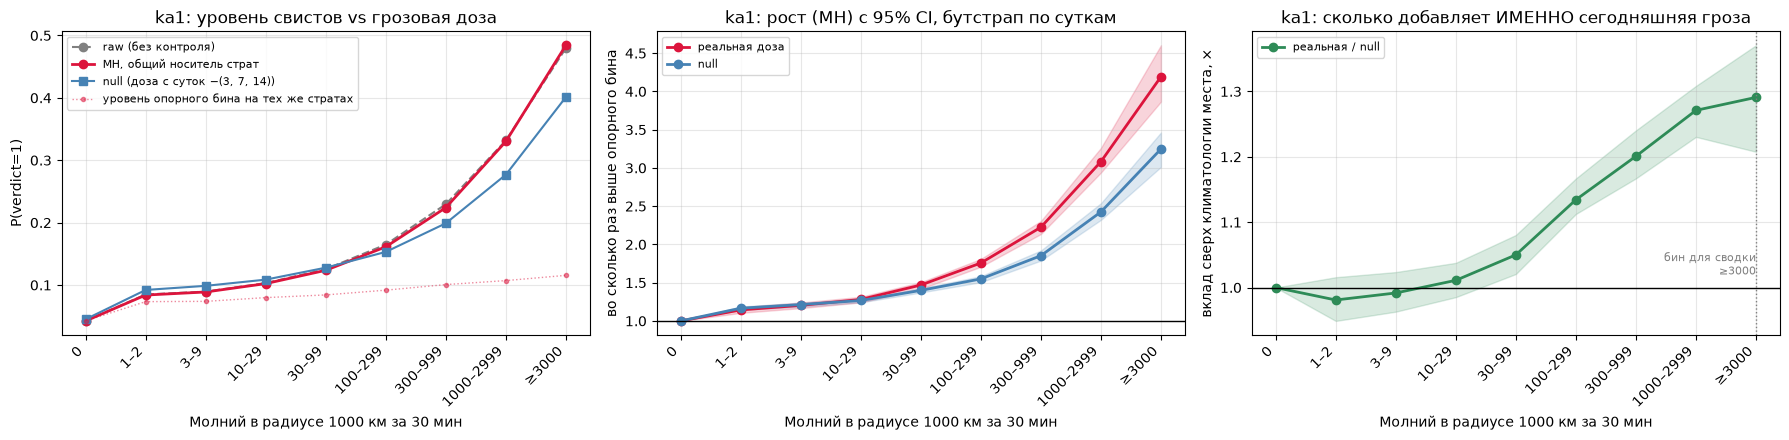

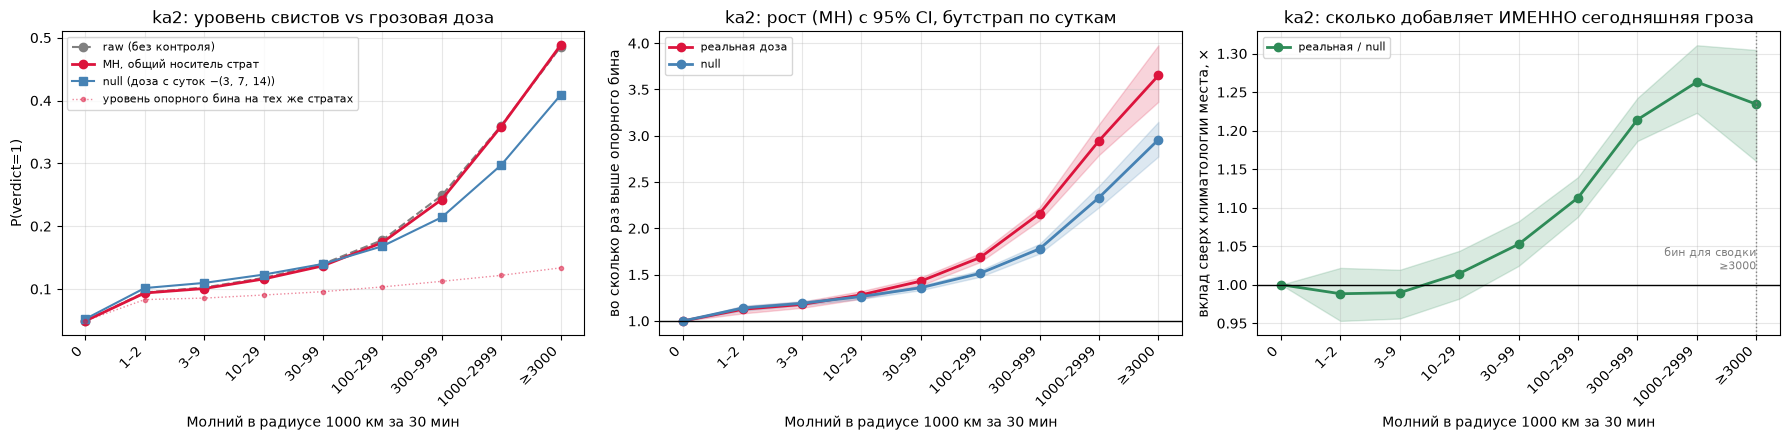

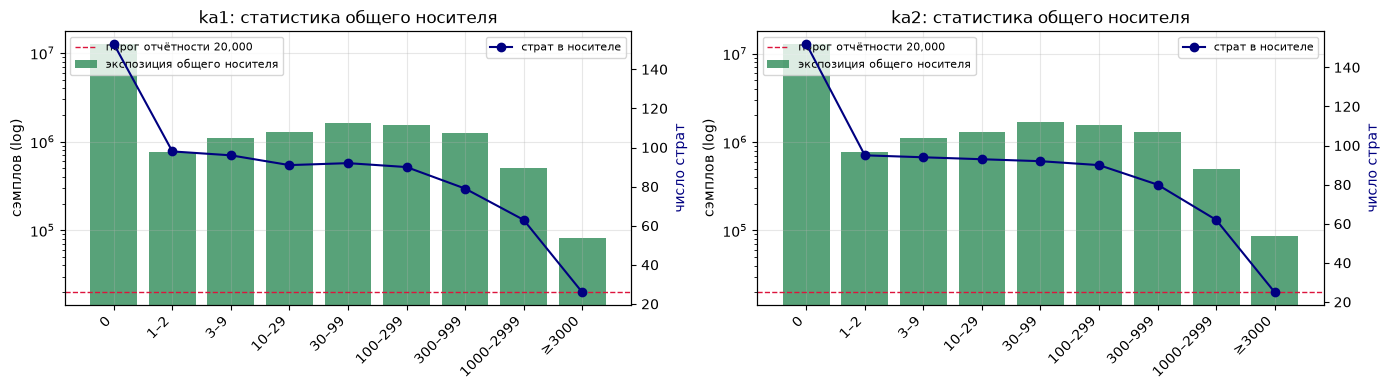

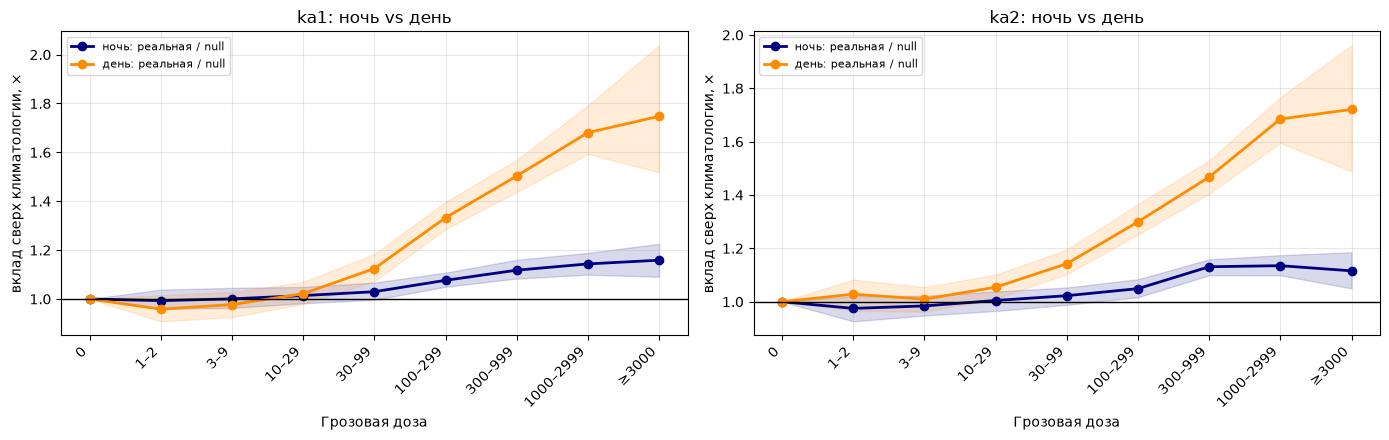

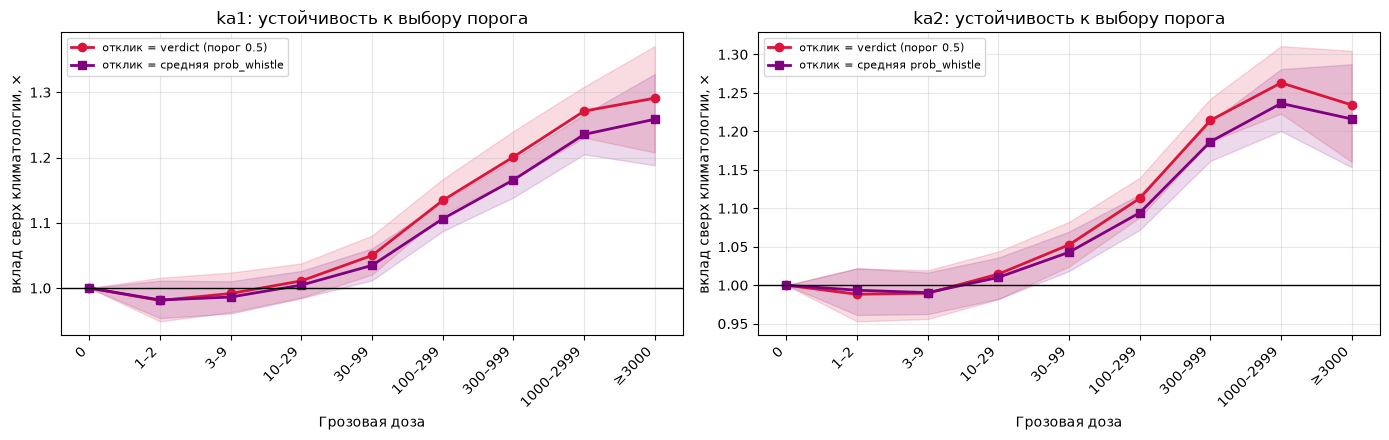

In [126]:
import warnings

import matplotlib.pyplot as plt

MIN_STRAT_EXP = 500    # мин. экспозиция страты в бине дозы
MIN_REPORT_EXP = 20000  # мин. экспозиция общего носителя, чтобы бин попал в сводку
N_BOOT = 200           # реплик блочного бутстрапа (блок = сутки)
REF_BIN = 0            # опорный бин: молний в окрестности нет


def _strata(a, sc=None, night=None, day_axis=False):
    """Схлопывает оси условий в индекс страты: (страты × последняя ось),
    при day_axis=True — (сутки × страты × последняя ось)."""
    o = 1 if day_axis else 0
    x = a[:, [sc]] if (day_axis and sc is not None) else (a[[sc]] if sc is not None else a)
    if night is not None:
        x = x[(slice(None),) * (o + 4) + ([night],)]
    return x.reshape((x.shape[0], -1, x.shape[-1]) if day_axis else (-1, x.shape[-1]))


def _mh(E, P, ref=REF_BIN, min_exp=MIN_STRAT_EXP):
    """Mantel–Haenszel: отношение уровней «бин k / опорный бин» внутри страт,
    представленных в ОБОИХ бинах.

    Зачем: если просто усреднить P по стратам, прошедшим порог в бине k, то набор
    страт меняется вместе с дозой (высокие дозы бывают почти только в тропиках),
    и в оценку роста возвращается тот самый конфаундер. На синтетике с истинным
    ростом 2.0× такое усреднение даёт 7×, MH — ровно 2.0×.
    """
    nb = E.shape[1]
    rr = np.full(nb, np.nan)
    p_ref = np.full(nb, np.nan)
    p_k = np.full(nb, np.nan)
    nst = np.zeros(nb, dtype=np.int64)
    expo = np.zeros(nb)
    ok = E >= min_exp
    for k in range(nb):
        m = ok[:, ref] & ok[:, k]
        if not m.any():
            continue
        e0, e1 = E[m, ref].astype(np.float64), E[m, k].astype(np.float64)
        p0, p1 = P[m, ref].astype(np.float64), P[m, k].astype(np.float64)
        tot = e0 + e1
        w = e0 * e1 / tot
        den = (p0 * e1 / tot).sum()
        rr[k] = (p1 * e0 / tot).sum() / den if den > 0 else np.nan
        p_ref[k] = (p0 / e0 * w).sum() / w.sum()
        p_k[k] = (p1 / e1 * w).sum() / w.sum()
        nst[k] = int(m.sum())
        expo[k] = e1.sum()
    return rr, p_ref, p_k, nst, expo


def _pooled(E, P):
    """Сырое P без всякого контроля — для сравнения."""
    s_e, s_p = E.sum(axis=0), P.sum(axis=0)
    return np.where(s_e > 0, s_p / np.where(s_e > 0, s_e, 1), np.nan)


def analyze(sc=None, night=None, outcome='verdict', n_boot=N_BOOT, seed=0):
    """Кривая доза–эффект с контролем страт, нулевой моделью и блочным бутстрапом.

    Блок бутстрапа — сутки: соседние секунды одного пролёта сильно скоррелированы,
    независимых наблюдений здесь ~сотни (дни), а не 43 млн (секунды).
    """
    Pt_d, Pn_d = ((pos_true_d, pos_null_d) if outcome == 'verdict'
                  else (prb_true_d, prb_null_d))
    Et = _strata(exp_true_d, sc, night, day_axis=True)
    Pt = _strata(Pt_d, sc, night, day_axis=True)
    En = _strata(exp_null_d, sc, night, day_axis=True)
    Pn = _strata(Pn_d, sc, night, day_axis=True)

    rr_t, p0_t, pk_t, nst, expo = _mh(Et.sum(axis=0), Pt.sum(axis=0))
    rr_n, p0_n, pk_n, nst_n, _ = _mh(En.sum(axis=0), Pn.sum(axis=0))

    rng = np.random.default_rng(seed)
    nd, nb = Et.shape[0], Et.shape[2]
    bt = np.full((n_boot, nb), np.nan)
    bn = np.full((n_boot, nb), np.nan)
    for b in range(n_boot):
        c = np.bincount(rng.integers(0, nd, nd), minlength=nd).astype(np.float32)
        bt[b] = _mh(np.tensordot(c, Et, axes=1), np.tensordot(c, Pt, axes=1))[0]
        bn[b] = _mh(np.tensordot(c, En, axes=1), np.tensordot(c, Pn, axes=1))[0]

    with np.errstate(invalid='ignore', divide='ignore'), warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)   # бины без данных дают all-NaN
        brrr = bt / bn

        def q(a):
            return np.nanpercentile(a, [2.5, 97.5], axis=0)

        ci_t, ci_n, ci_rrr = q(bt), q(bn), q(brrr)
    return {
        'rr_t': rr_t, 'rr_n': rr_n, 'rrr': rr_t / rr_n,
        'ci_t': ci_t, 'ci_n': ci_n, 'ci_rrr': ci_rrr,
        'p0_t': p0_t, 'pk_t': pk_t, 'p0_n': p0_n, 'pk_n': pk_n,
        'nst': nst, 'expo': expo,
        'raw': _pooled(_strata(exp_true_d, sc, night, True).sum(axis=0),
                       _strata(Pt_d, sc, night, True).sum(axis=0)),
    }


def report_bin(res, min_exp=MIN_REPORT_EXP, min_strata=5):
    """Верхний бин дозы, на который можно ссылаться: хватает и экспозиции, и страт.
    None — если ни один бин не проходит (лучше пустая строка, чем цифра из воздуха)."""
    ok = (np.isfinite(res['rr_t']) & np.isfinite(res['rr_n'])
          & (res['expo'] >= min_exp) & (res['nst'] >= min_strata))
    ok[REF_BIN] = False
    idx = np.flatnonzero(ok)
    return int(idx[-1]) if idx.size else None


x = np.arange(N_DOSE)
RES = {}
for si, sc in enumerate(DOSE_SC):
    RES[sc] = analyze(sc=si)
    r = RES[sc]
    rb = report_bin(r)

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    axes[0].plot(x, r['raw'], 'o--', color='gray', lw=1.5, label='raw (без контроля)')
    axes[0].plot(x, r['pk_t'], 'o-', color='crimson', lw=2, label='MH, общий носитель страт')
    axes[0].plot(x, r['pk_n'], 's-', color='steelblue', label=f'null (доза с суток −{NULL_LAGS})')
    axes[0].plot(x, r['p0_t'], '.:', color='crimson', alpha=0.5, lw=1,
                 label='уровень опорного бина на тех же стратах')
    axes[0].set_ylabel('P(verdict=1)')
    axes[0].set_title(f'{sc}: уровень свистов vs грозовая доза')

    for key, ci, color, lab in [('rr_t', 'ci_t', 'crimson', 'реальная доза'),
                                ('rr_n', 'ci_n', 'steelblue', 'null')]:
        axes[1].plot(x, r[key], 'o-', color=color, lw=2, label=lab)
        axes[1].fill_between(x, r[ci][0], r[ci][1], color=color, alpha=0.18)
    axes[1].axhline(1.0, color='k', lw=1)
    axes[1].set_ylabel('во сколько раз выше опорного бина')
    axes[1].set_title(f'{sc}: рост (MH) с 95% CI, бутстрап по суткам')

    axes[2].plot(x, r['rrr'], 'o-', color='seagreen', lw=2, label='реальная / null')
    axes[2].fill_between(x, r['ci_rrr'][0], r['ci_rrr'][1], color='seagreen', alpha=0.18)
    axes[2].axhline(1.0, color='k', lw=1)
    if rb is not None:
        axes[2].axvline(rb, color='gray', ls=':', lw=1)
        axes[2].annotate(f'бин для сводки\n{DOSE_LABELS[rb]}', (rb, 1.02), fontsize=8,
                         color='gray', ha='right')
    axes[2].set_ylabel('вклад сверх климатологии места, ×')
    axes[2].set_title(f'{sc}: сколько добавляет ИМЕННО сегодняшняя гроза')

    for ax in axes:
        ax.set_xticks(x)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# --- сколько статистики стоит за каждой точкой ---
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    r = RES[sc]
    ax.bar(x, r['expo'], color='seagreen', alpha=0.8, label='экспозиция общего носителя')
    ax.axhline(MIN_REPORT_EXP, color='crimson', ls='--', lw=1,
               label=f'порог отчётности {MIN_REPORT_EXP:,}')
    ax.set_yscale('log')
    ax.set_ylabel('сэмплов (log)')
    ax2 = ax.twinx()
    ax2.plot(x, r['nst'], 'o-', color='navy', lw=1.5, label='страт в носителе')
    ax2.set_ylabel('число страт', color='navy')
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
    ax.set_title(f'{sc}: статистика общего носителя')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='upper left')
    ax2.legend(fontsize=8, loc='upper right')
fig.tight_layout()
plt.show()
plt.close(fig)

# --- ночь / день ---
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    for ni, lab, color in [(1, 'ночь', 'navy'), (0, 'день', 'darkorange')]:
        r = analyze(sc=si, night=ni)
        RES[(sc, lab)] = r
        ax.plot(x, r['rrr'], 'o-', color=color, lw=2, label=f'{lab}: реальная / null')
        ax.fill_between(x, r['ci_rrr'][0], r['ci_rrr'][1], color=color, alpha=0.15)
    ax.axhline(1.0, color='k', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
    ax.set_xlabel('Грозовая доза')
    ax.set_ylabel('вклад сверх климатологии, ×')
    ax.set_title(f'{sc}: ночь vs день')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

# --- отклик без порога: средняя prob_whistle вместо доли verdict=1 ---
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    rv = RES[sc]
    rp = analyze(sc=si, outcome='prob')
    RES[(sc, 'prob')] = rp
    ax.plot(x, rv['rrr'], 'o-', color='crimson', lw=2, label='отклик = verdict (порог 0.5)')
    ax.fill_between(x, rv['ci_rrr'][0], rv['ci_rrr'][1], color='crimson', alpha=0.15)
    ax.plot(x, rp['rrr'], 's-', color='purple', lw=2, label='отклик = средняя prob_whistle')
    ax.fill_between(x, rp['ci_rrr'][0], rp['ci_rrr'][1], color='purple', alpha=0.15)
    ax.axhline(1.0, color='k', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
    ax.set_xlabel('Грозовая доза')
    ax.set_ylabel('вклад сверх климатологии, ×')
    ax.set_title(f'{sc}: устойчивость к выбору порога')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)


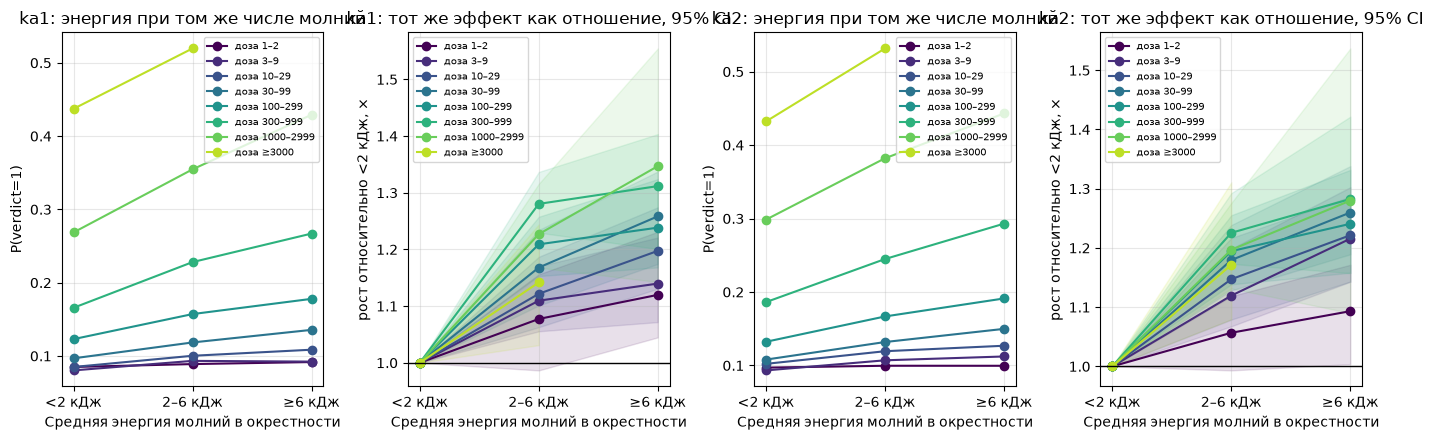

,КА,условия,бин дозы,экспозиция,страт,P(опорный),P(бин),рост MH,CI рост,рост null,сверх null,CI сверх null,рост raw
0,ka1,все,≥3000,81630,26,0.116,0.484,4.192,3.87–4.60,3.247,1.291,1.21–1.37,11.292000
1,ka1,ночь,≥3000,53779,16,0.157,0.495,3.147,2.89–3.37,2.716,1.159,1.09–1.23,6.728000
2,ka1,день,≥3000,27851,10,0.042,0.465,11.117,9.78–12.33,6.362,1.747,1.52–2.04,20.695000
3,ka2,все,≥3000,86127,25,0.134,0.488,3.651,3.37–3.98,2.958,1.234,1.16–1.30,9.862000
4,ka2,ночь,≥3000,58207,17,0.174,0.489,2.805,2.61–3.04,2.514,1.116,1.05–1.19,6.091000
5,ka2,день,≥3000,27920,8,0.056,0.487,8.656,7.35–9.78,5.030,1.721,1.49–1.96,16.665001


R=1000 км, Δt=30 мин (окно кончается текущим 5-мин бином), дней=255, null-лаги=(3, 7, 14) сут, MIN_STRAT_EXP=500, ночь: SZA>98°, бутстрап: 200 реплик по суткам
«рост MH» — сравнение внутри одинаковых страт (широта×LST×сезон×ночь).
«сверх null» — во сколько раз сегодняшняя гроза добавляет к тому, что даёт
одна лишь климатология места: значимо, если CI не накрывает 1.0.


In [127]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd


def analyze_energy(si, db, n_boot=N_BOOT, seed=0):
    """Эффект средней энергии молний при ФИКСИРОВАННОМ их числе (бин дозы db).
    Контроль здесь — сама фиксация дозы плюс страты; нулевой модели нет."""
    E = _strata(exp_en_d[..., db, :], sc=si, day_axis=True)
    P = _strata(pos_en_d[..., db, :], sc=si, day_axis=True)
    rr, p_ref, p_k, nst, expo = _mh(E.sum(axis=0), P.sum(axis=0))
    rng = np.random.default_rng(seed)
    nd = E.shape[0]
    bs = np.full((n_boot, E.shape[2]), np.nan)
    for b in range(n_boot):
        c = np.bincount(rng.integers(0, nd, nd), minlength=nd).astype(np.float32)
        bs[b] = _mh(np.tensordot(c, E, axes=1), np.tensordot(c, P, axes=1))[0]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        ci = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    return rr, ci, p_k, nst, expo


# --- влияние энергии при фиксированном числе молний ---
show_bins = [i for i in range(1, N_DOSE)
             if _strata(exp_en_d[..., i, :], day_axis=True).sum() > 50 * MIN_STRAT_EXP]
if show_bins:
    fig, axes = plt.subplots(1, 2 * len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5))
    for si, sc in enumerate(DOSE_SC):
        ax_a, ax_r = axes[2 * si], axes[2 * si + 1]
        cmap = plt.cm.viridis(np.linspace(0, 0.9, len(show_bins)))
        for ci, db in enumerate(show_bins):
            rr, ci95, p_k, nst, _ = analyze_energy(si, db)
            ax_a.plot(np.arange(N_EB), p_k, 'o-', color=cmap[ci], label=f'доза {DOSE_LABELS[db]}')
            ax_r.plot(np.arange(N_EB), rr, 'o-', color=cmap[ci], label=f'доза {DOSE_LABELS[db]}')
            ax_r.fill_between(np.arange(N_EB), ci95[0], ci95[1], color=cmap[ci], alpha=0.12)
        ax_r.axhline(1.0, color='k', lw=1)
        ax_a.set_ylabel('P(verdict=1)')
        ax_r.set_ylabel('рост относительно <2 кДж, ×')
        ax_a.set_title(f'{sc}: энергия при том же числе молний')
        ax_r.set_title(f'{sc}: тот же эффект как отношение, 95% CI')
        for ax in (ax_a, ax_r):
            ax.set_xticks(np.arange(N_EB))
            ax.set_xticklabels(E_LABELS)
            ax.set_xlabel('Средняя энергия молний в окрестности')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# --- сводка ---
rows = []
for si, sc in enumerate(DOSE_SC):
    for night, hlab in [(None, 'все'), (1, 'ночь'), (0, 'день')]:
        r = RES.get((sc, hlab)) if night is not None else RES.get(sc)
        if r is None:
            r = analyze(sc=si, night=night)
        k = report_bin(r)
        if k is None:
            rows.append({'КА': sc, 'условия': hlab, 'бин дозы': 'нет носителя'})
            continue
        rows.append({
            'КА': sc,
            'условия': hlab,
            'бин дозы': DOSE_LABELS[k],
            'экспозиция': int(r['expo'][k]),
            'страт': int(r['nst'][k]),
            'P(опорный)': r['p0_t'][k],
            'P(бин)': r['pk_t'][k],
            'рост MH': r['rr_t'][k],
            'CI рост': f"{r['ci_t'][0, k]:.2f}–{r['ci_t'][1, k]:.2f}",
            'рост null': r['rr_n'][k],
            'сверх null': r['rrr'][k],
            'CI сверх null': f"{r['ci_rrr'][0, k]:.2f}–{r['ci_rrr'][1, k]:.2f}",
            'рост raw': r['raw'][k] / r['raw'][REF_BIN],
        })
dose_summary = pd.DataFrame(rows)
display(dose_summary.round(3))

print(f'R={DOSE_R_KM:.0f} км, Δt={DOSE_DT_MIN} мин (окно кончается текущим {GDT_MIN}-мин бином), '
      f'дней={len(acc_days)}, null-лаги={NULL_LAGS} сут, MIN_STRAT_EXP={MIN_STRAT_EXP}, '
      f'ночь: SZA>{NIGHT_SZA_DEG:.0f}°, бутстрап: {N_BOOT} реплик по суткам')
print('«рост MH» — сравнение внутри одинаковых страт (широта×LST×сезон×ночь).')
print('«сверх null» — во сколько раз сегодняшняя гроза добавляет к тому, что даёт')
print('одна лишь климатология места: значимо, если CI не накрывает 1.0.')
